In [1]:
#v2: copy of parallel_trend_visualisations.ipynb
#- vertical line at the exact date the minimum wage came into force
#- same axes for all plots, so the cantons can be compared directly
#- relative path instead of %cd, so the notebook runs on every computer
#  (run it from the folder "Visualisations")

import pandas as pd
import matplotlib.pyplot as plt


In [2]:
data = pd.read_csv("../Crime_Pop_clean.csv")
print(data.head())


             Canton  Year         Type of Residence  Resident Population  \
0            Aargau  2010  Ständige Wohnbevölkerung                79369   
1  Basel-Landschaft  2010  Ständige Wohnbevölkerung                30893   
2       Basel-Stadt  2010  Ständige Wohnbevölkerung                24488   
3              Bern  2010  Ständige Wohnbevölkerung               120344   
4          Freiburg  2010  Ständige Wohnbevölkerung                36620   

   Total Residential Population  Percentage of Total Resident Population  \
0                       1006333                                 7.886952   
1                       1006333                                 3.069859   
2                       1006333                                 2.433389   
3                       1006333                                11.958666   
4                       1006333                                 3.638955   

  Age group  Number of Accused Persons  AccusedRate  
0     20-29                     

Text(0, 0.5, 'AccusedRate')

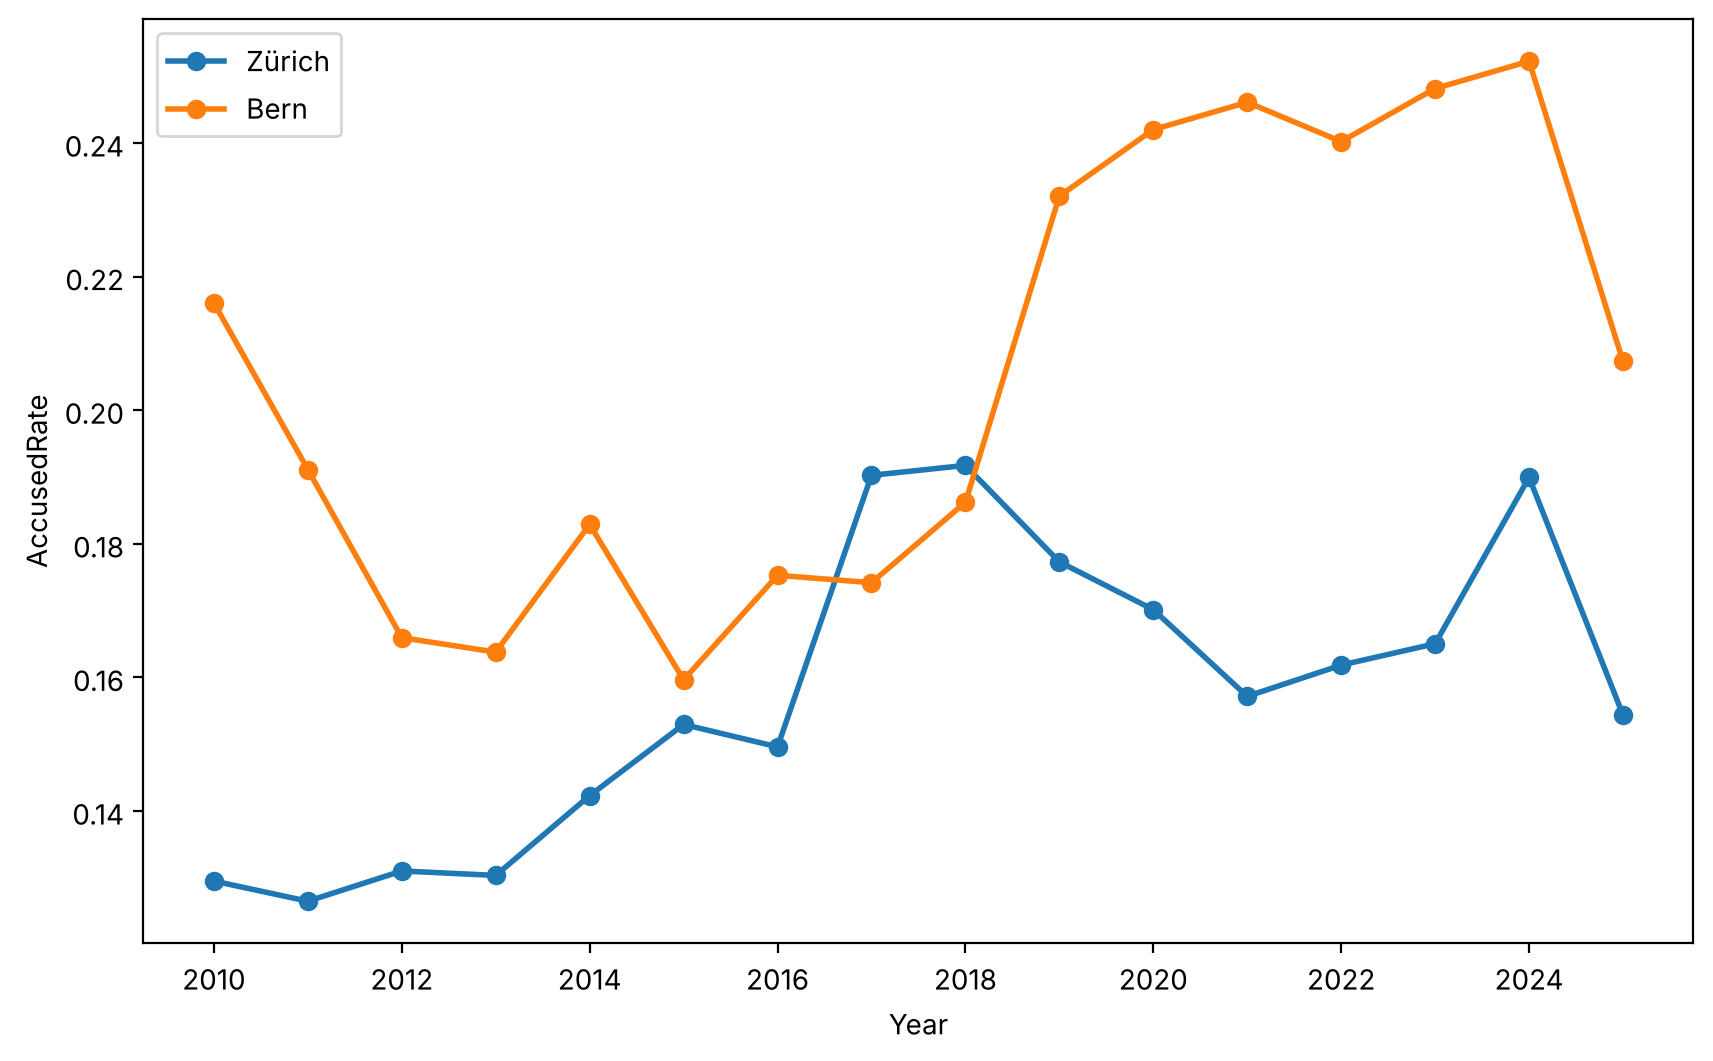

In [3]:
#creating example

canton1 = 'Zürich'
canton2 = 'Bern'

subset = data[data['Canton'].isin([canton1, canton2])] #extracts a subset of your merged dataset by filtering for rows where the value in the 'Kanton' column matches either canton1 or canton2

plt.figure(figsize=(10, 6)) #created canvas with dimensions 10 (x-axis), 6(y-axis)

for canton in [canton1, canton2]:
  canton_data = subset[subset['Canton'] == canton]
  plt.plot(
      canton_data['Year'], canton_data['AccusedRate'],
      marker='o', linewidth=2, #circle for datapoints connecting with line (2-pixel thick)
      label=canton) #lable with cantons 

plt.legend() #creating a legend

plt.xlabel('Year')
plt.ylabel('AccusedRate')



In [4]:
#preparation for creating a loop

unique_cantons = data['Canton'].unique()
print(unique_cantons)

#creating touples of cantons (no doubles)
import itertools

canton_pairs = list(itertools.combinations(unique_cantons, 2)) #itertools.combinations(..., 2) for paring every item with every other item in the list in groups of 2, ensuring that no canton is paired with itself

print(canton_pairs)

<StringArray>
[          'Aargau', 'Basel-Landschaft',      'Basel-Stadt',
             'Bern',         'Freiburg',             'Genf',
           'Luzern',        'Neuenburg',        'Solothurn',
       'St. Gallen',          'Thurgau',            'Waadt',
           'Wallis',           'Zürich']
Length: 14, dtype: str
[('Aargau', 'Basel-Landschaft'), ('Aargau', 'Basel-Stadt'), ('Aargau', 'Bern'), ('Aargau', 'Freiburg'), ('Aargau', 'Genf'), ('Aargau', 'Luzern'), ('Aargau', 'Neuenburg'), ('Aargau', 'Solothurn'), ('Aargau', 'St. Gallen'), ('Aargau', 'Thurgau'), ('Aargau', 'Waadt'), ('Aargau', 'Wallis'), ('Aargau', 'Zürich'), ('Basel-Landschaft', 'Basel-Stadt'), ('Basel-Landschaft', 'Bern'), ('Basel-Landschaft', 'Freiburg'), ('Basel-Landschaft', 'Genf'), ('Basel-Landschaft', 'Luzern'), ('Basel-Landschaft', 'Neuenburg'), ('Basel-Landschaft', 'Solothurn'), ('Basel-Landschaft', 'St. Gallen'), ('Basel-Landschaft', 'Thurgau'), ('Basel-Landschaft', 'Waadt'), ('Basel-Landschaft', 'Wallis'), ('B

In [5]:
#only keeping pairs of which one canton at least introduced minimum wage laws at some point in time
#minimum wage introduced in Neuenburg, Jura, Genf, Tessin, Basel-Stadt --> we only have Neuenburg, Genf, Basel-Stadt in our dataset

target_cantons = ["Neuenburg", "Genf", "Basel-Stadt"]

# 2. Filter your canton_pairs list
combinations = [
    pair for pair in canton_pairs #
    if any(canton in target_cantons for canton in pair)] #any(...) checks if at least one of the cantons in the current pair is present, only keeps those


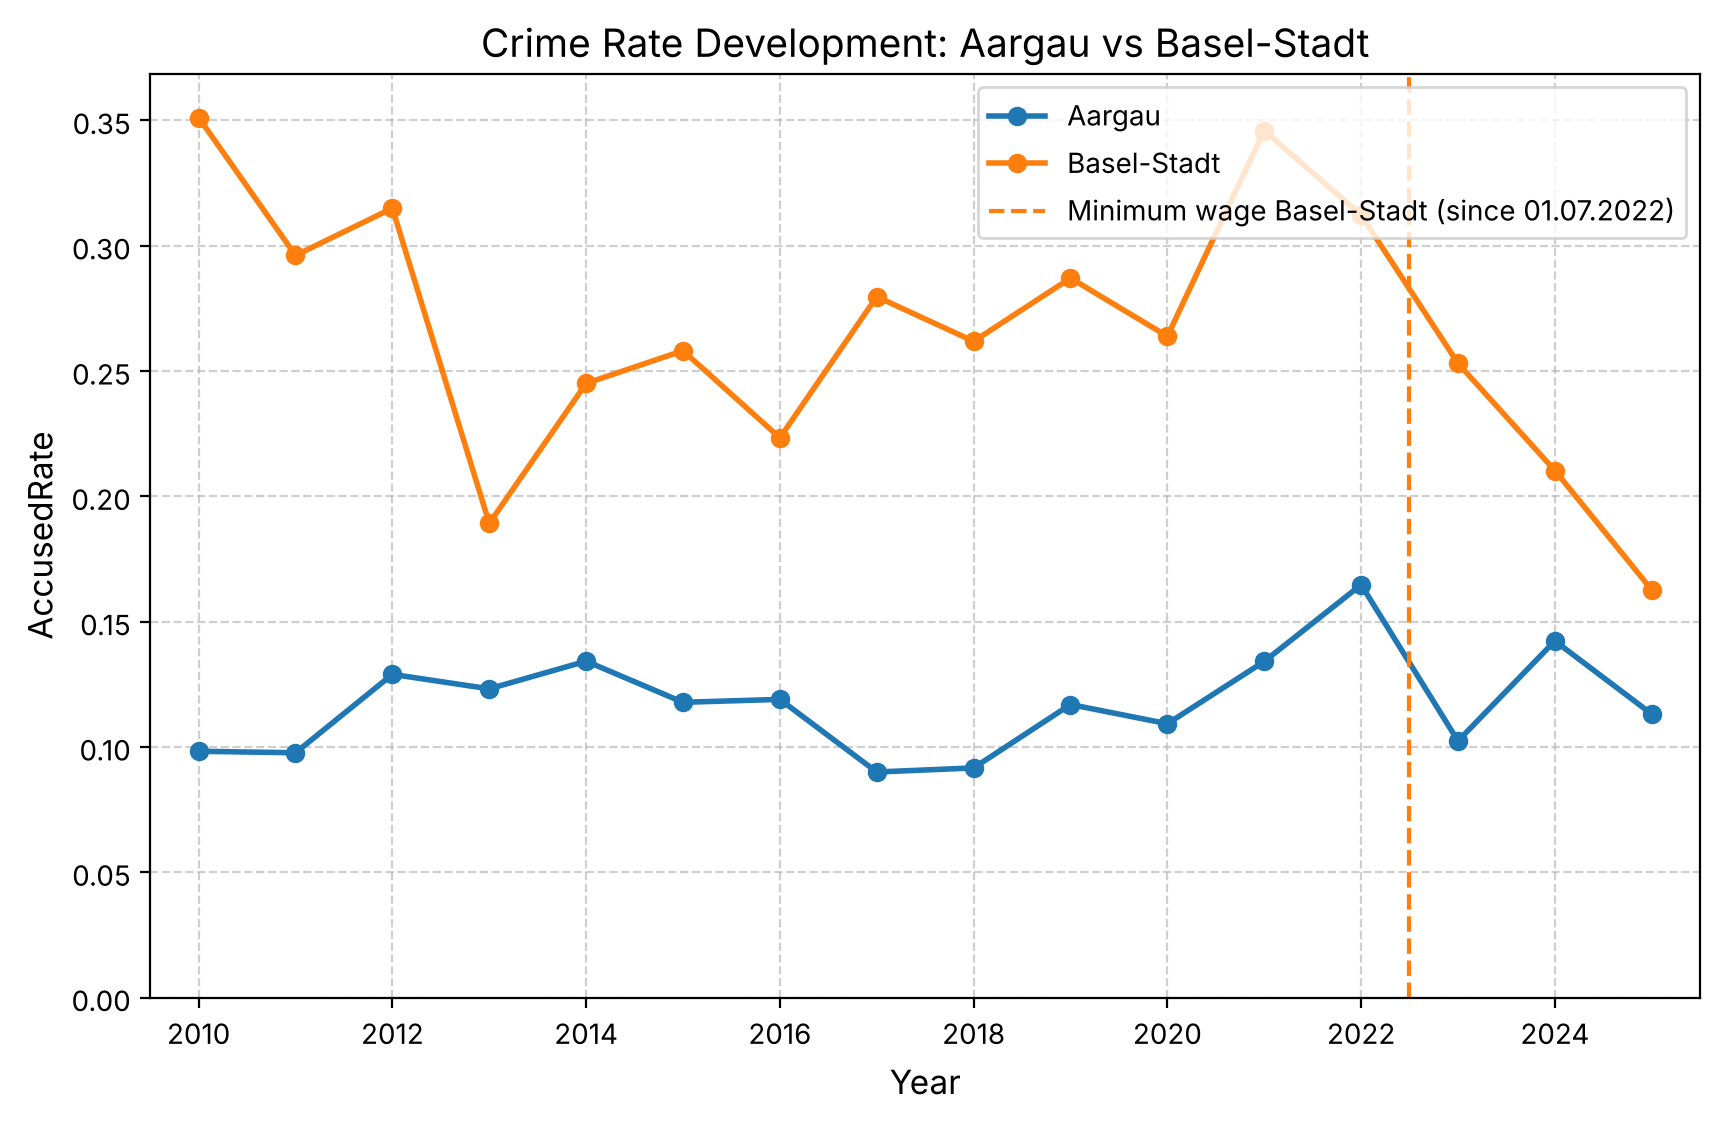

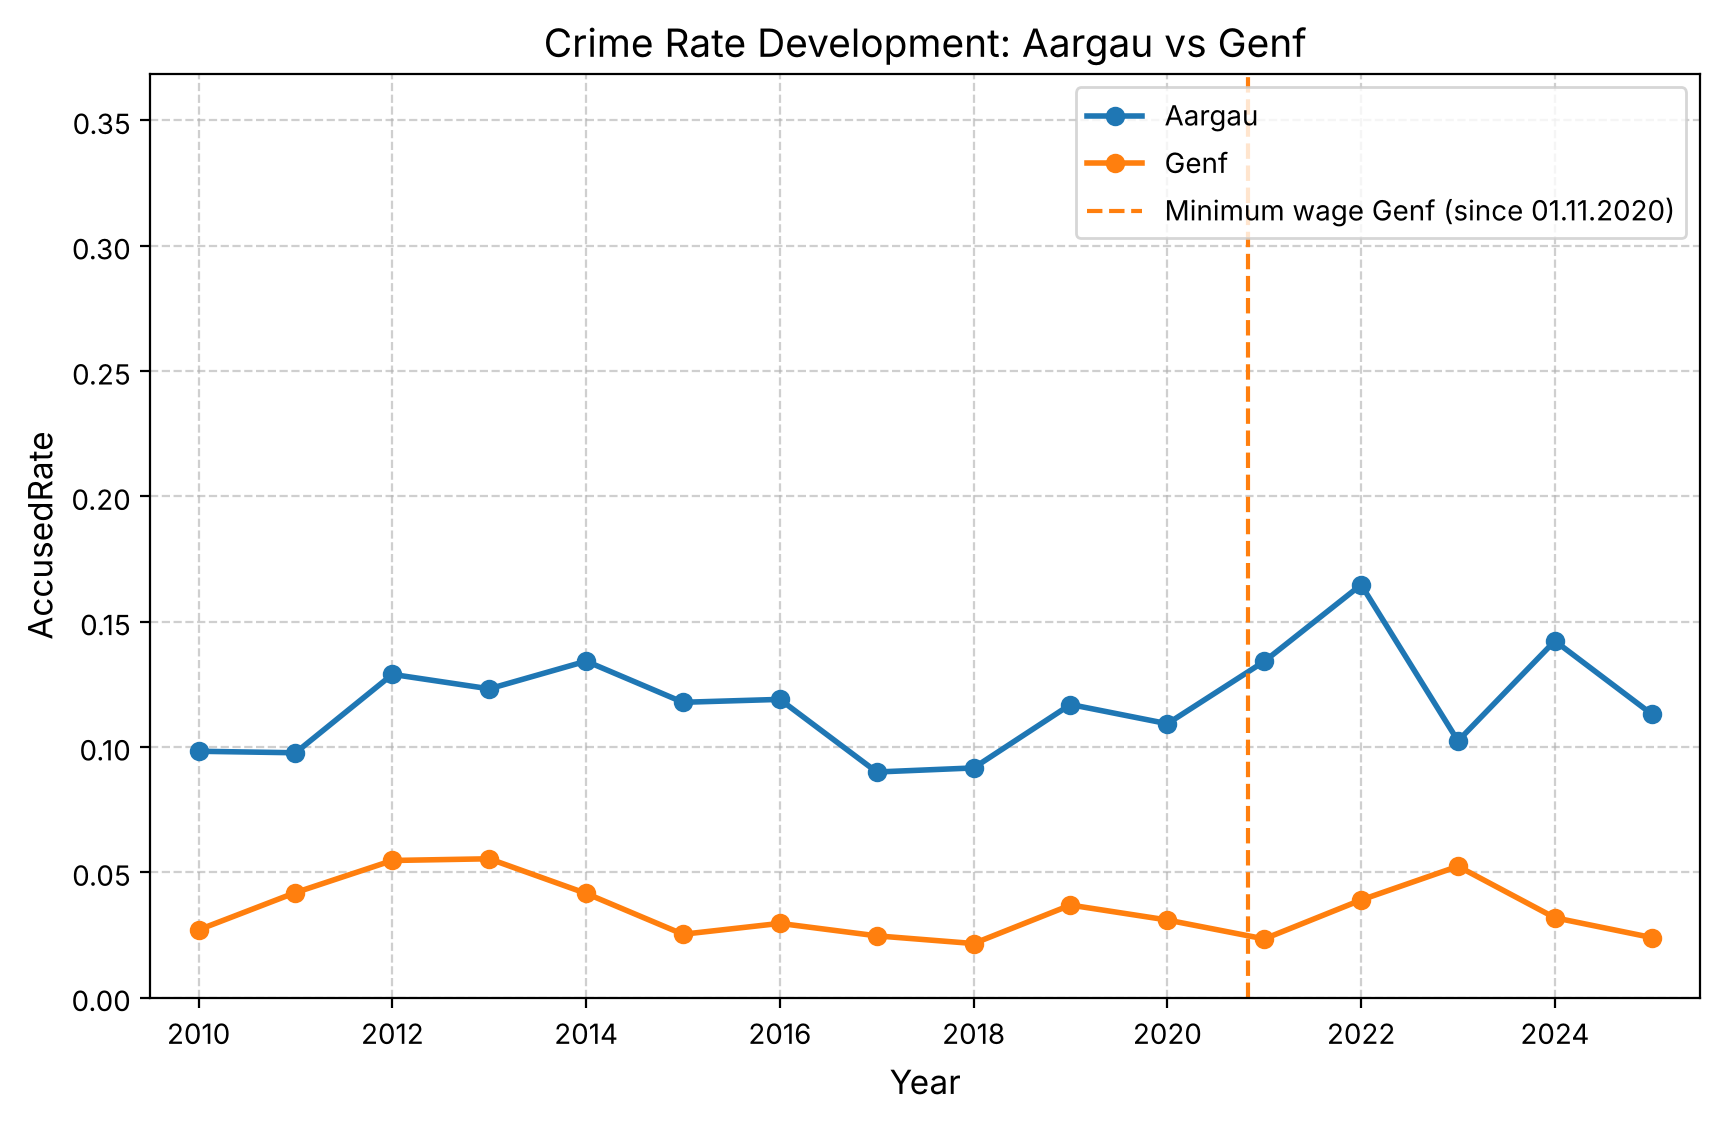

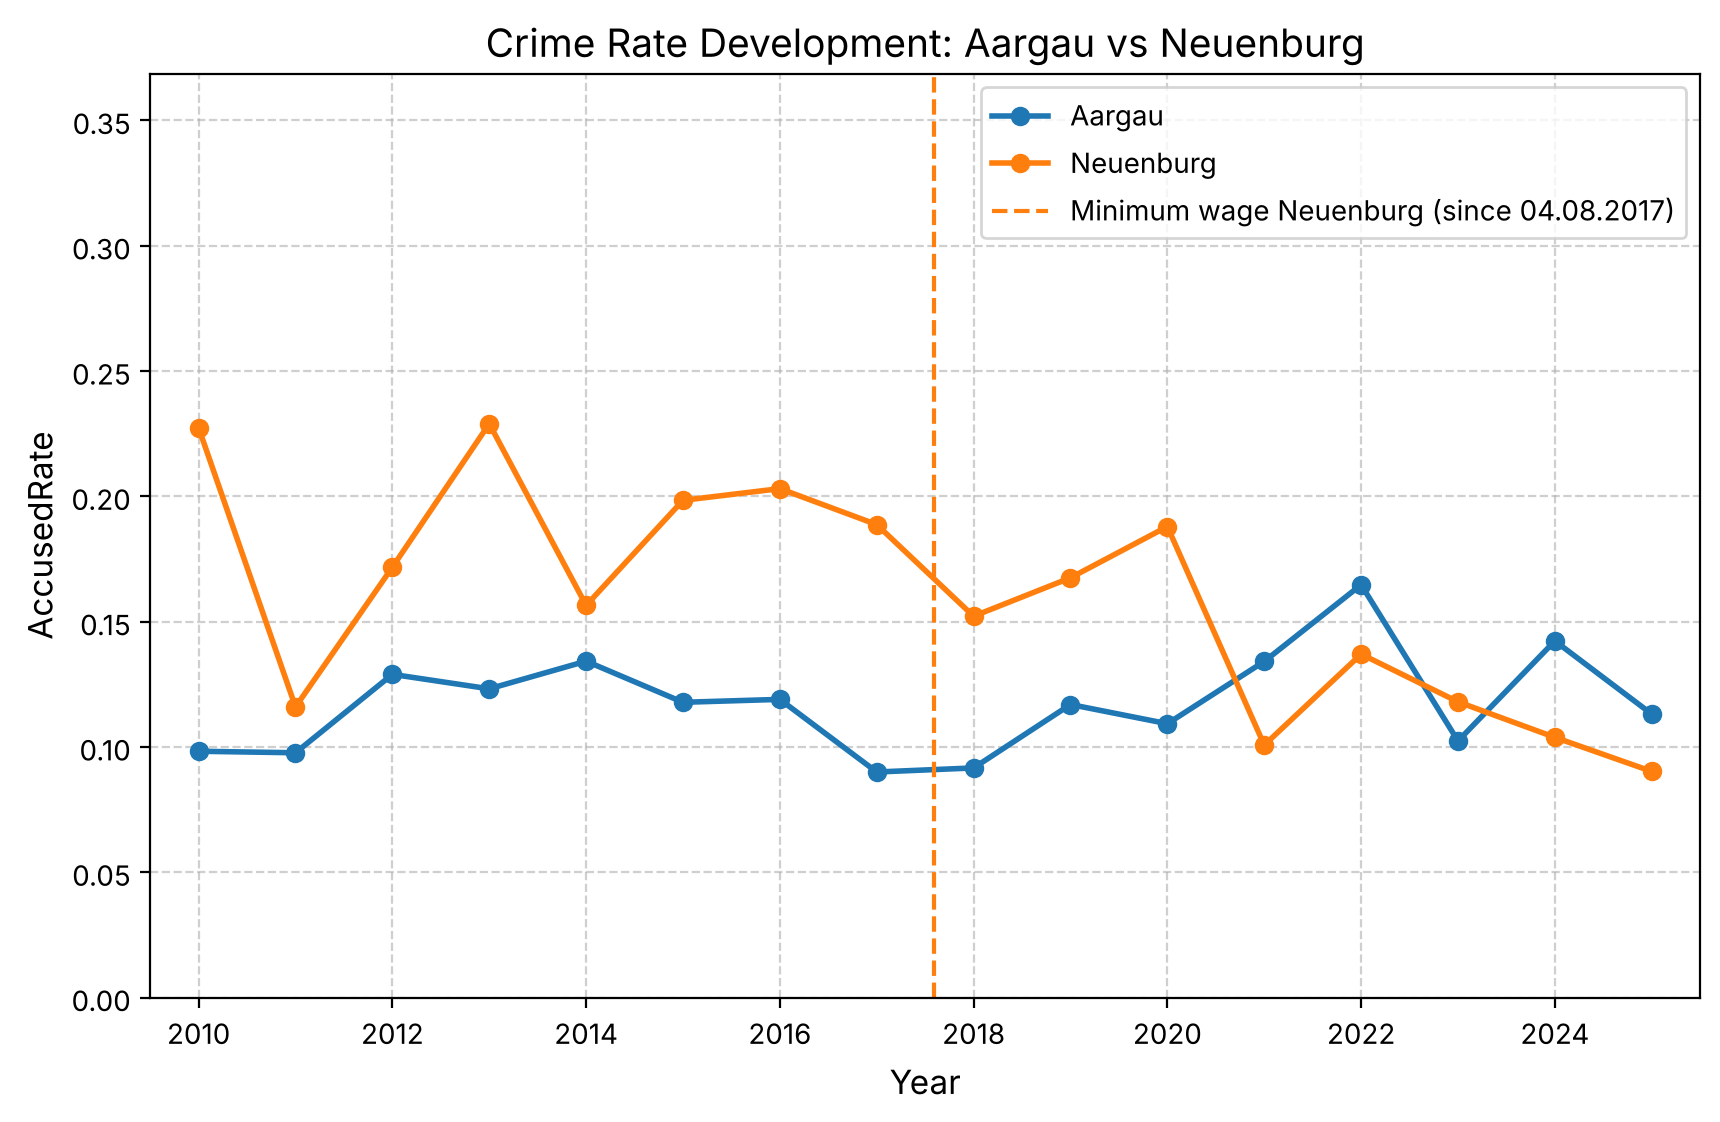

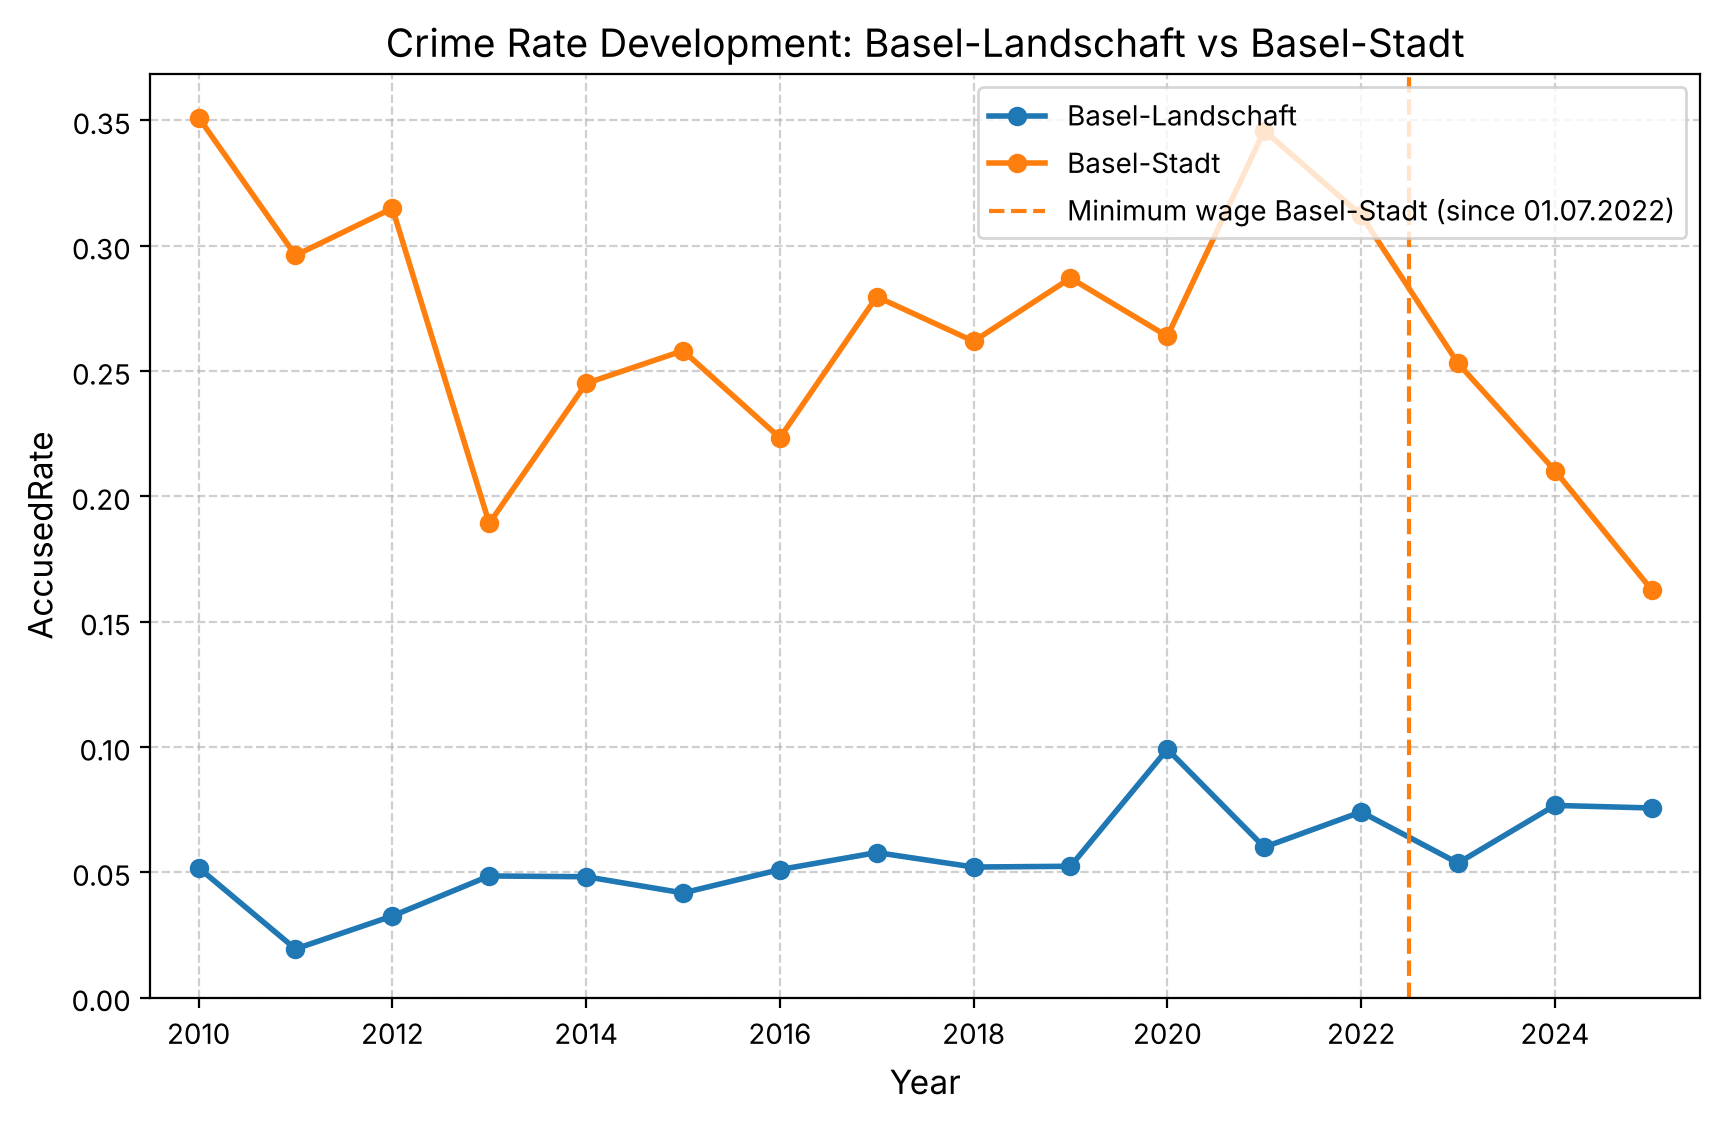

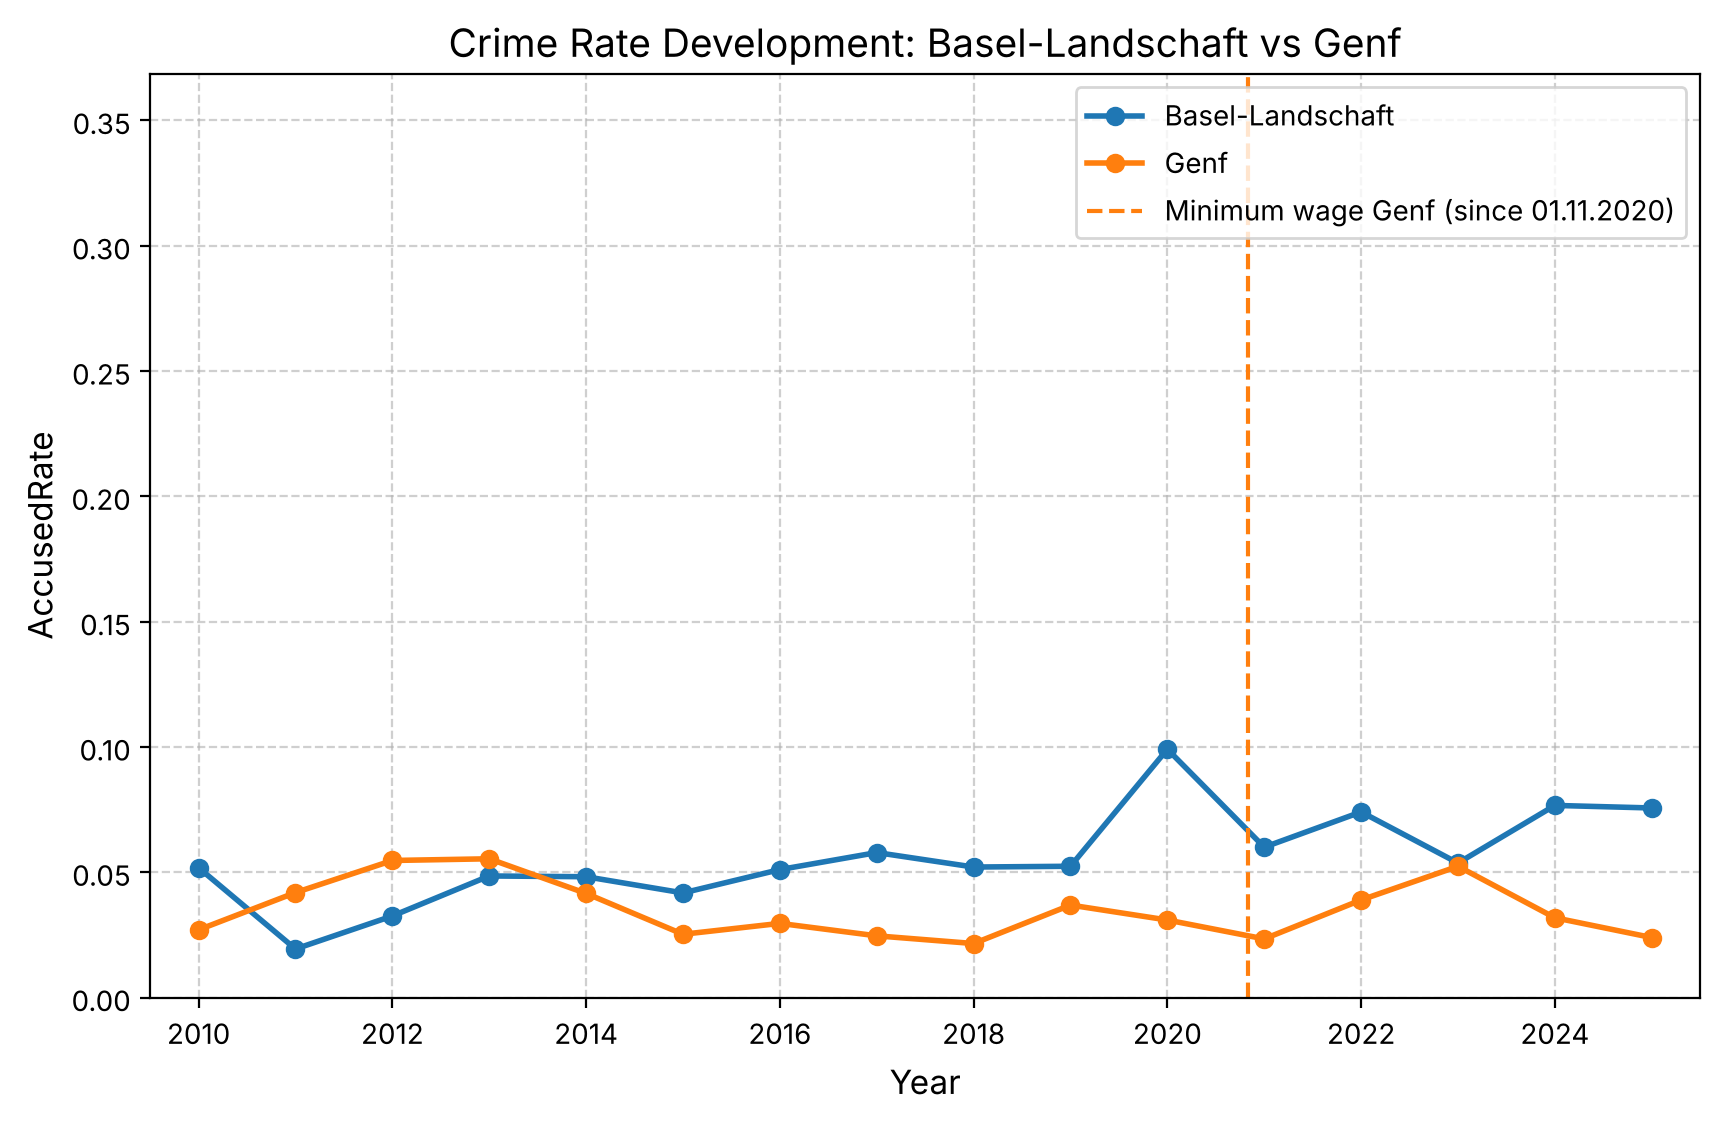

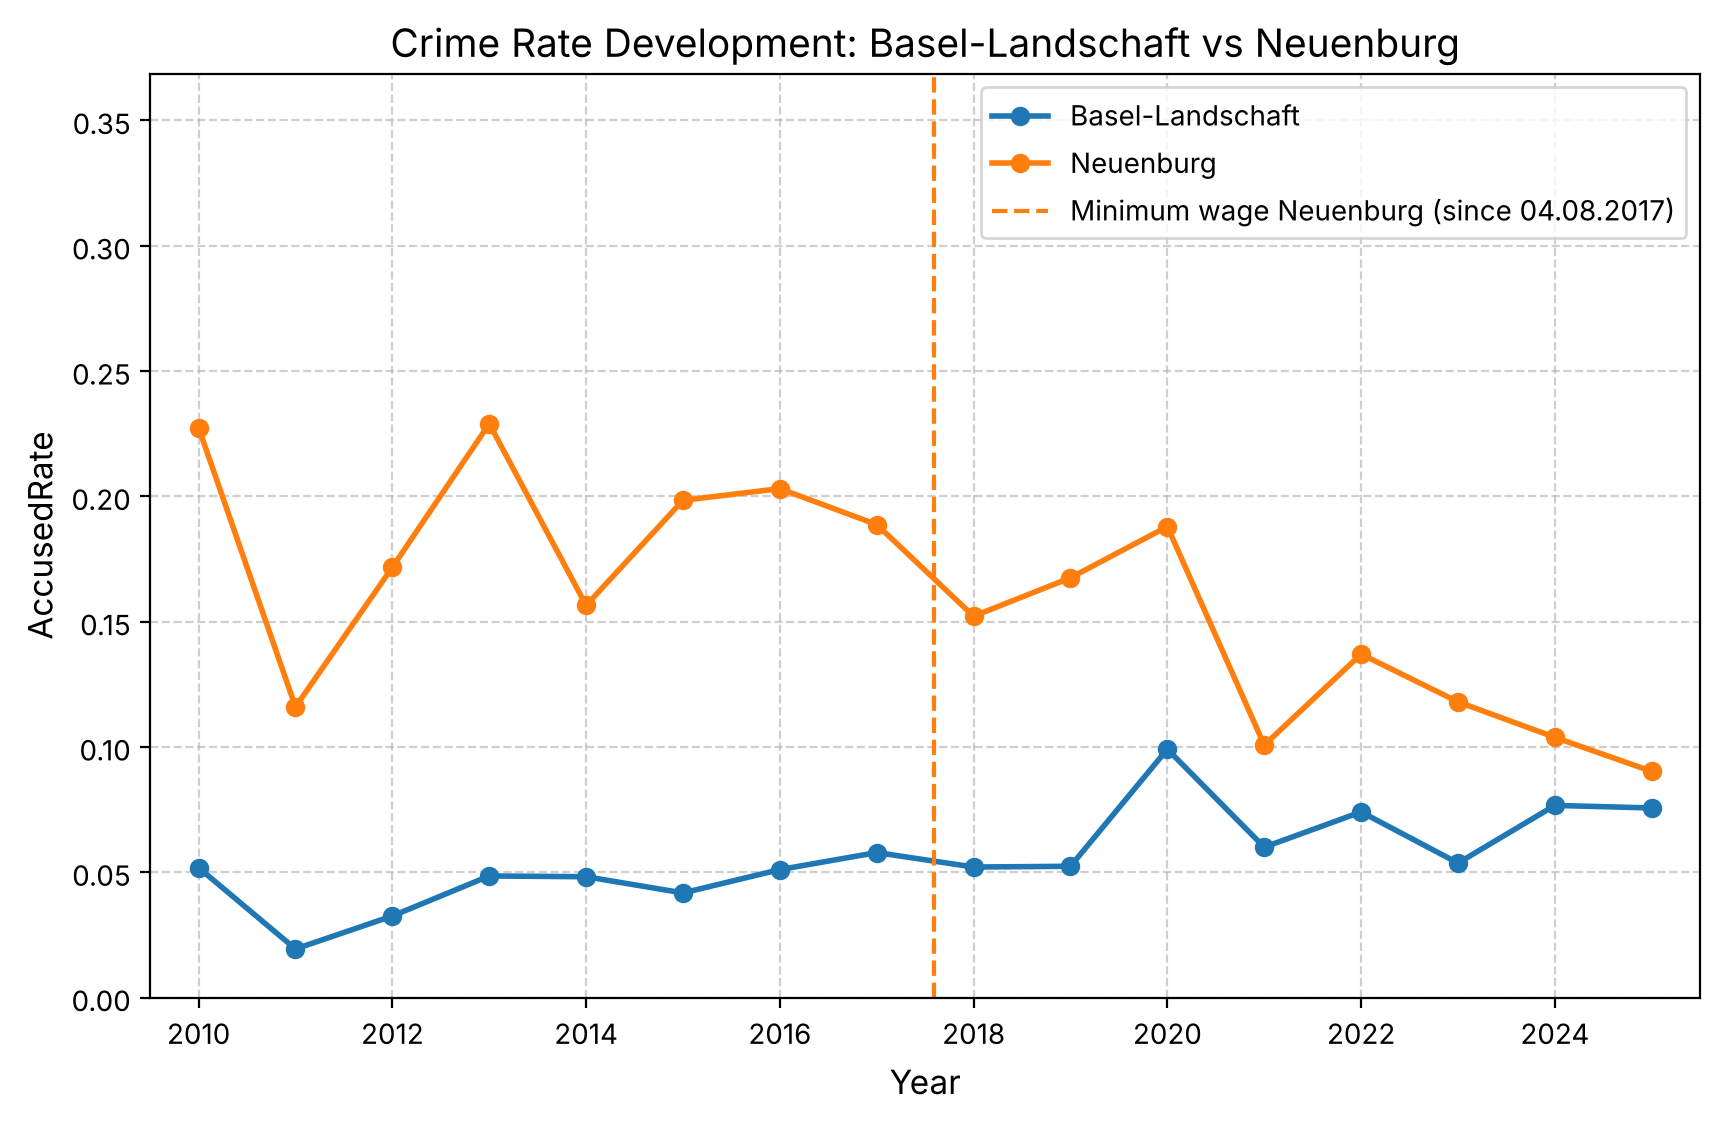

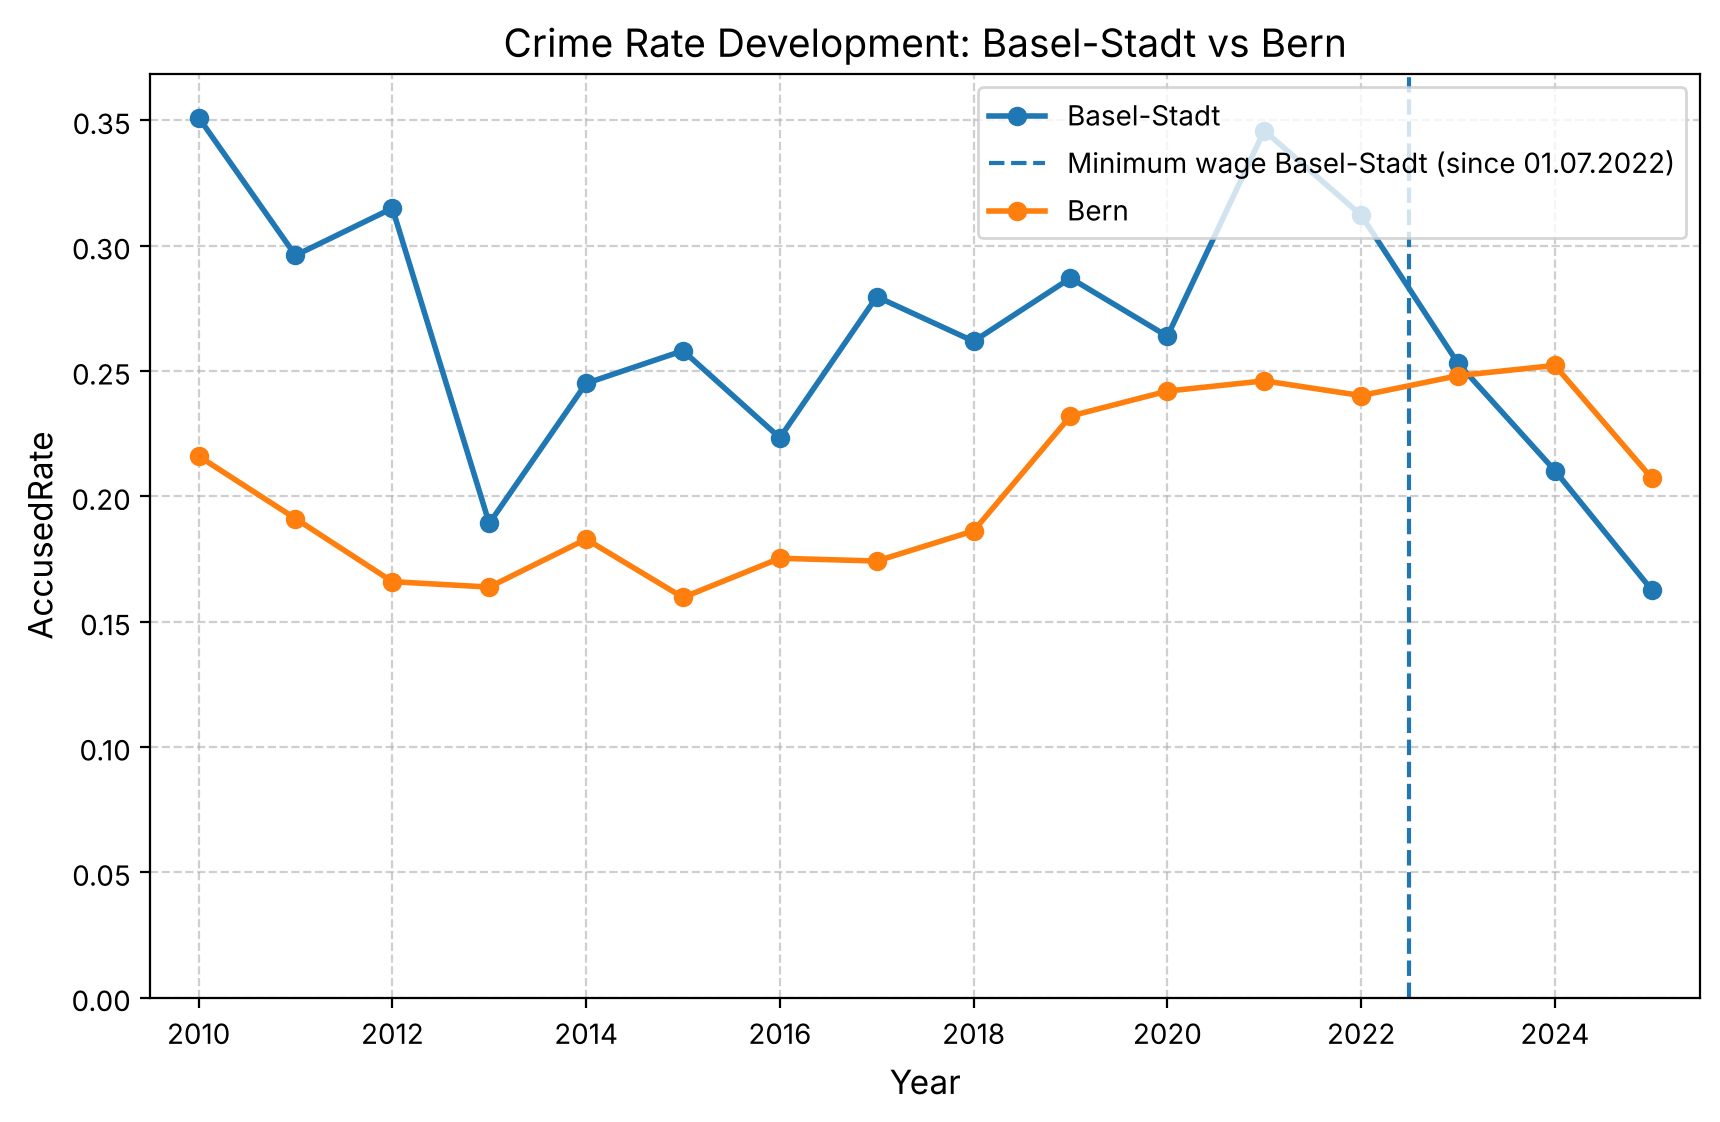

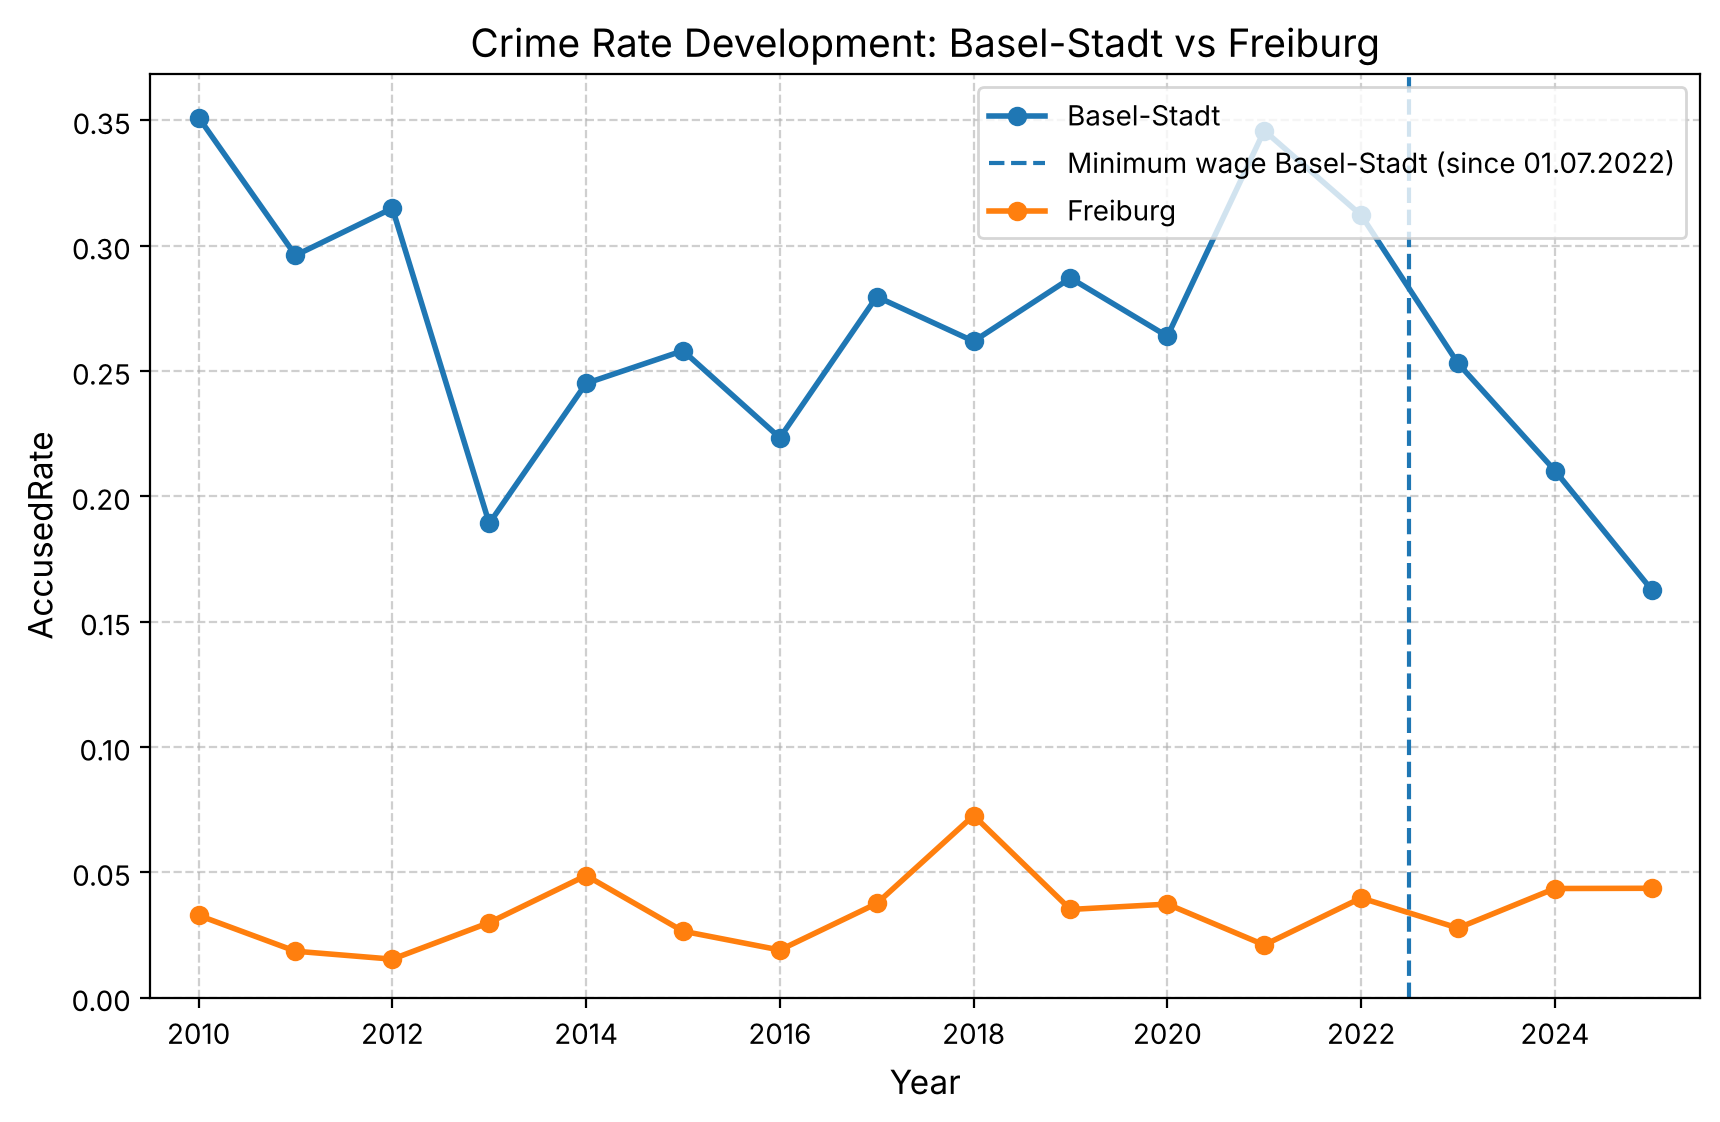

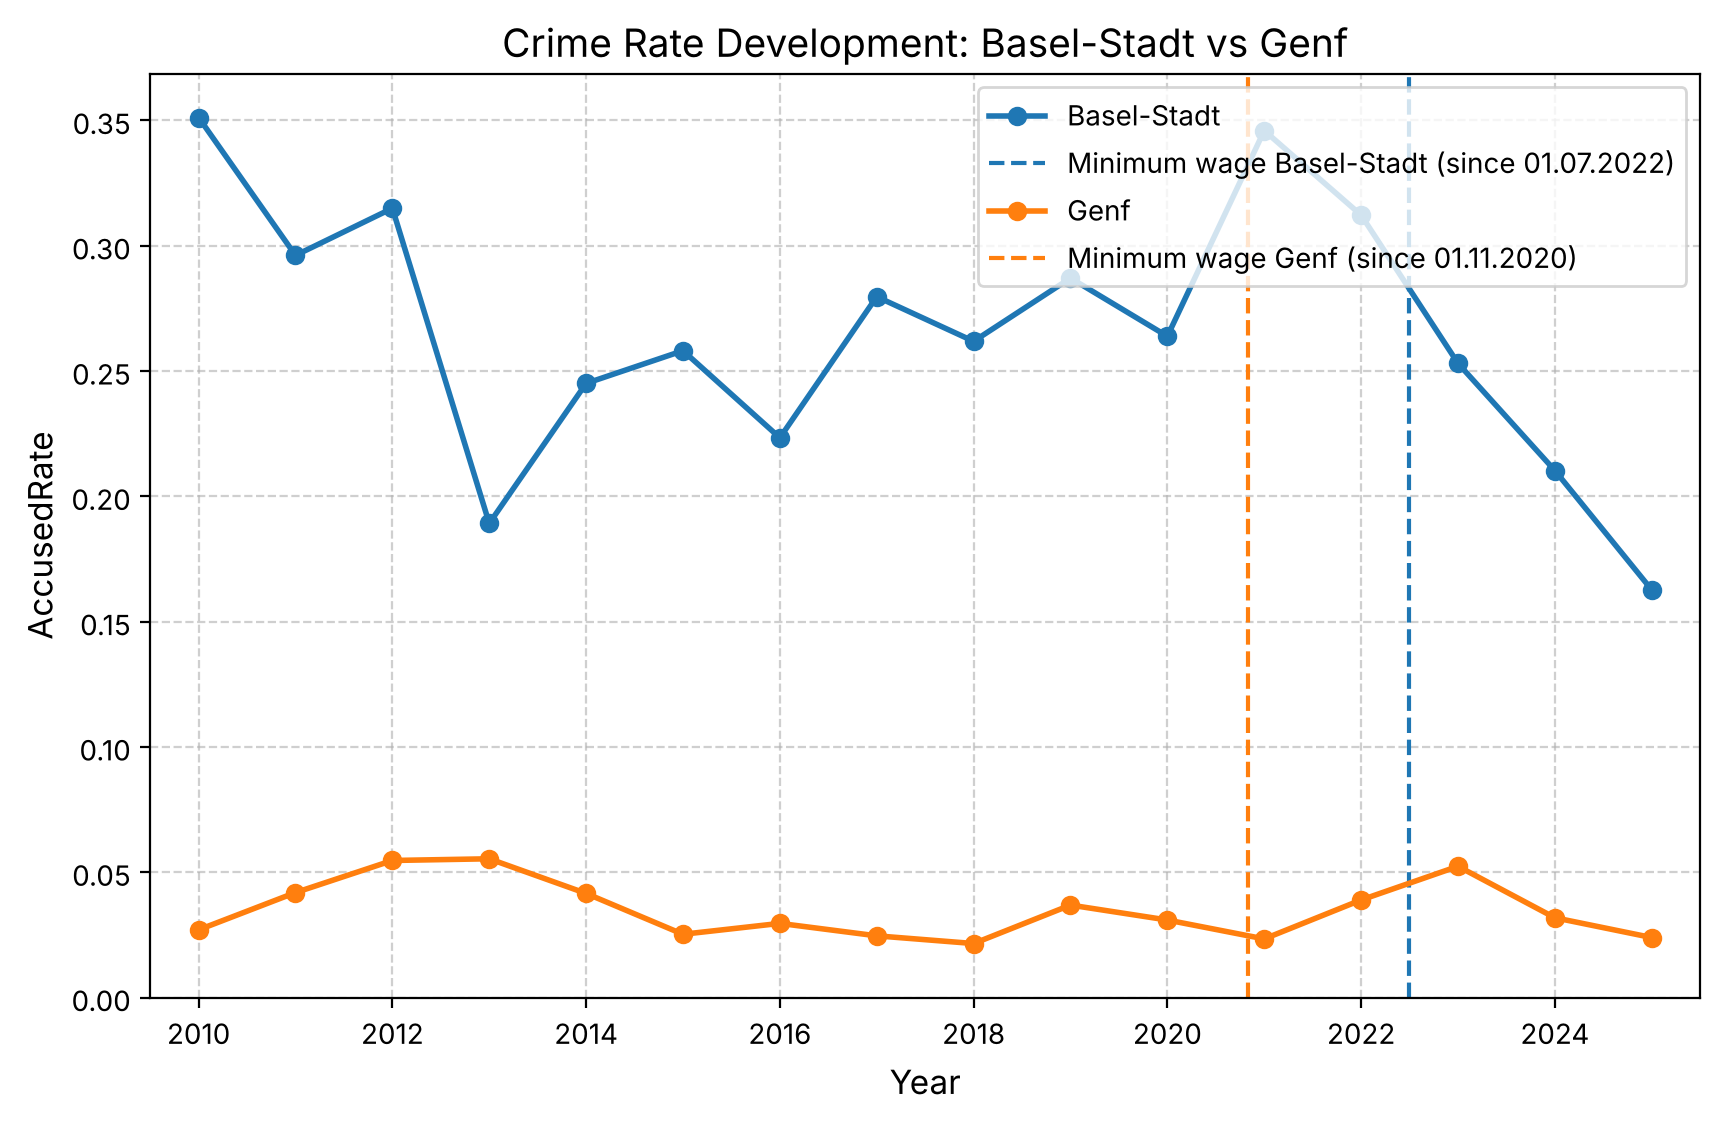

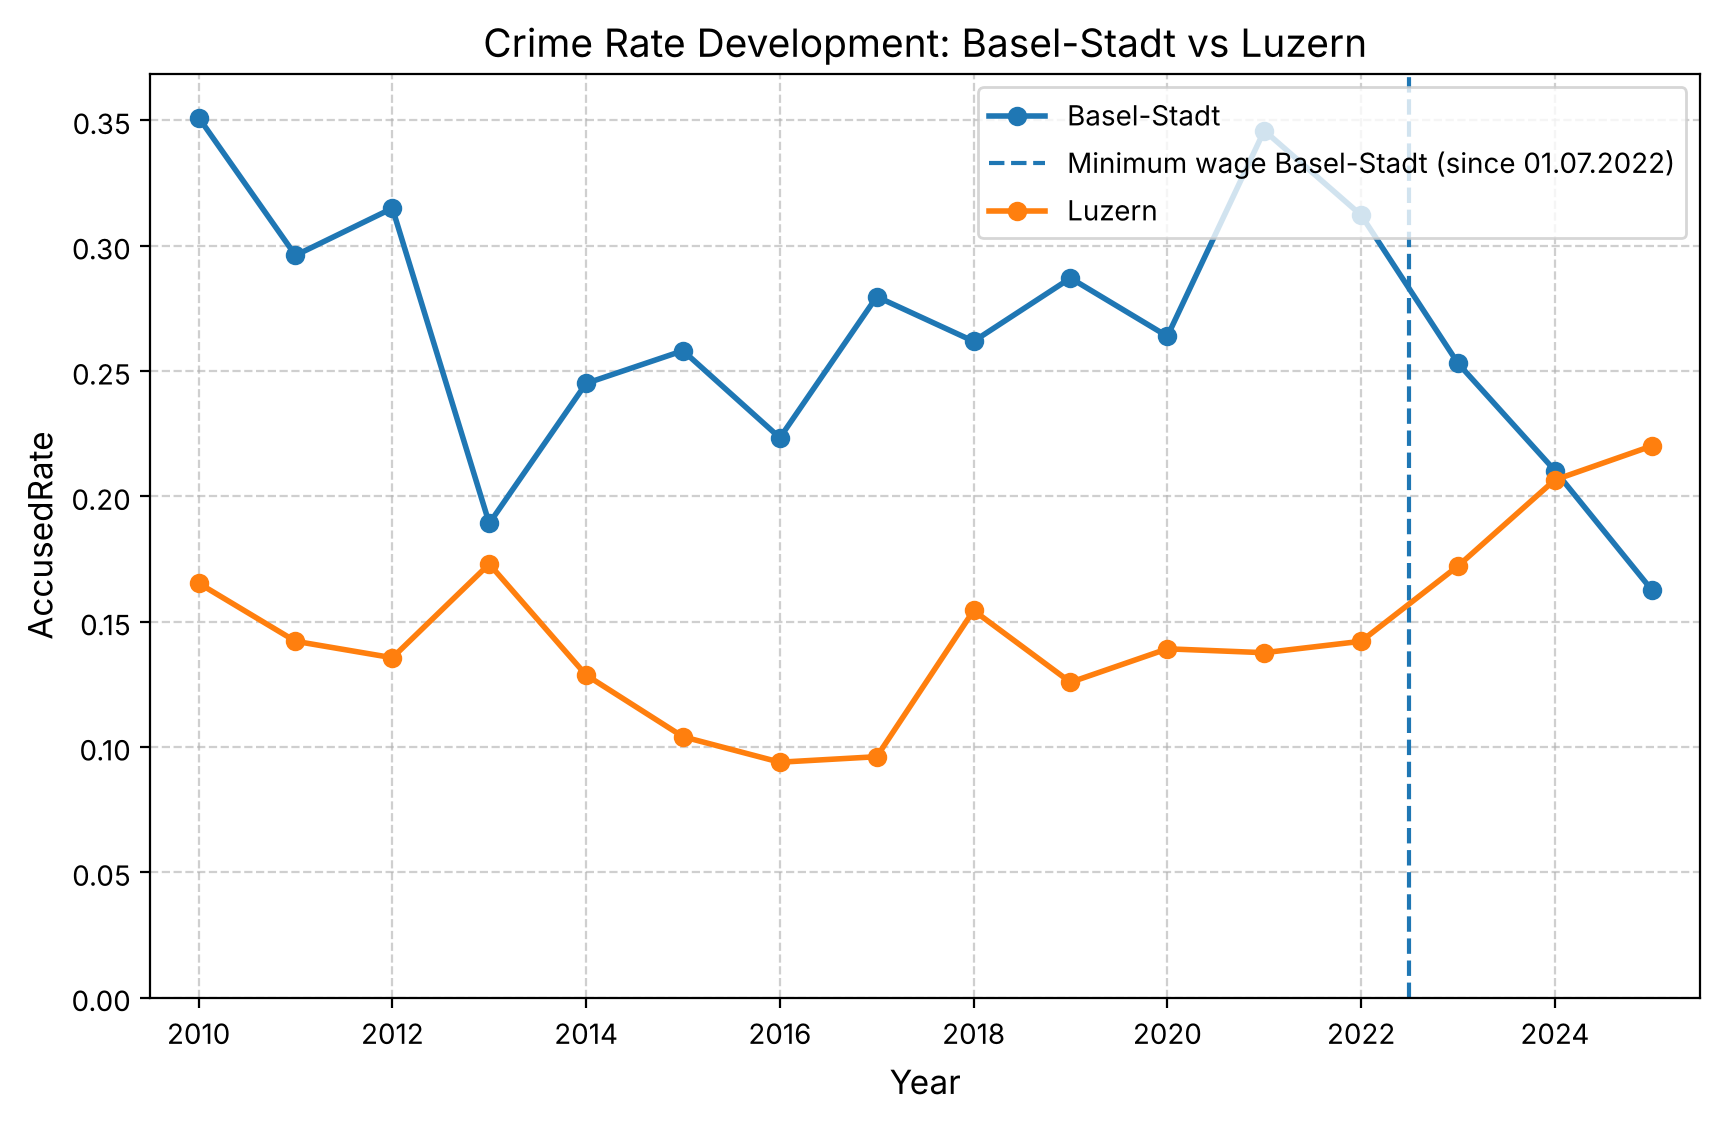

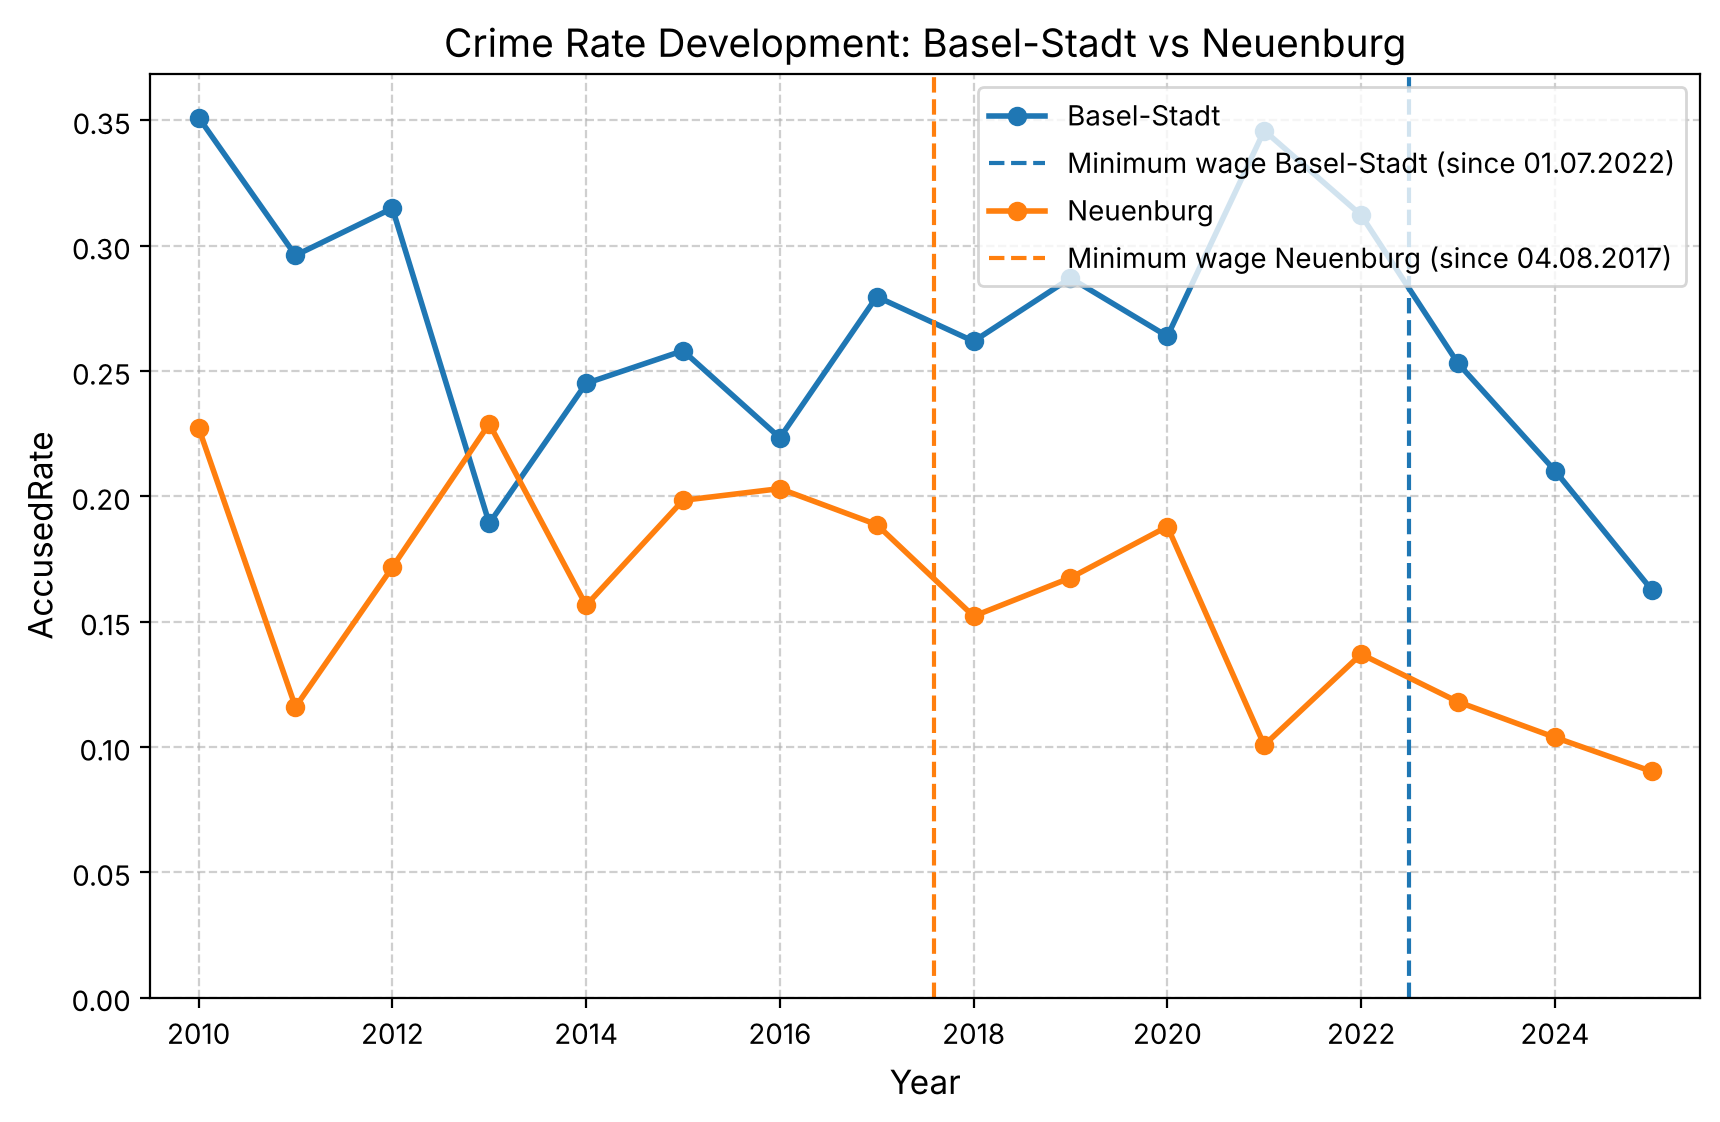

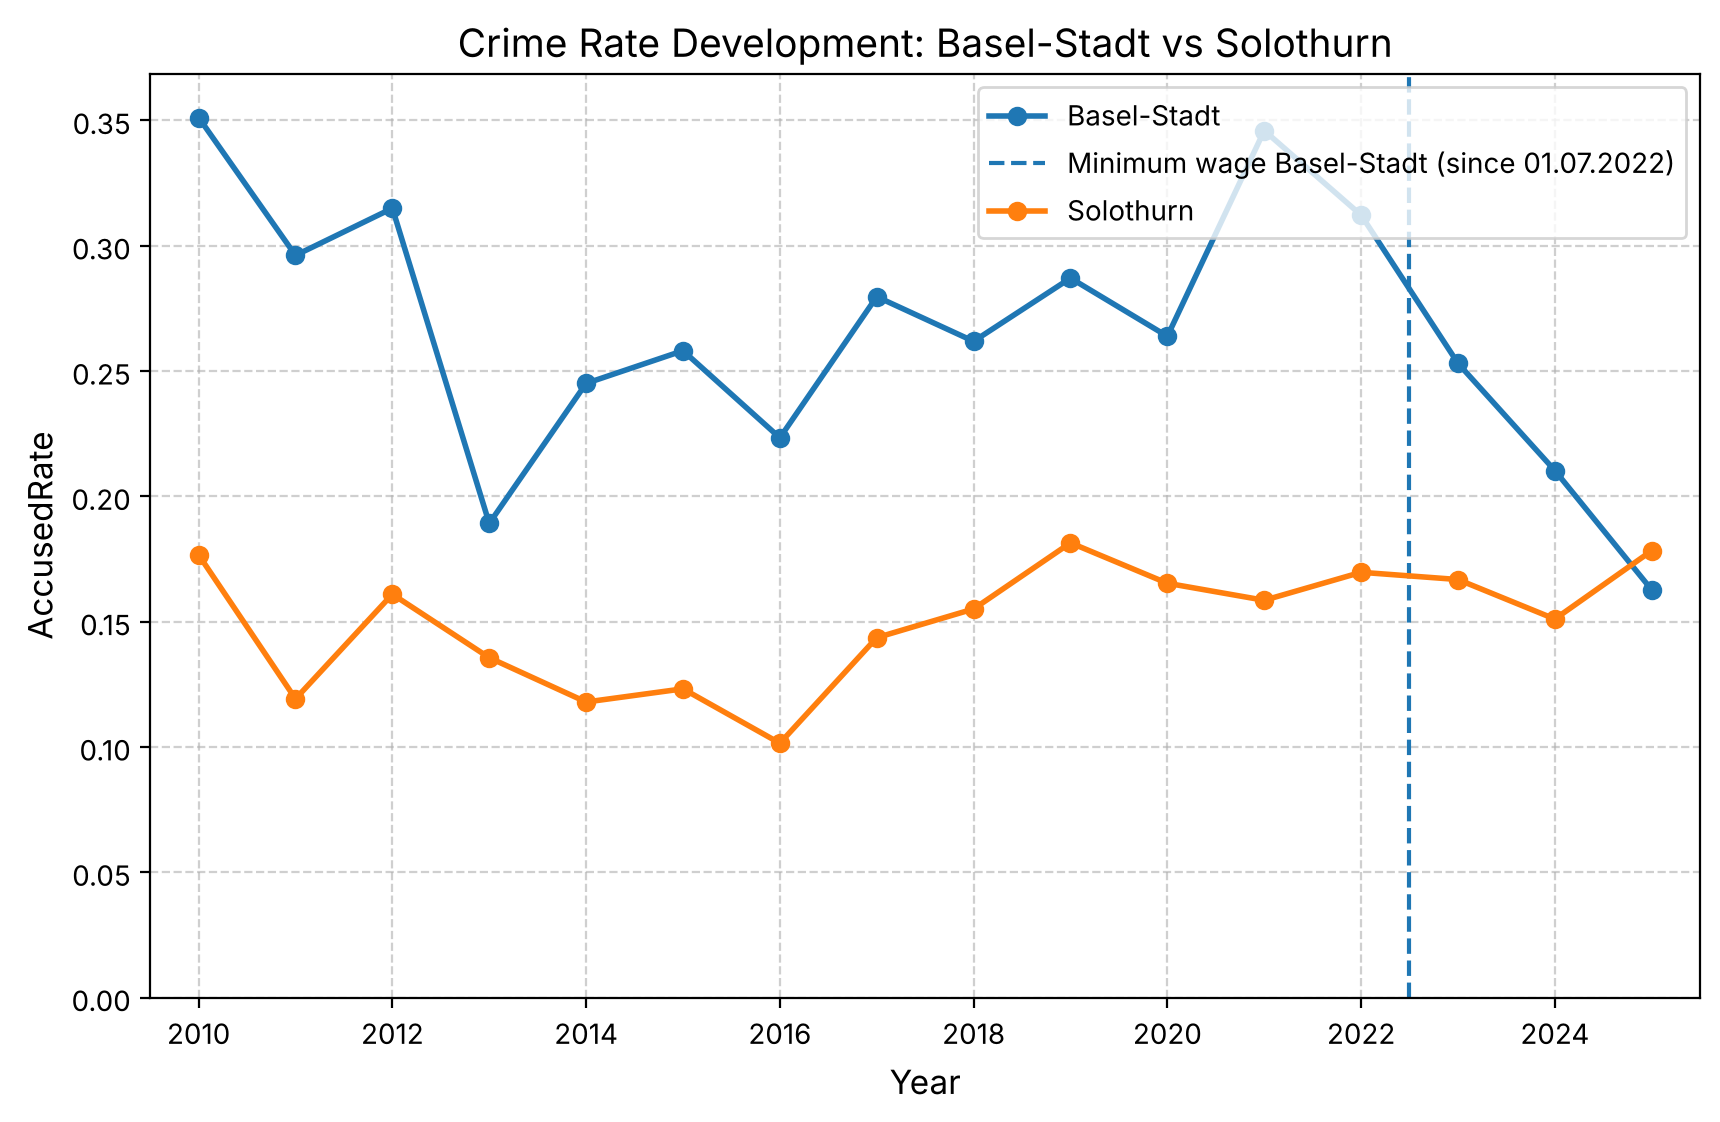

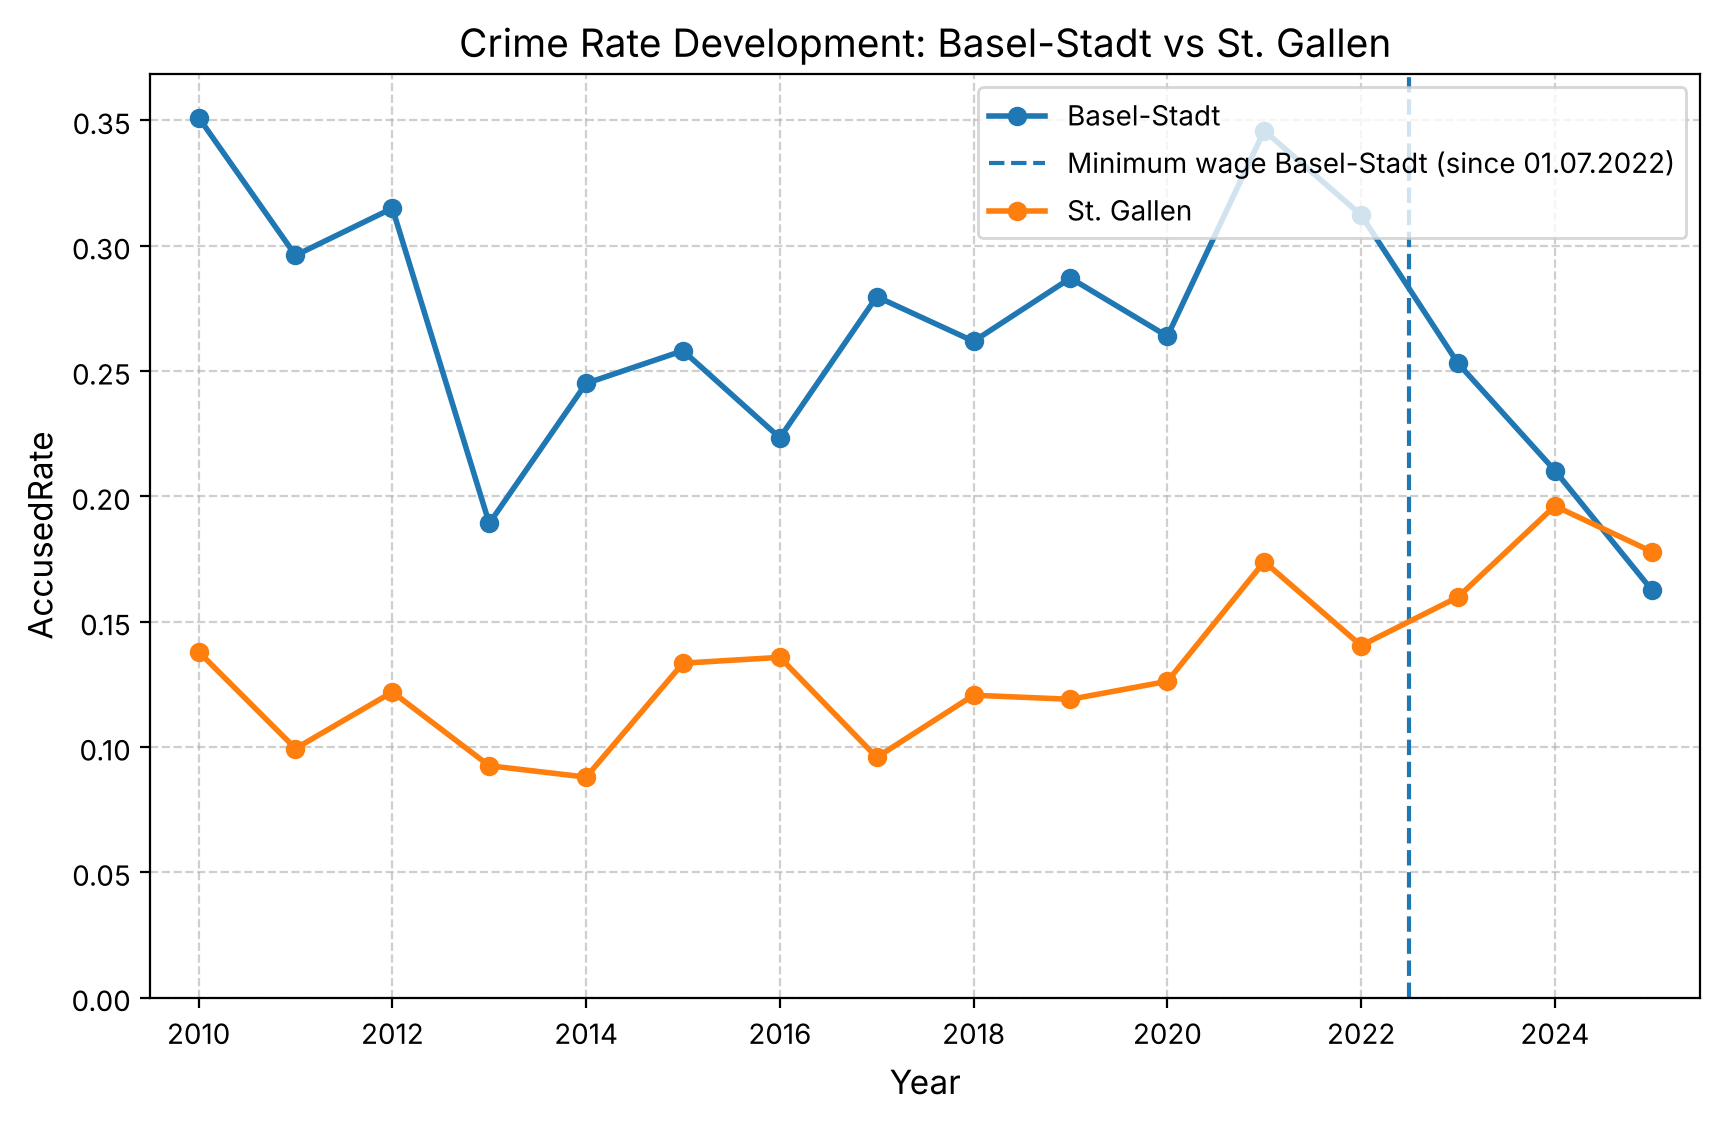

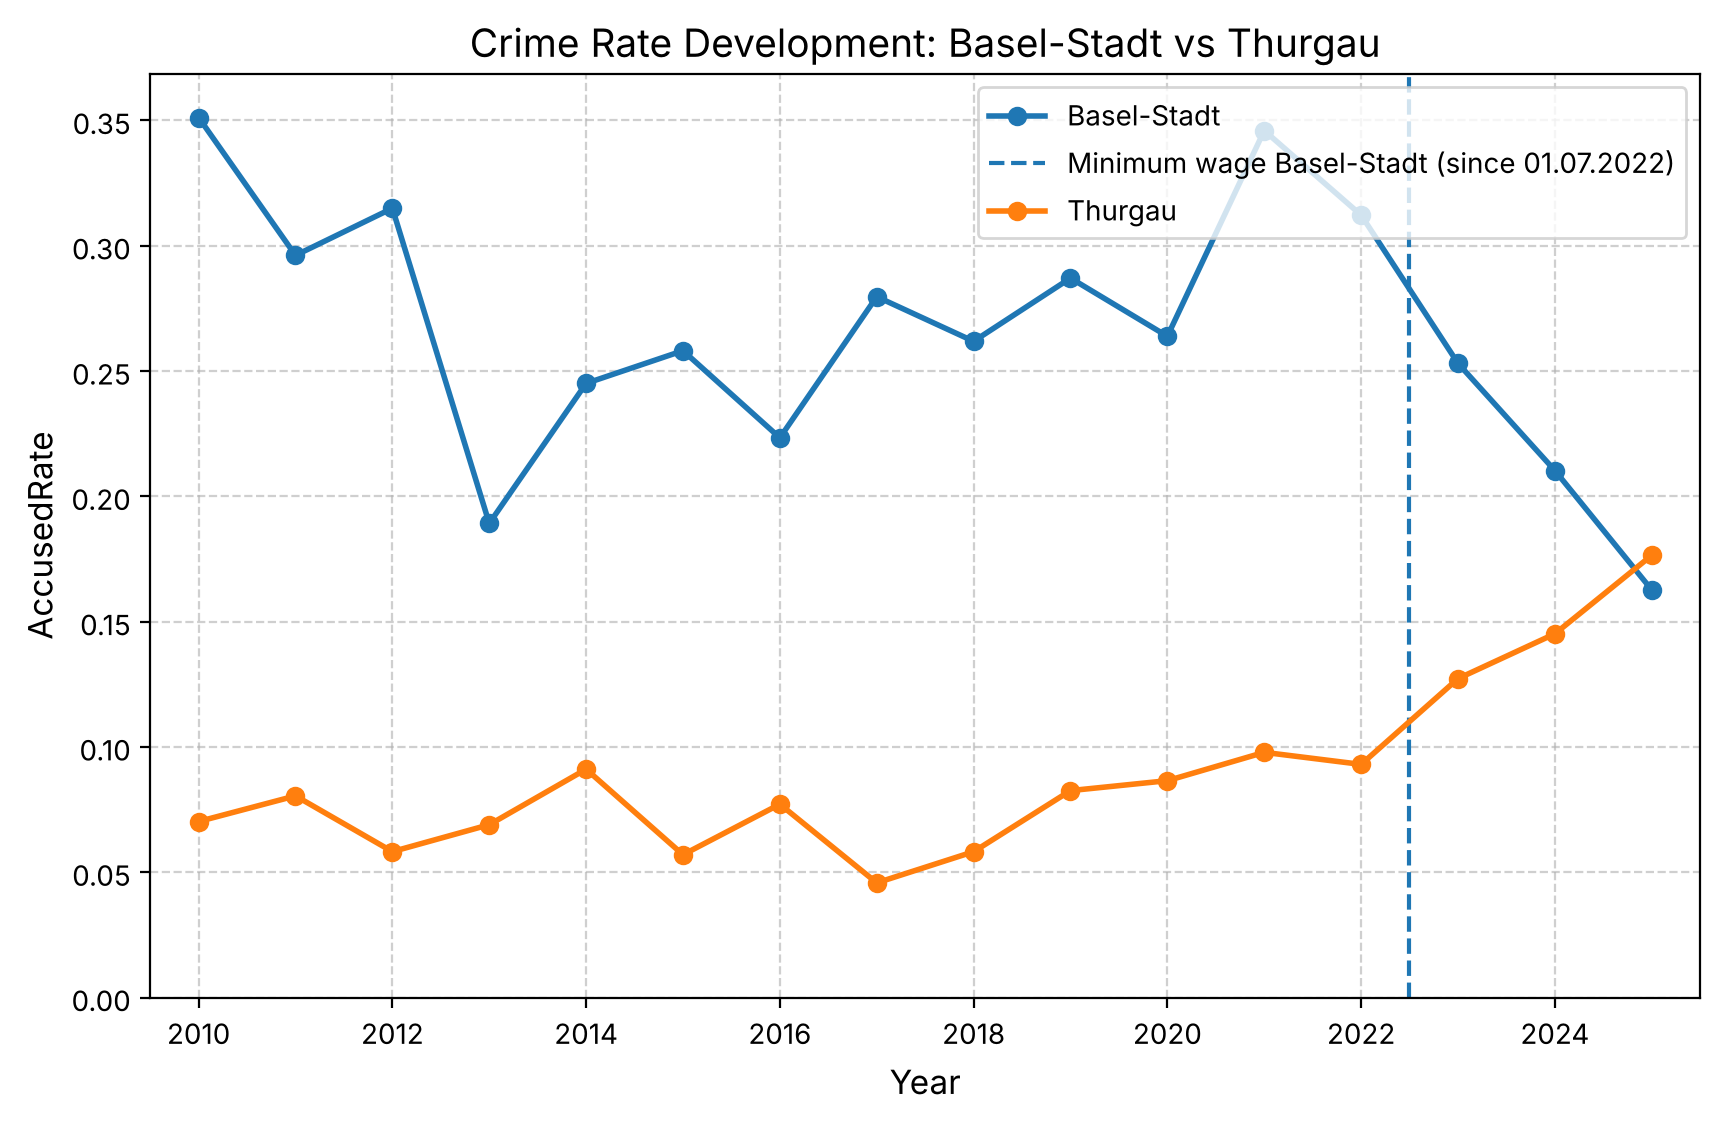

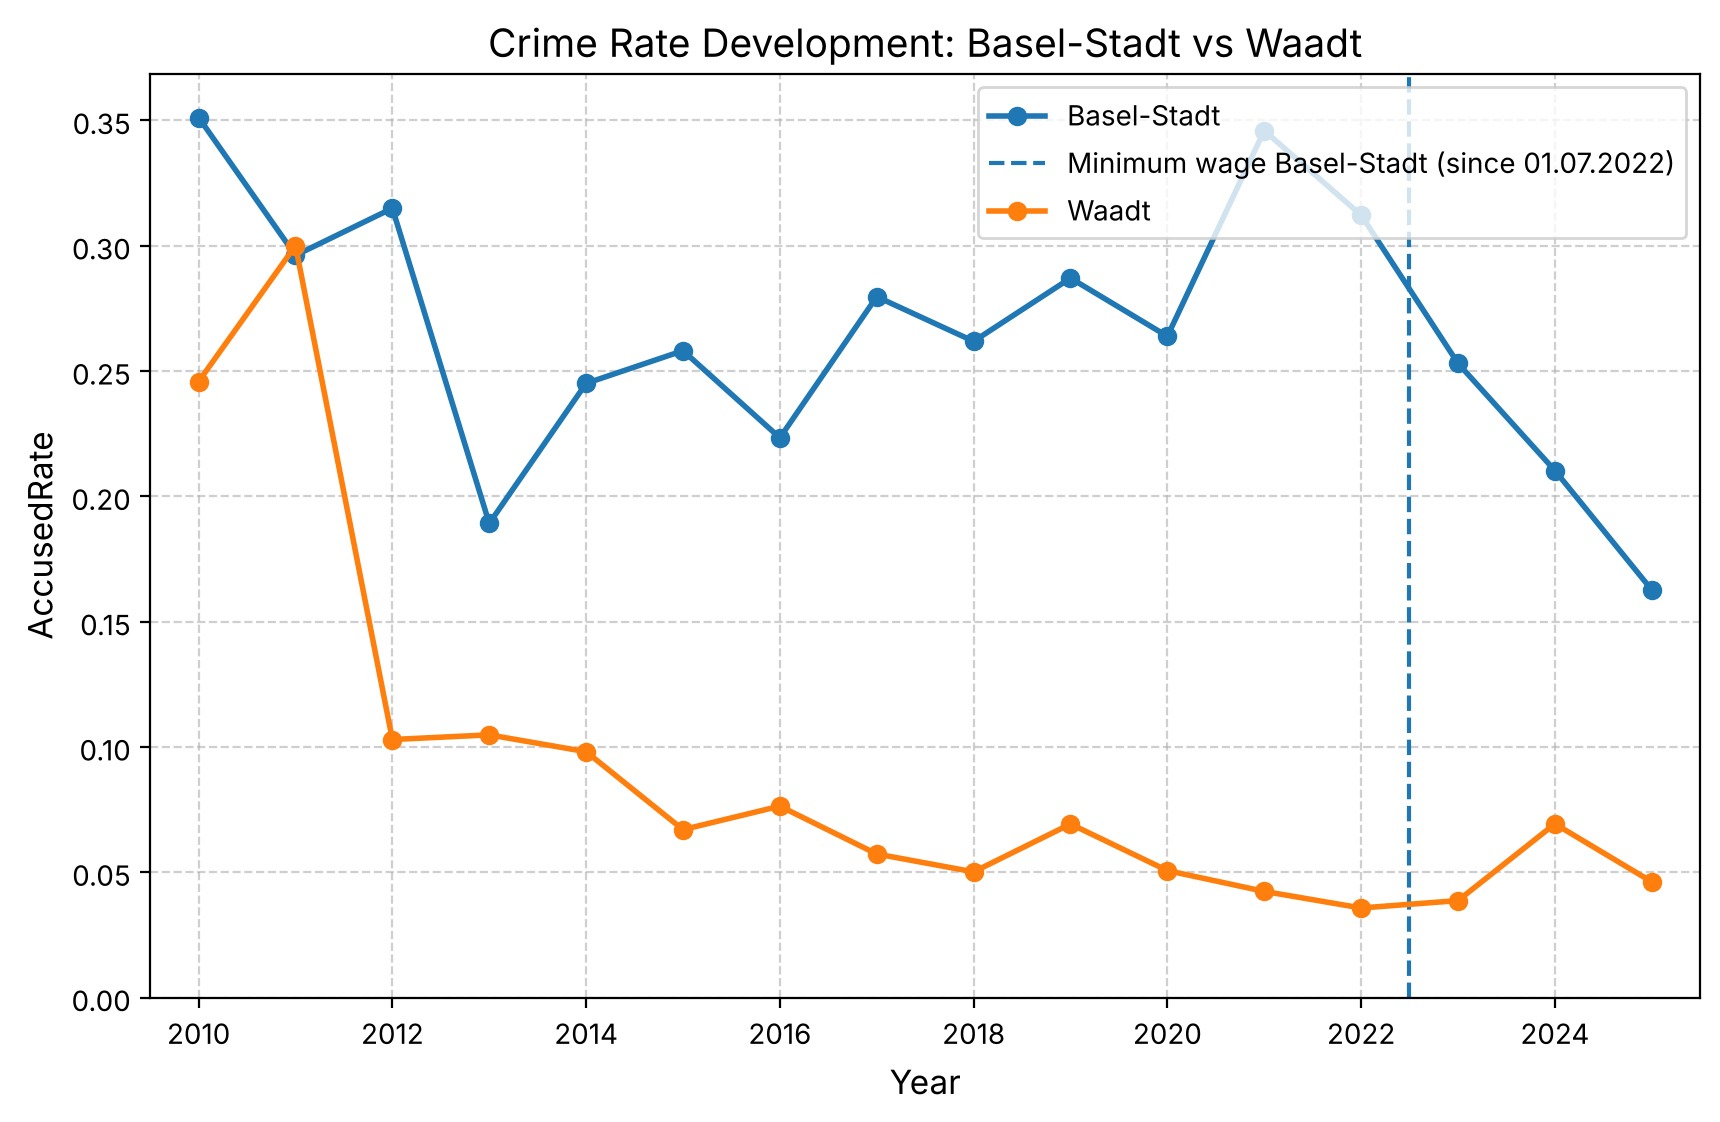

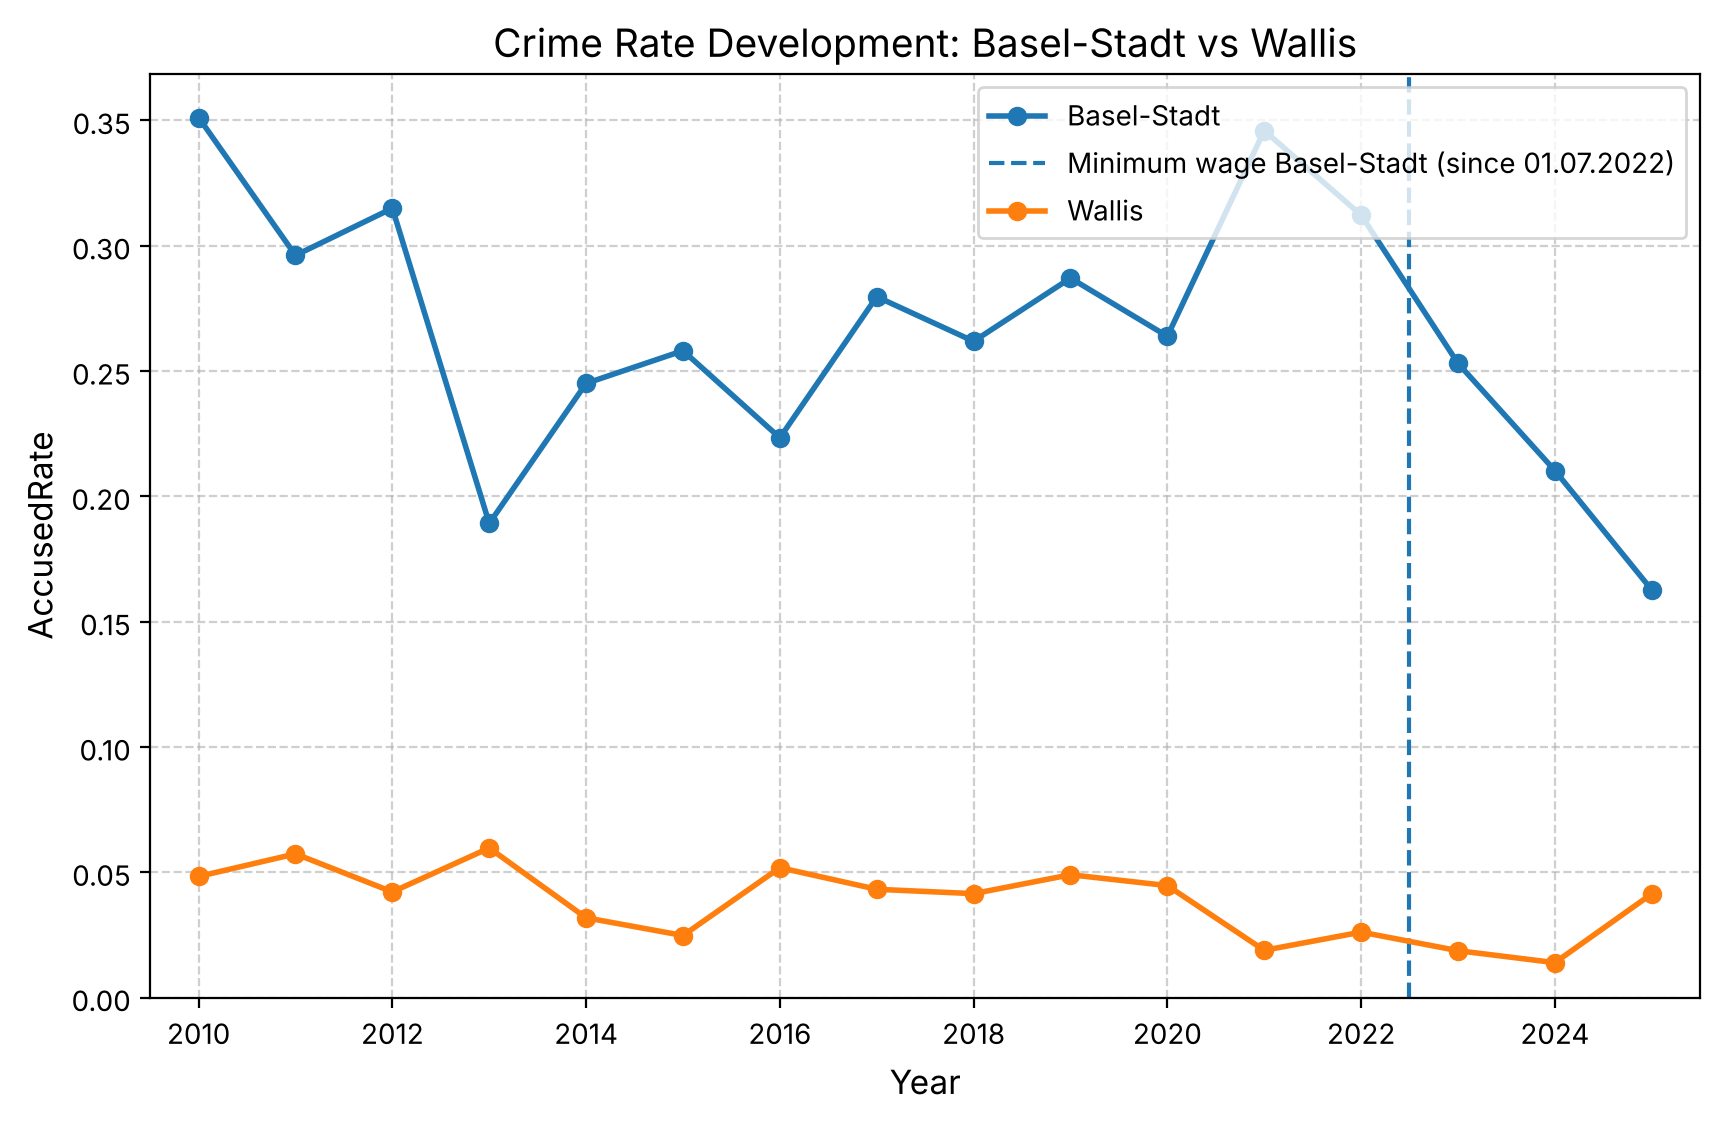

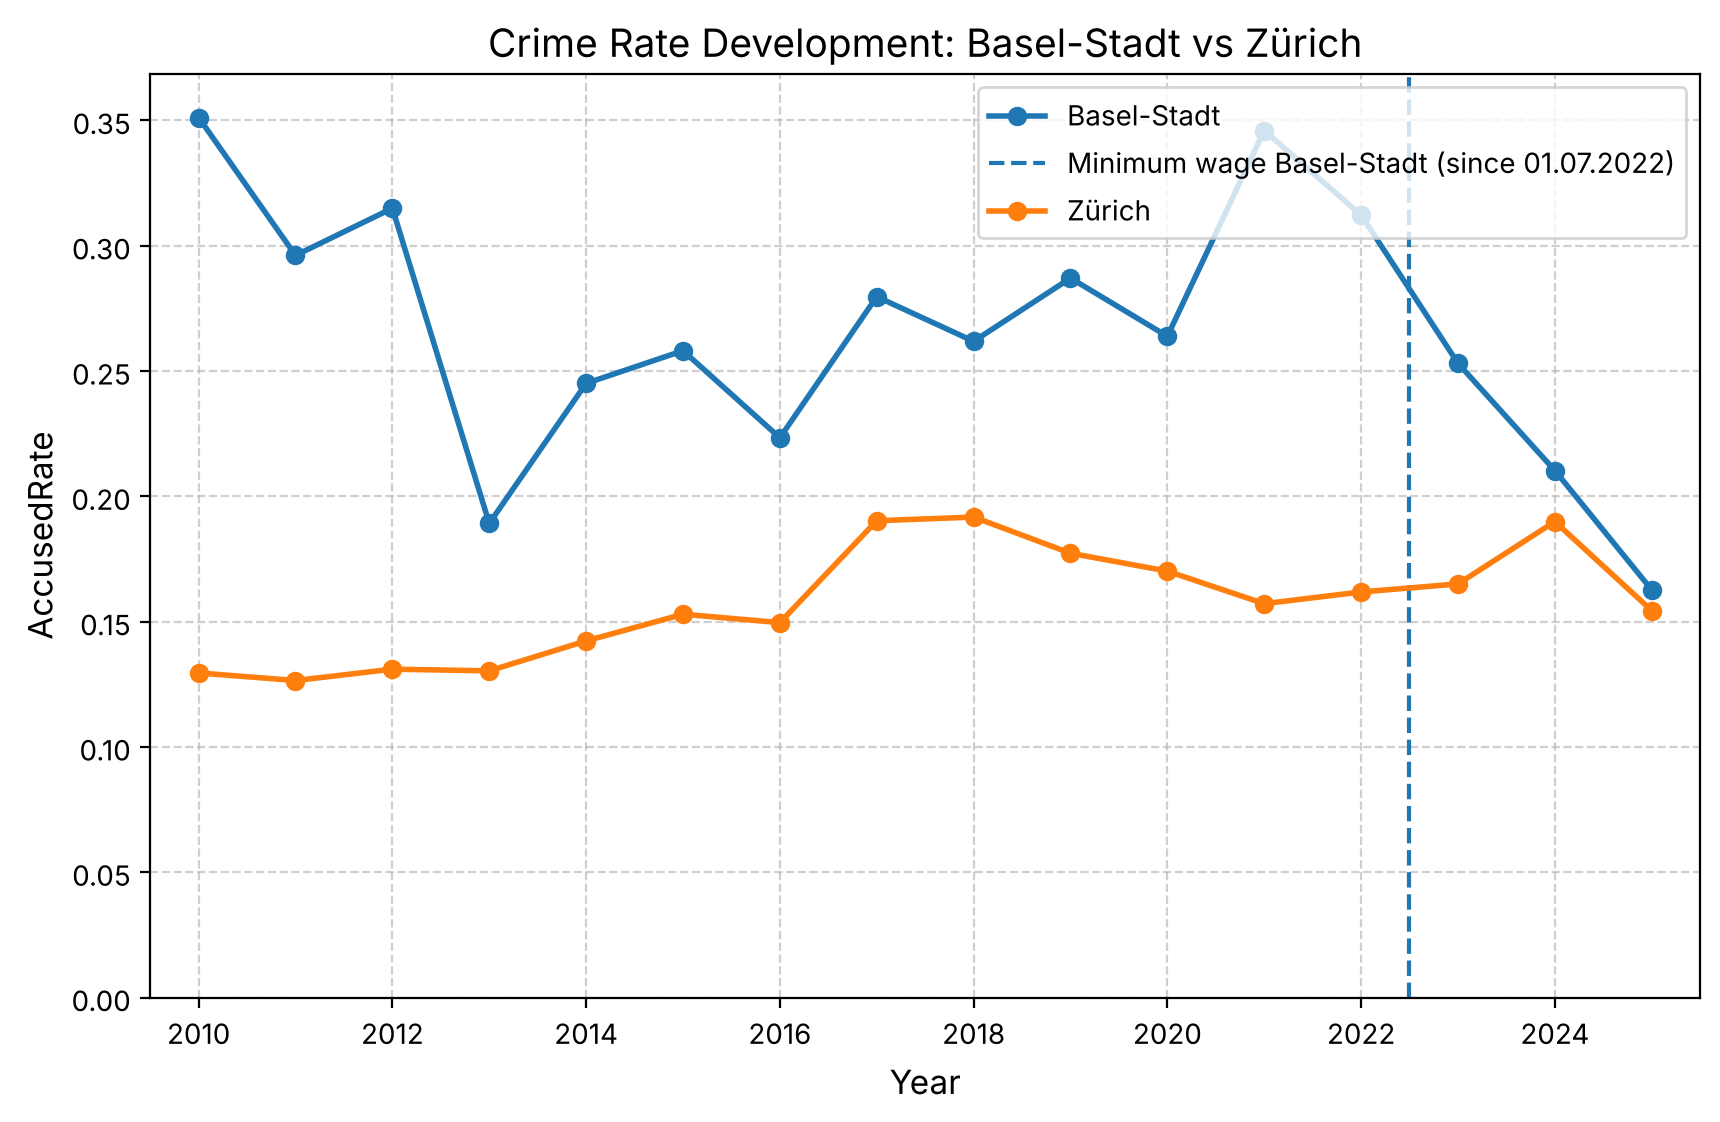

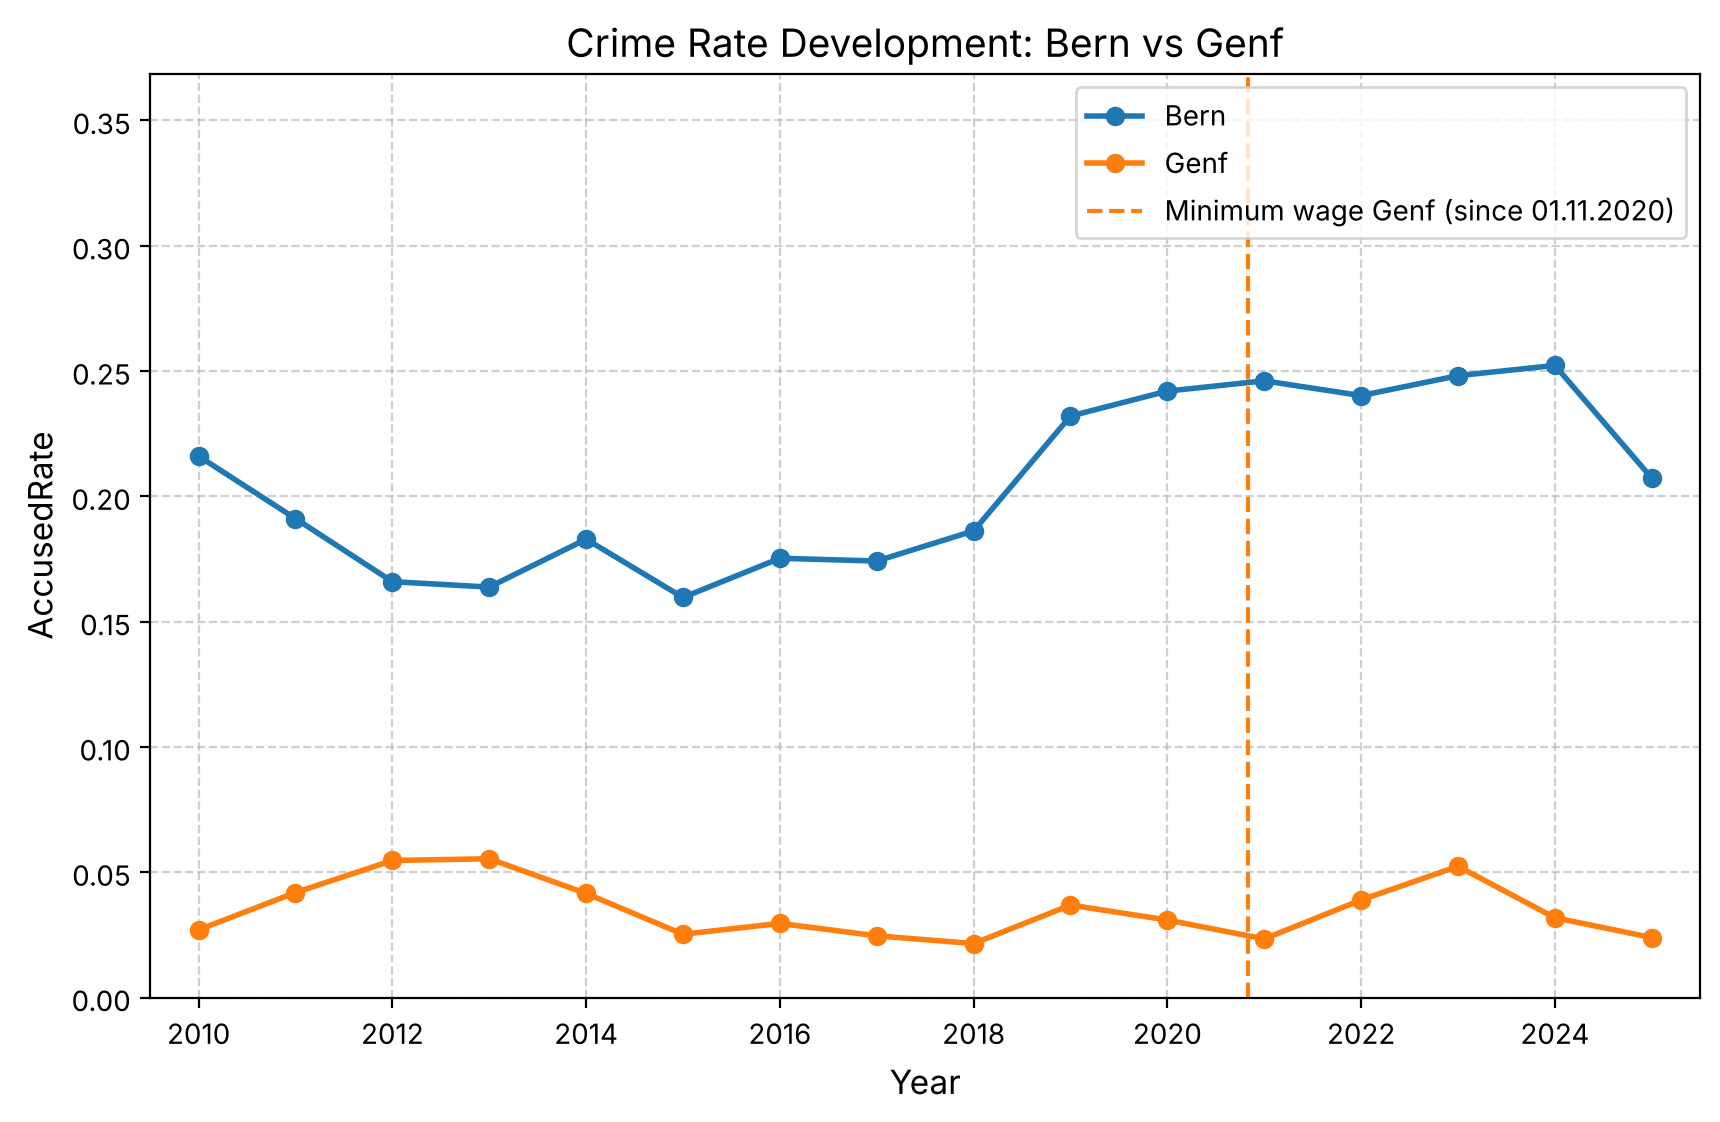

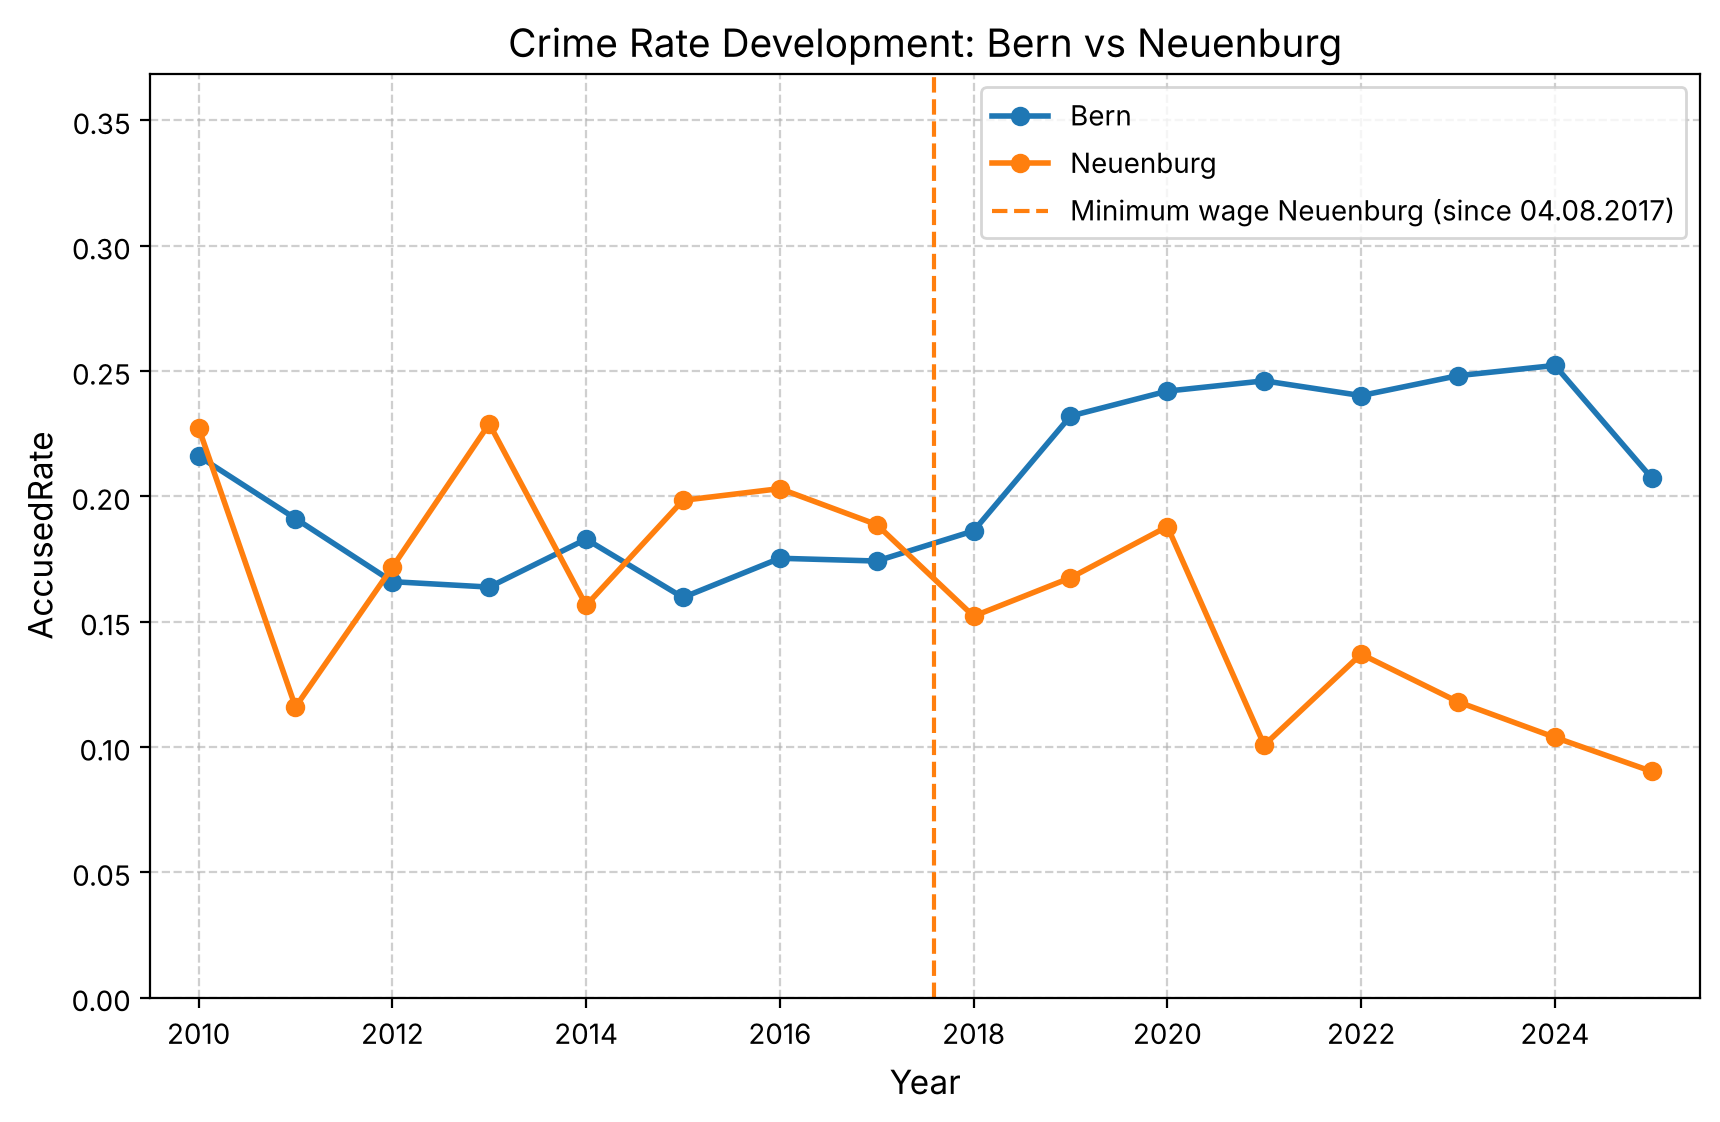

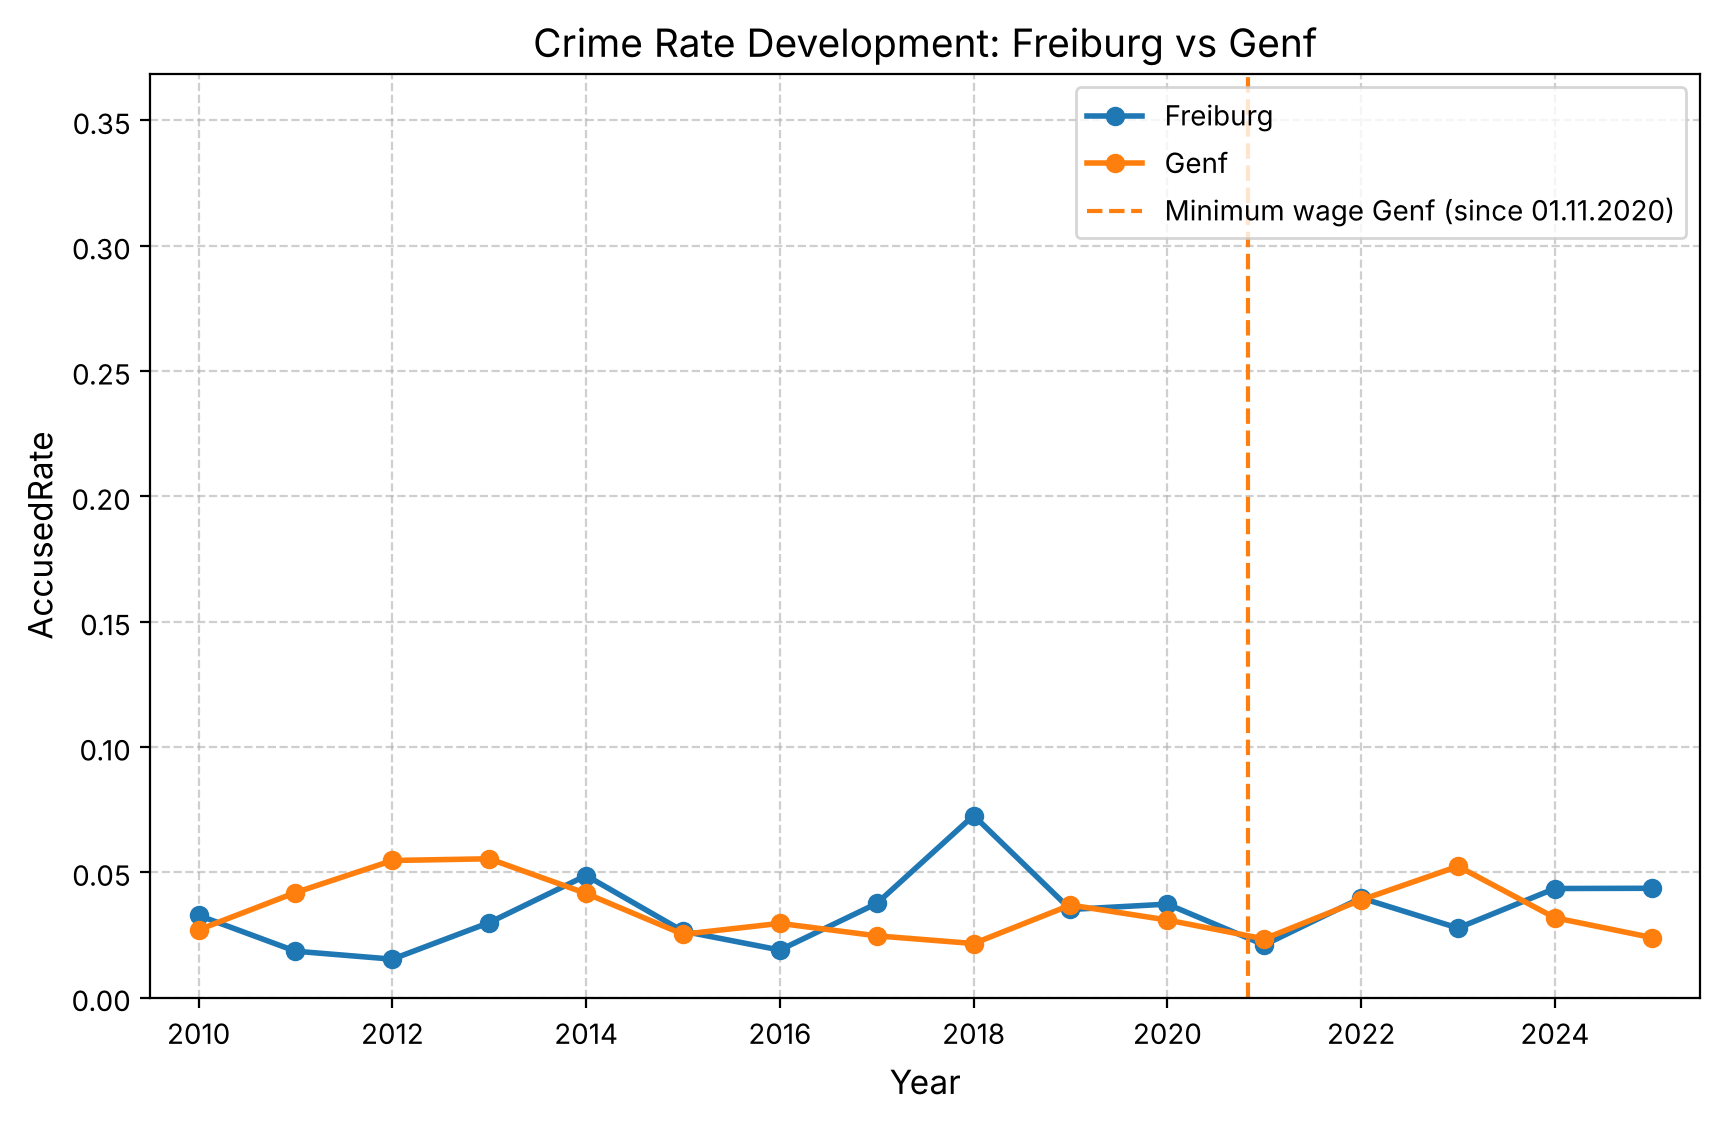

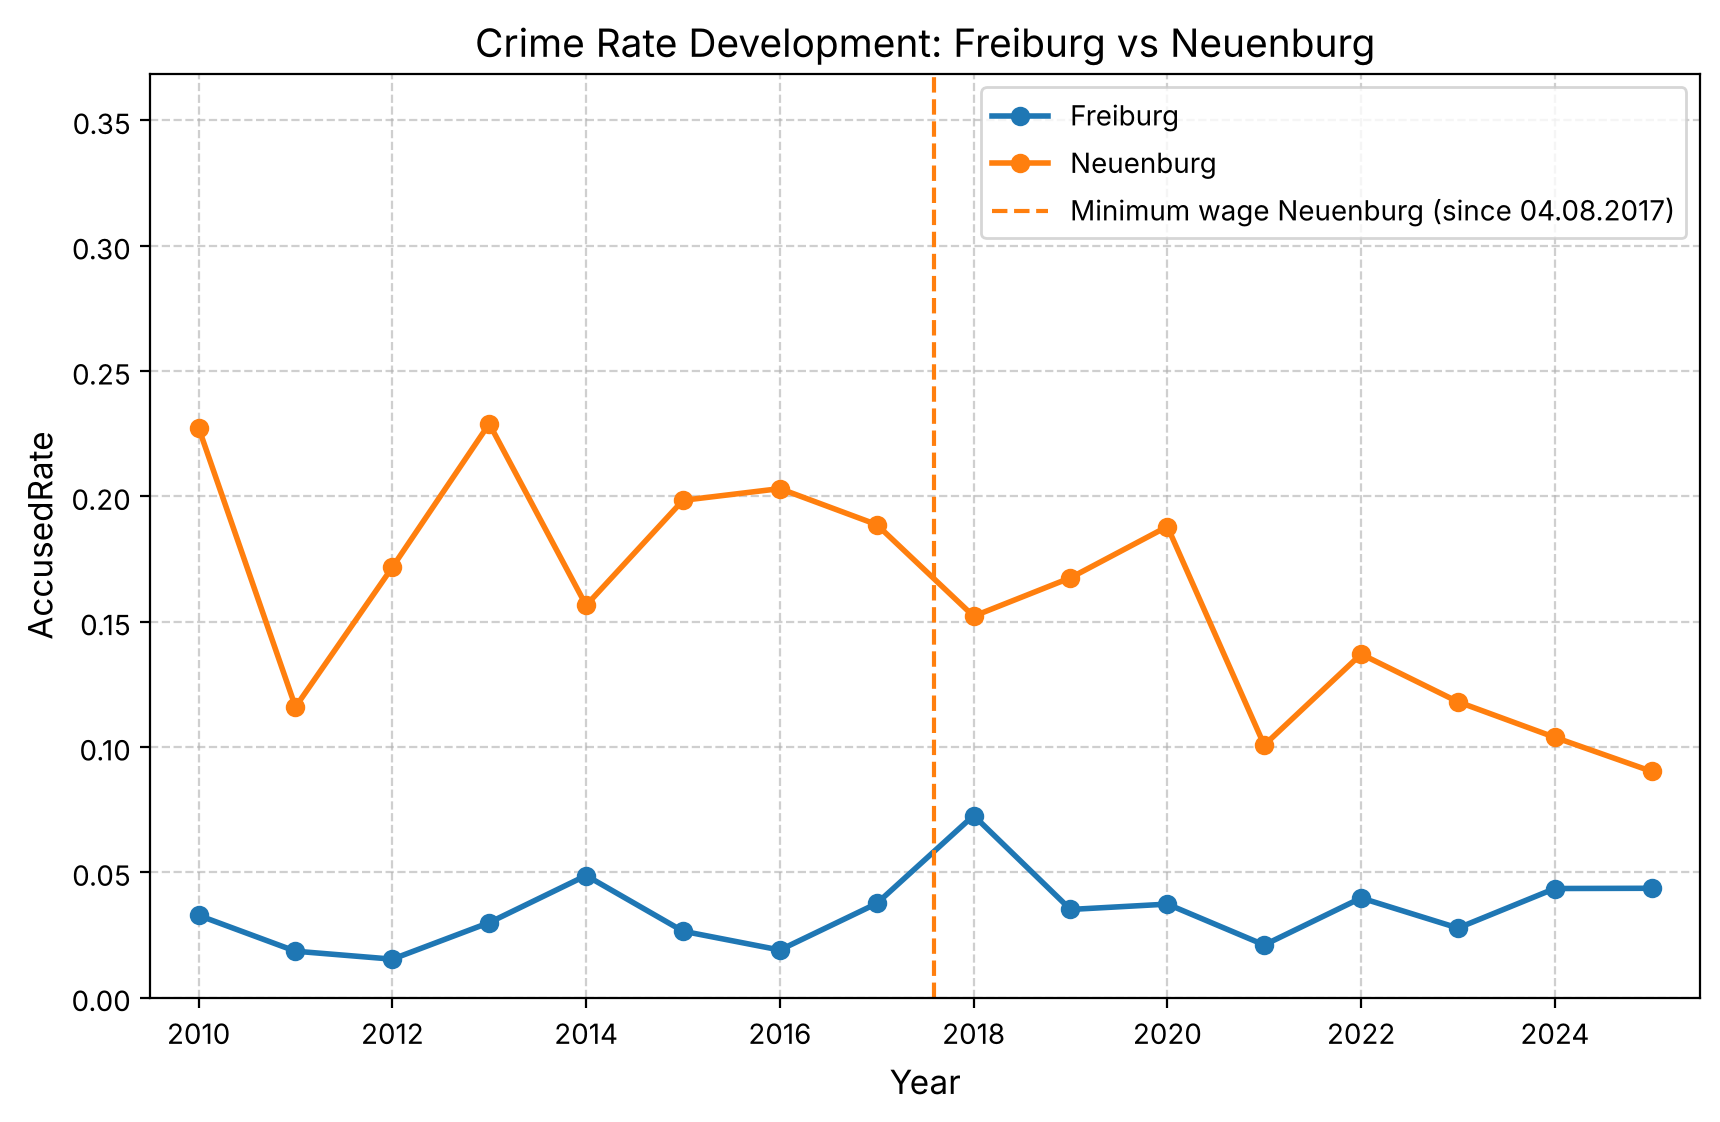

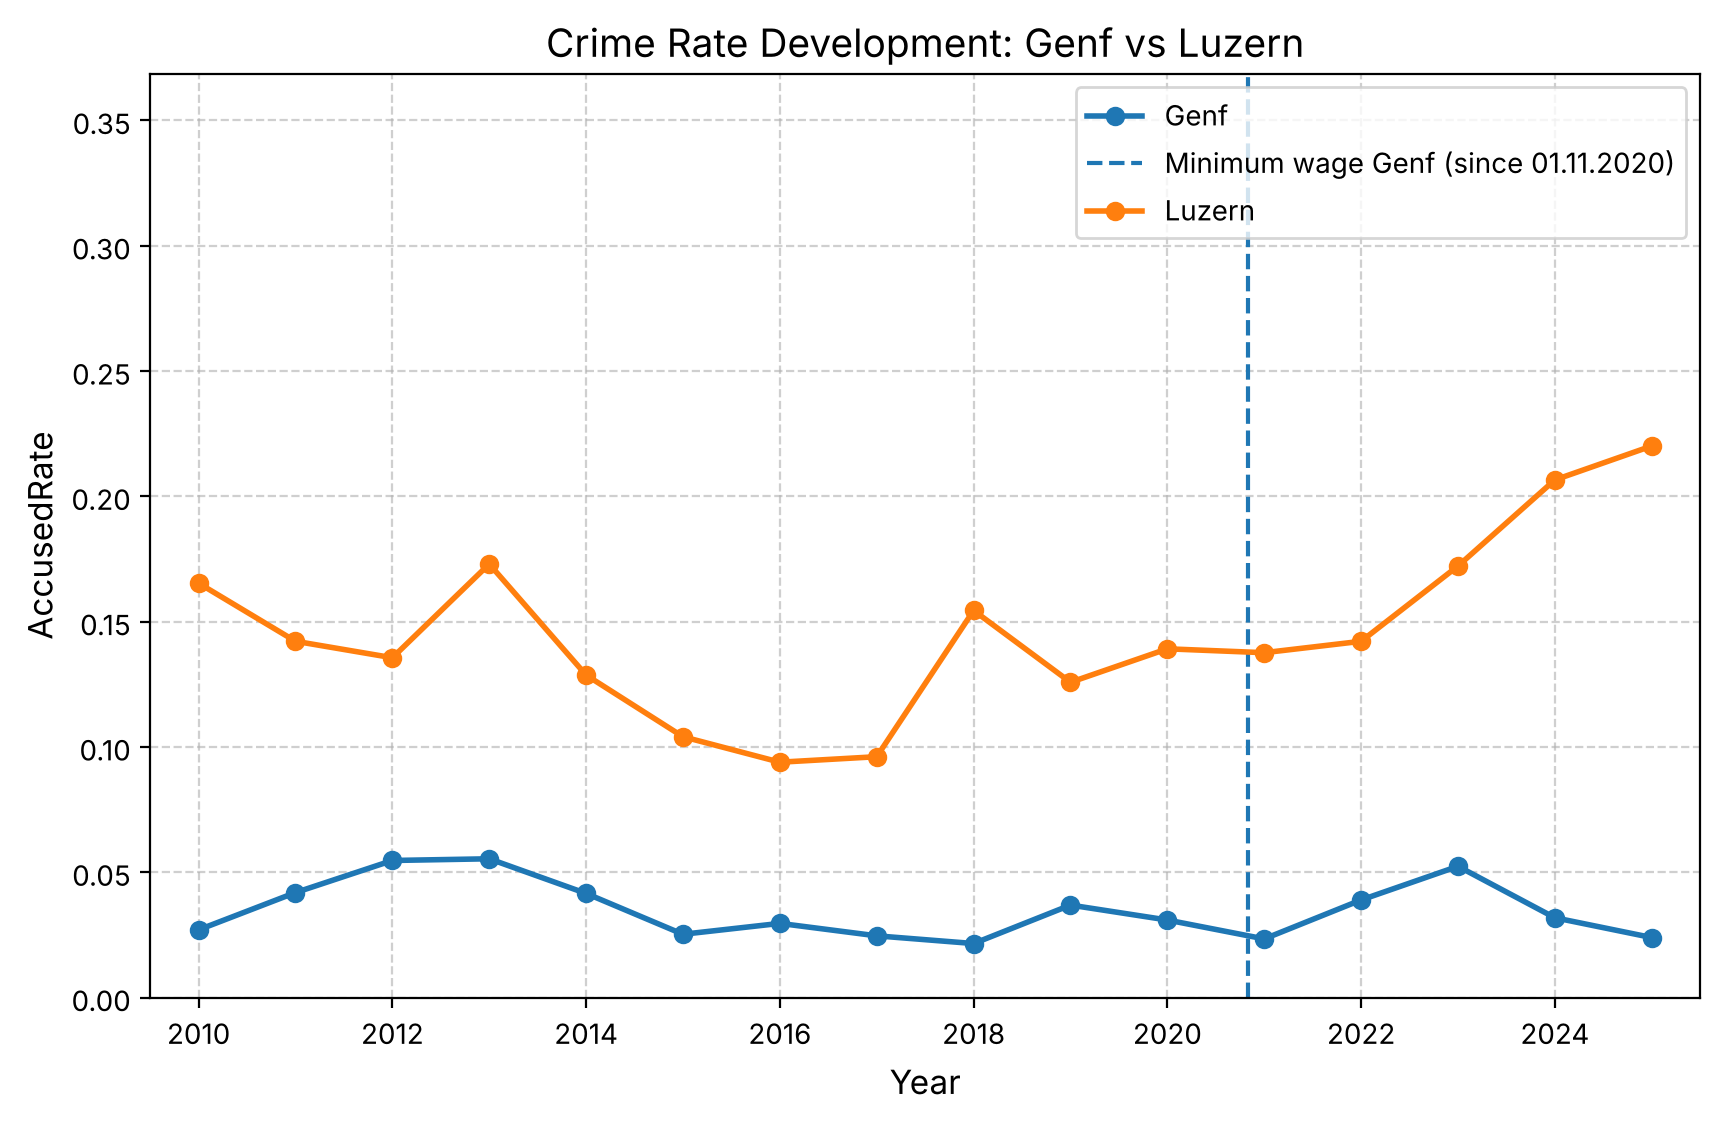

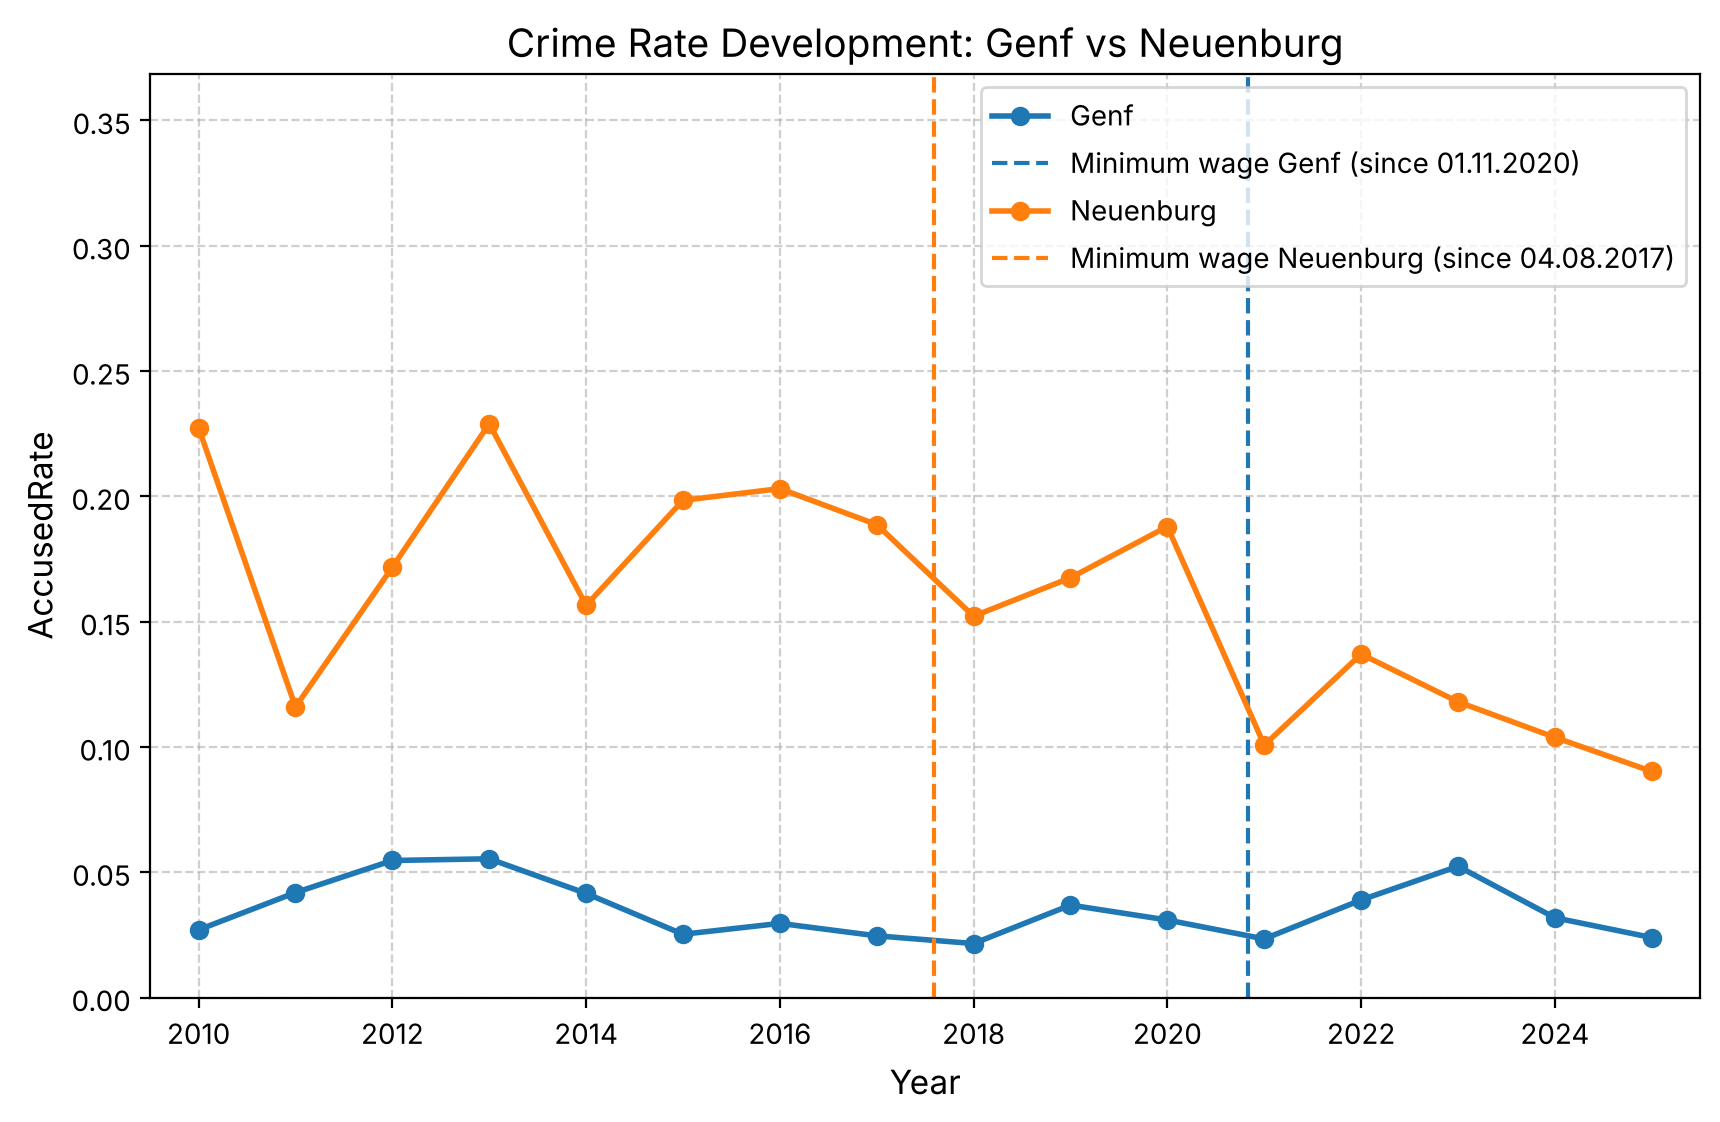

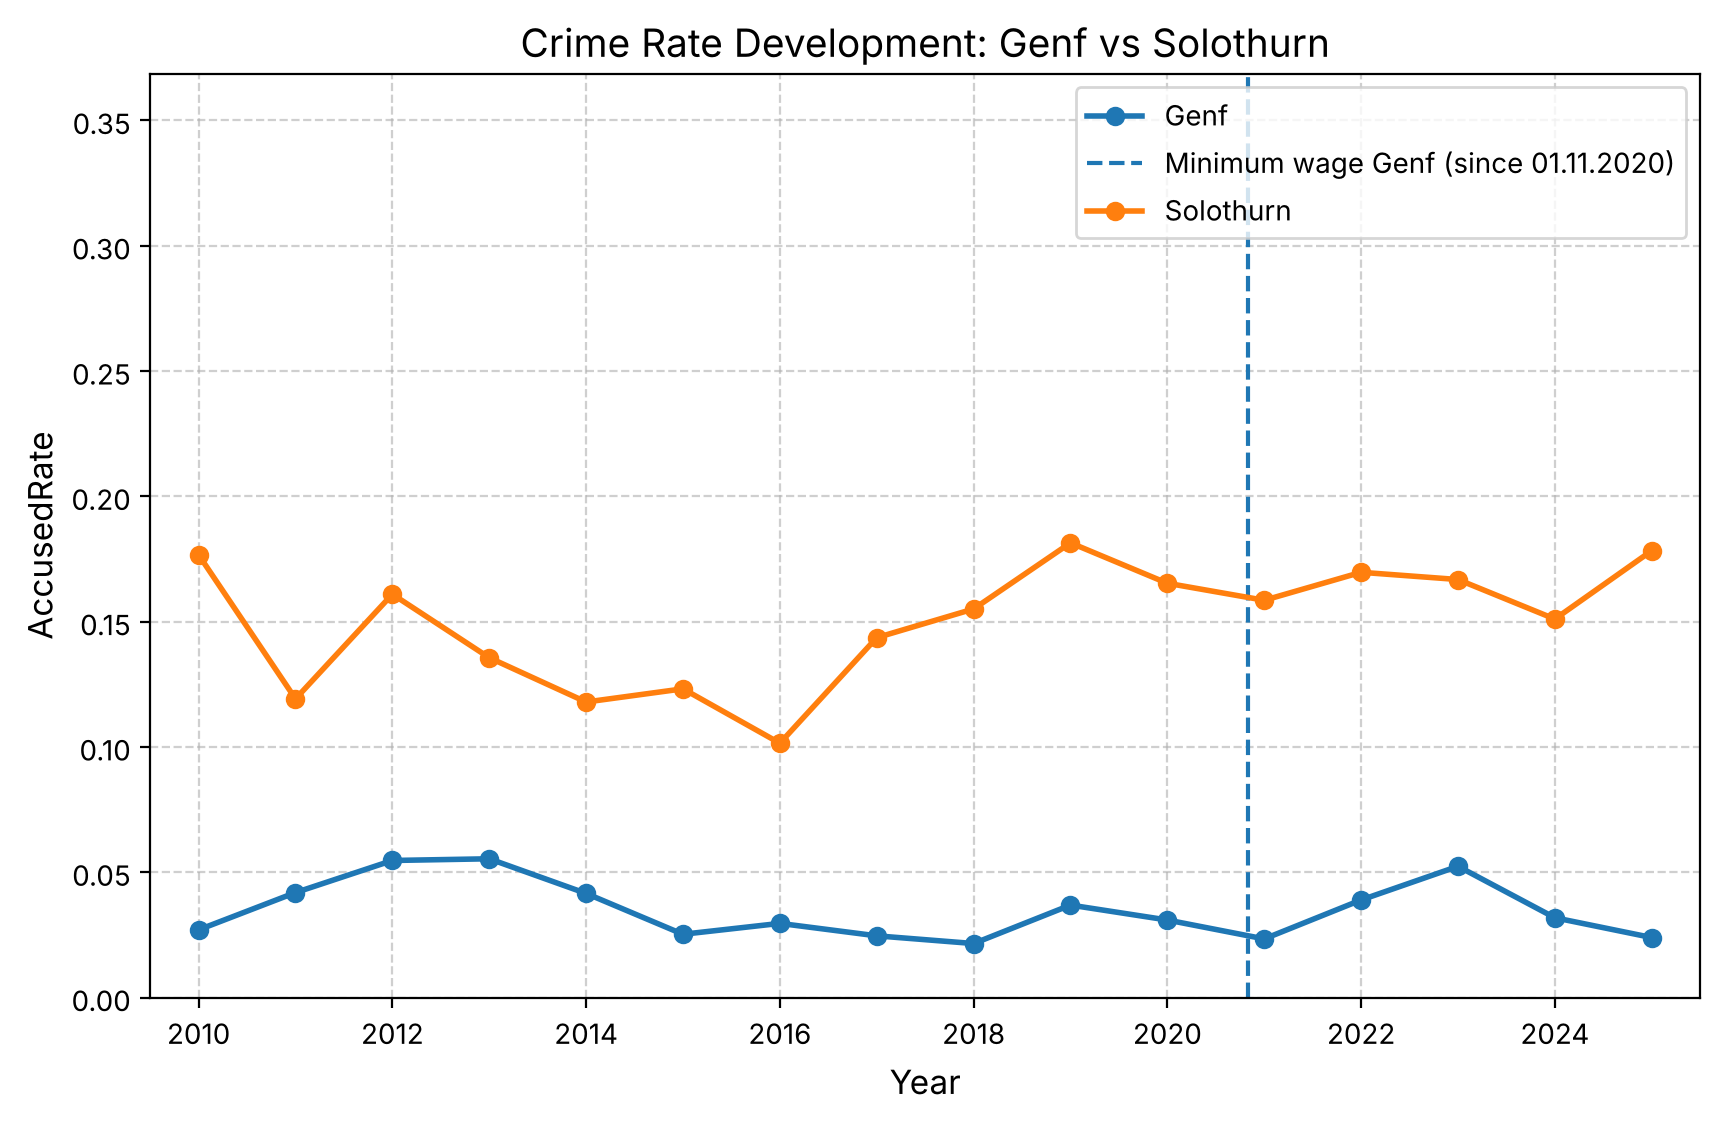

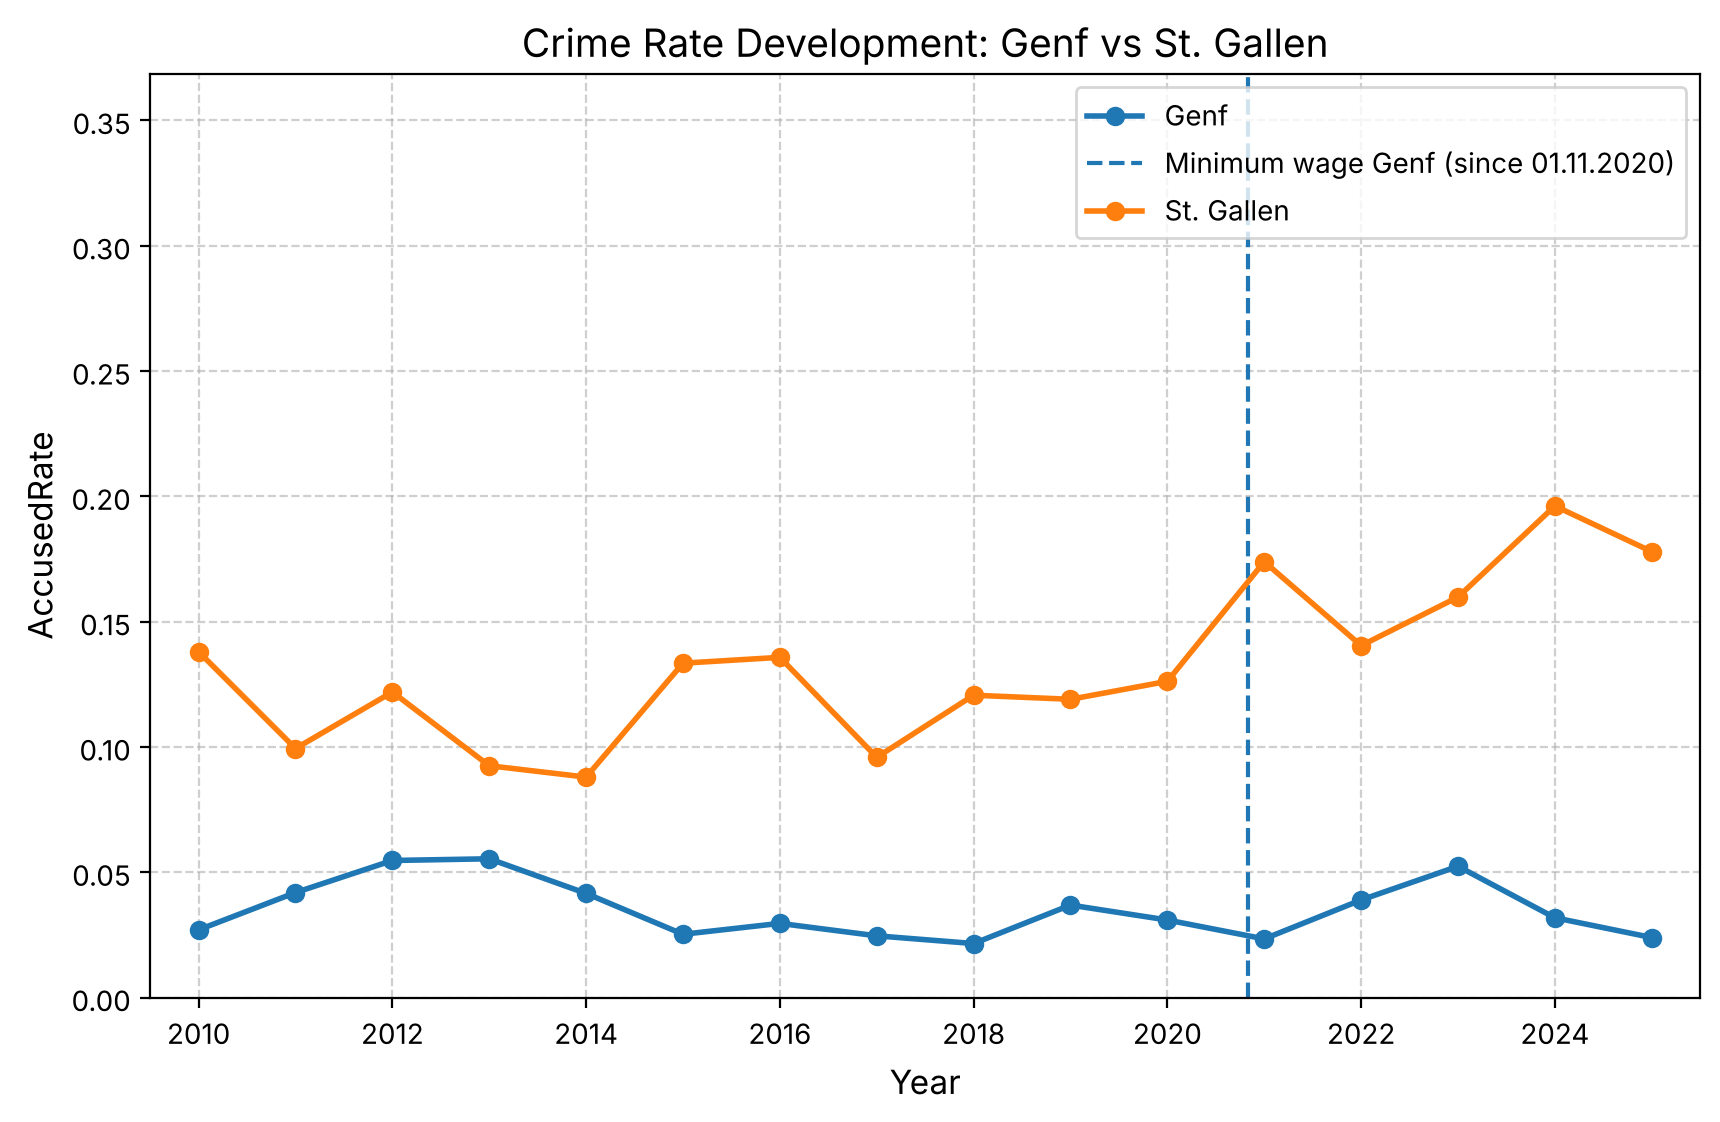

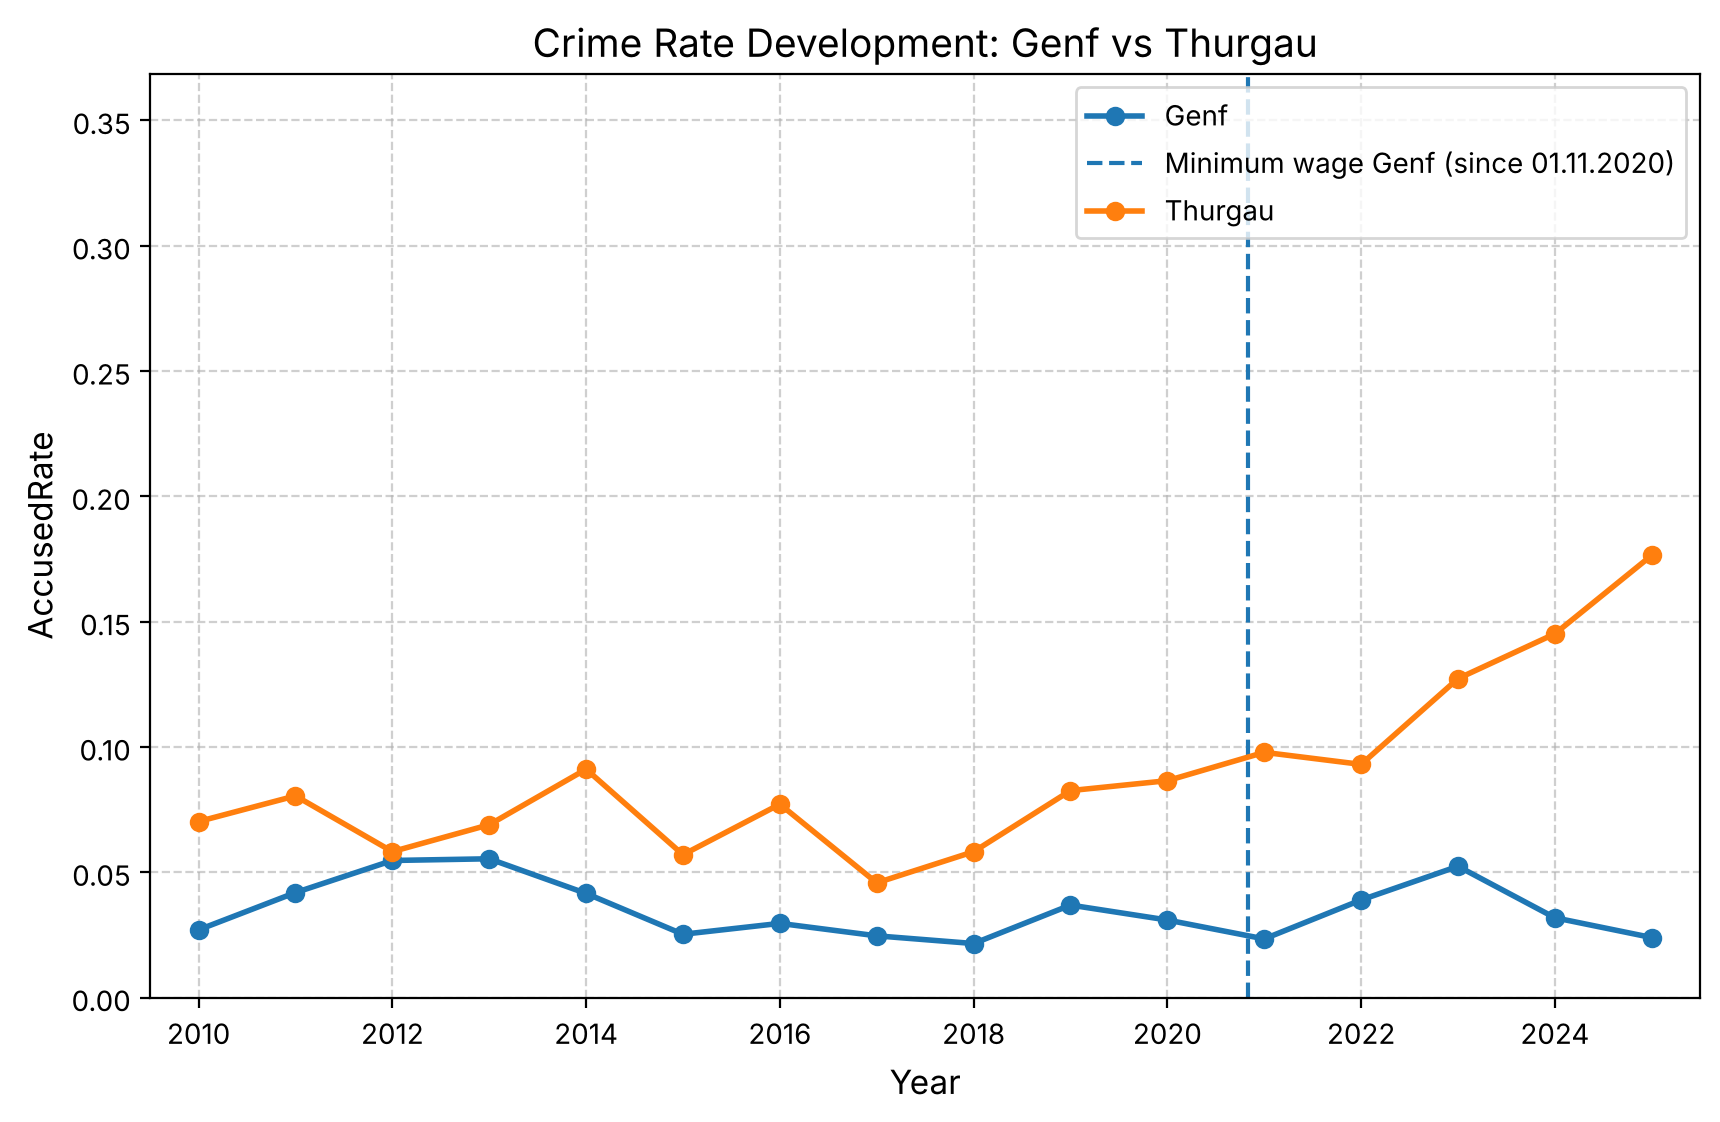

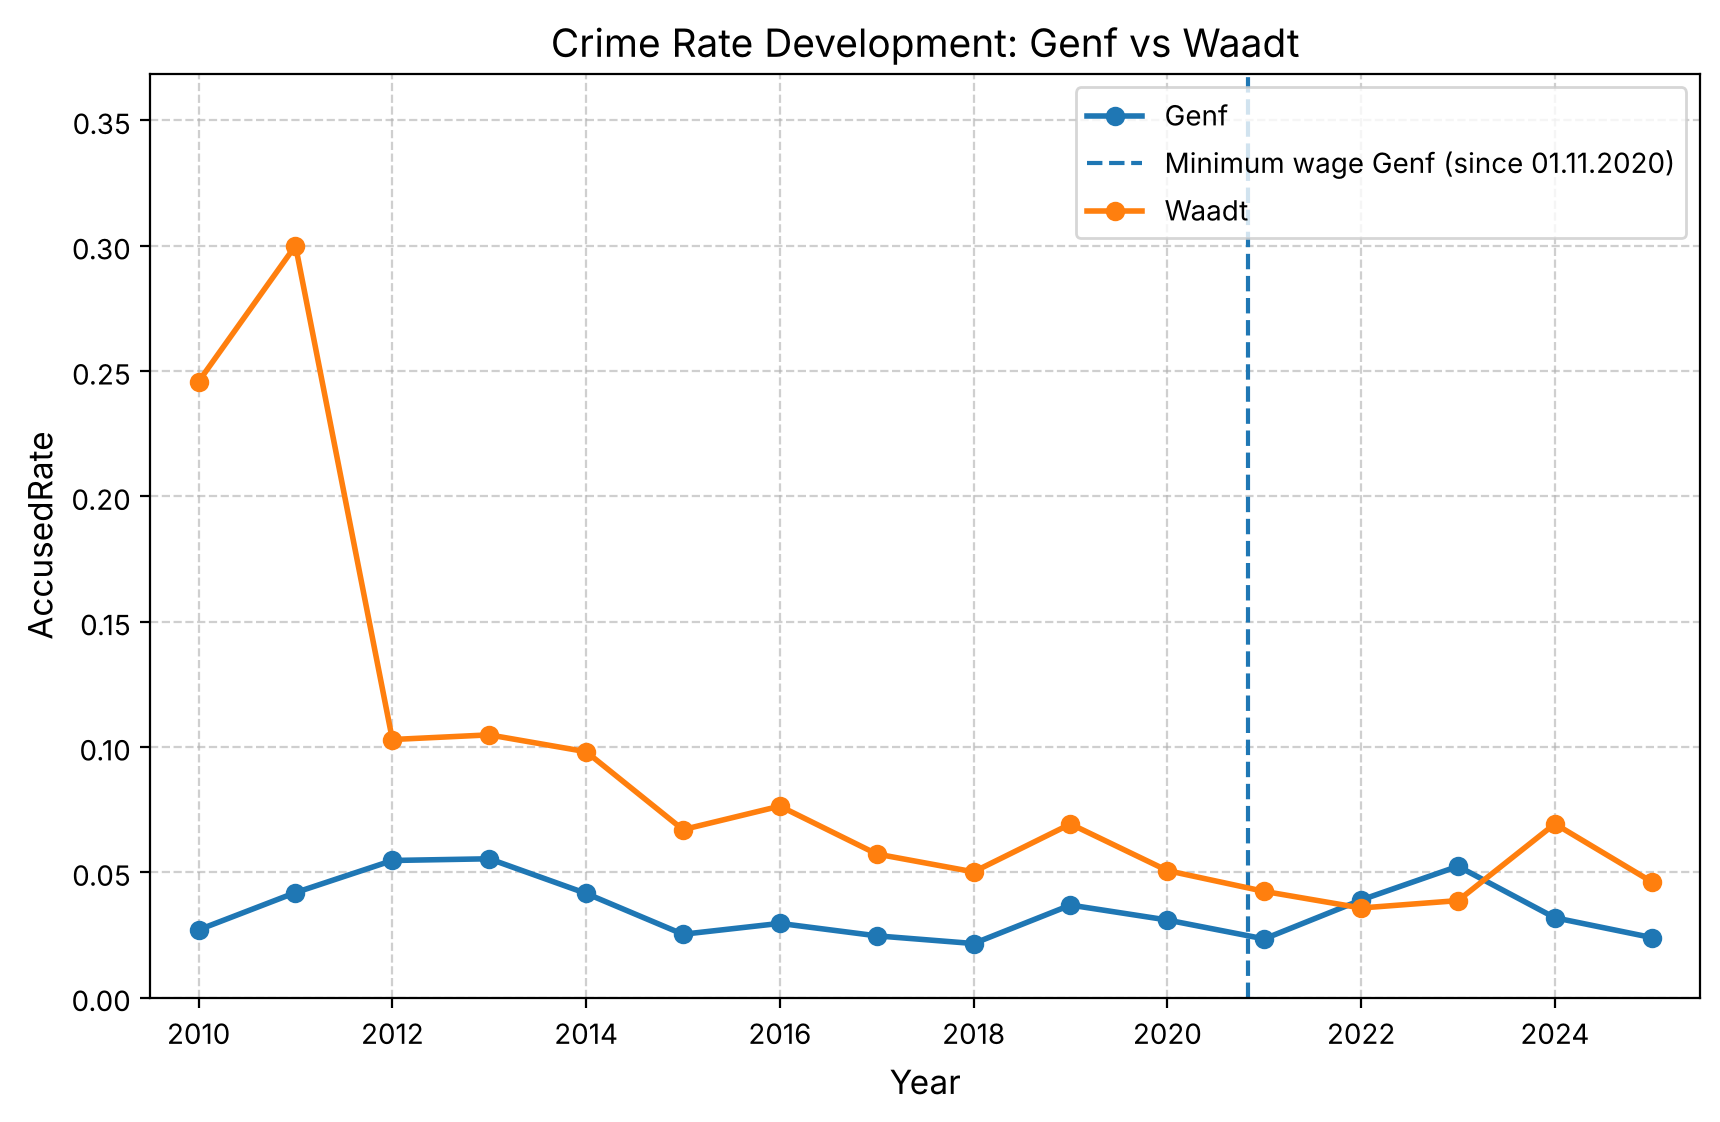

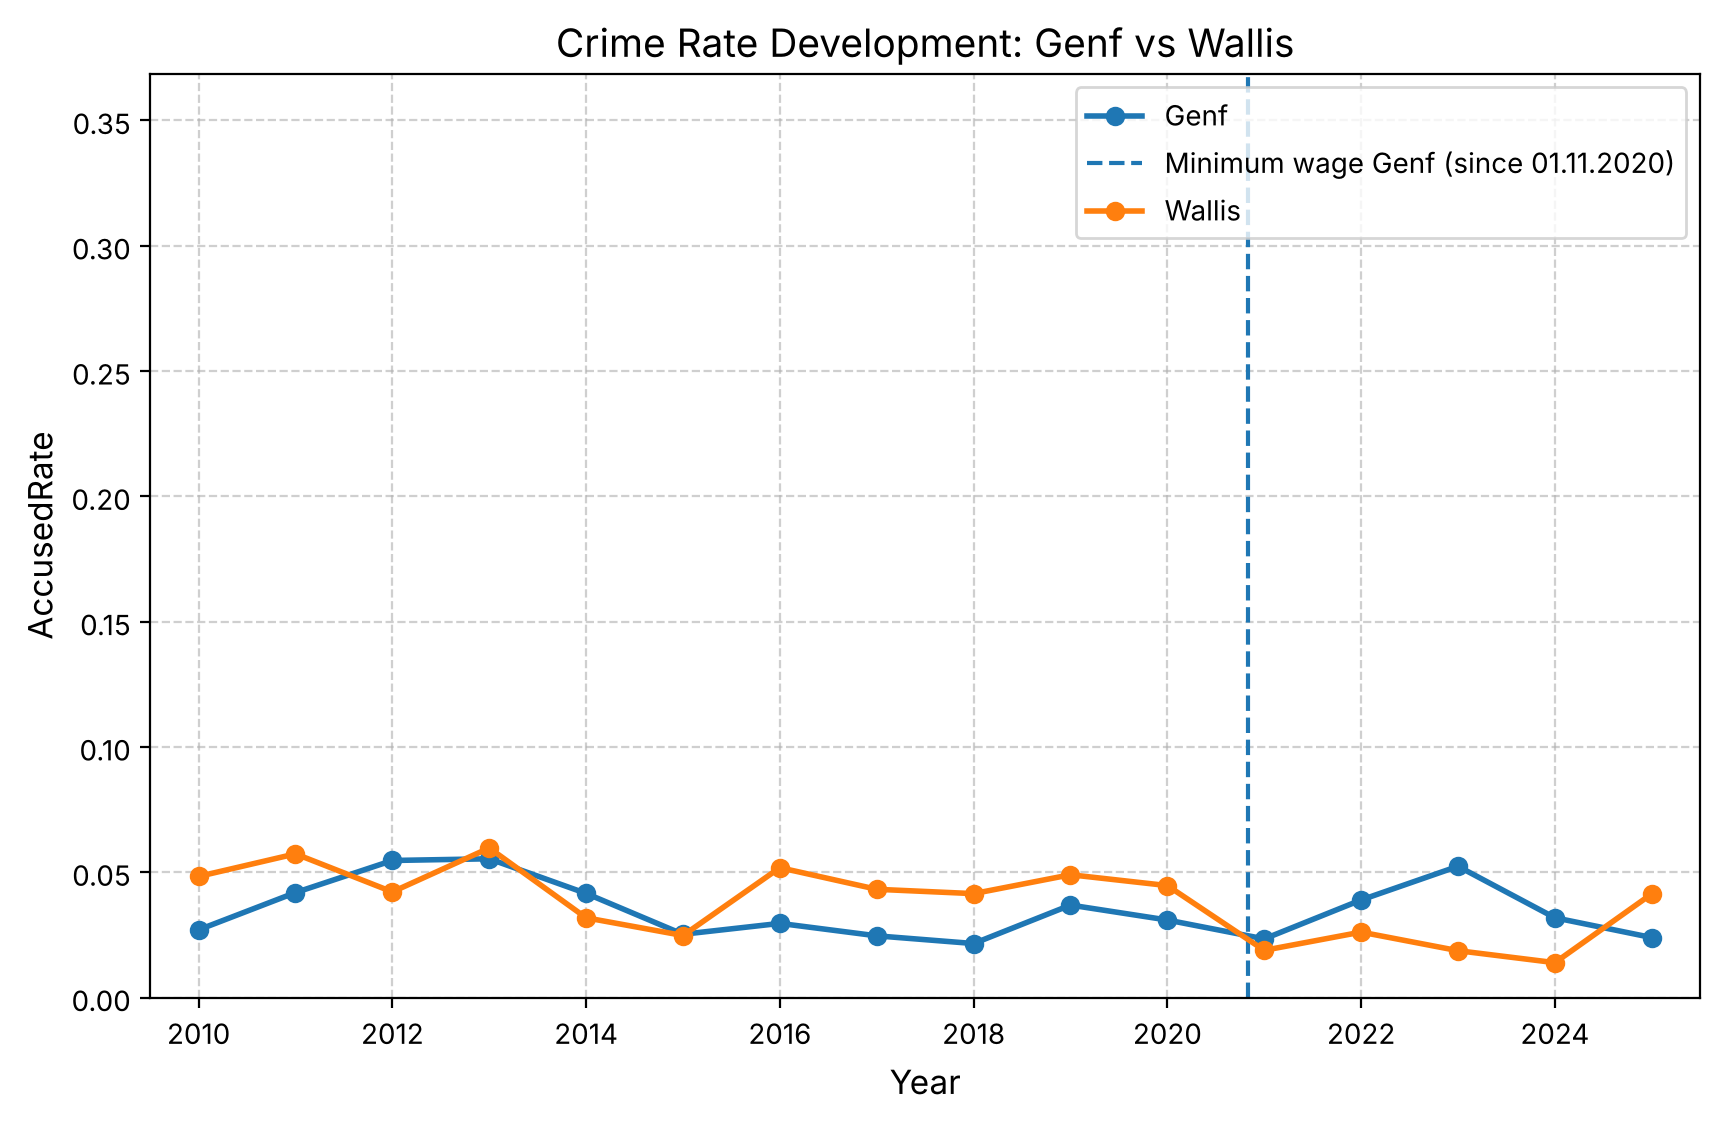

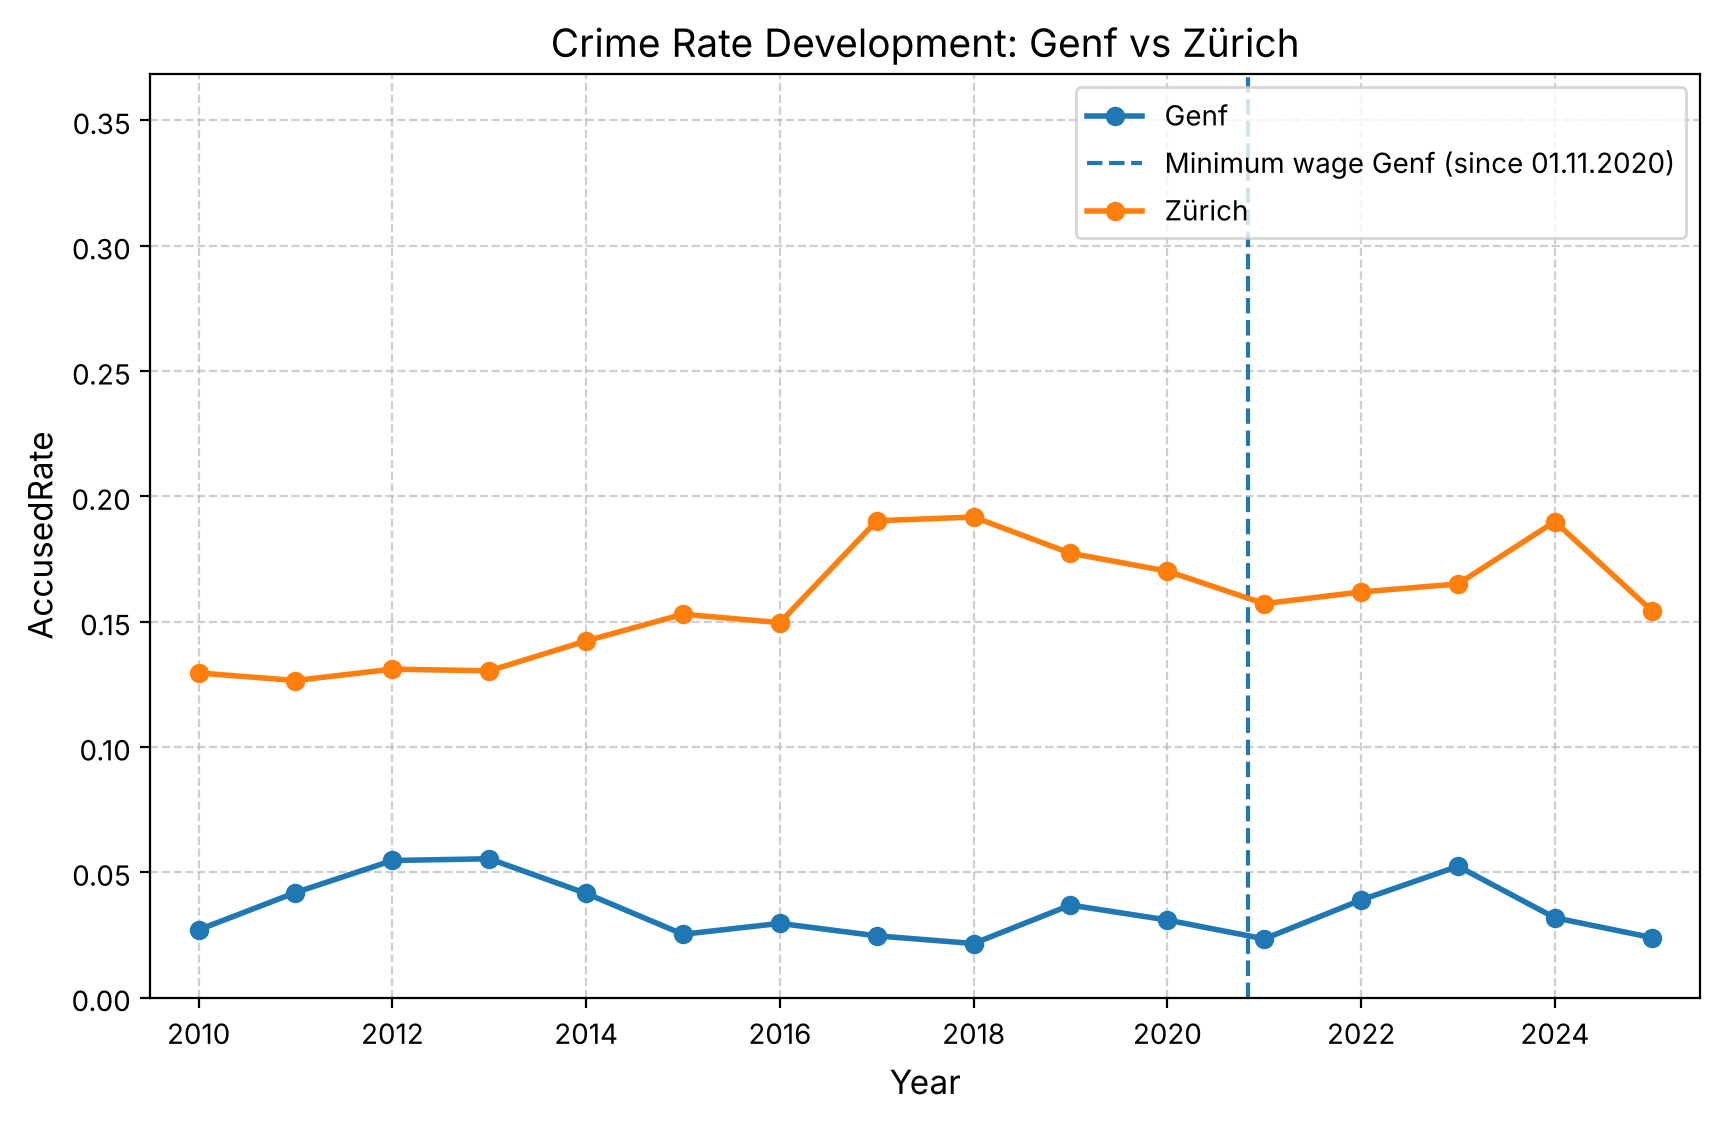

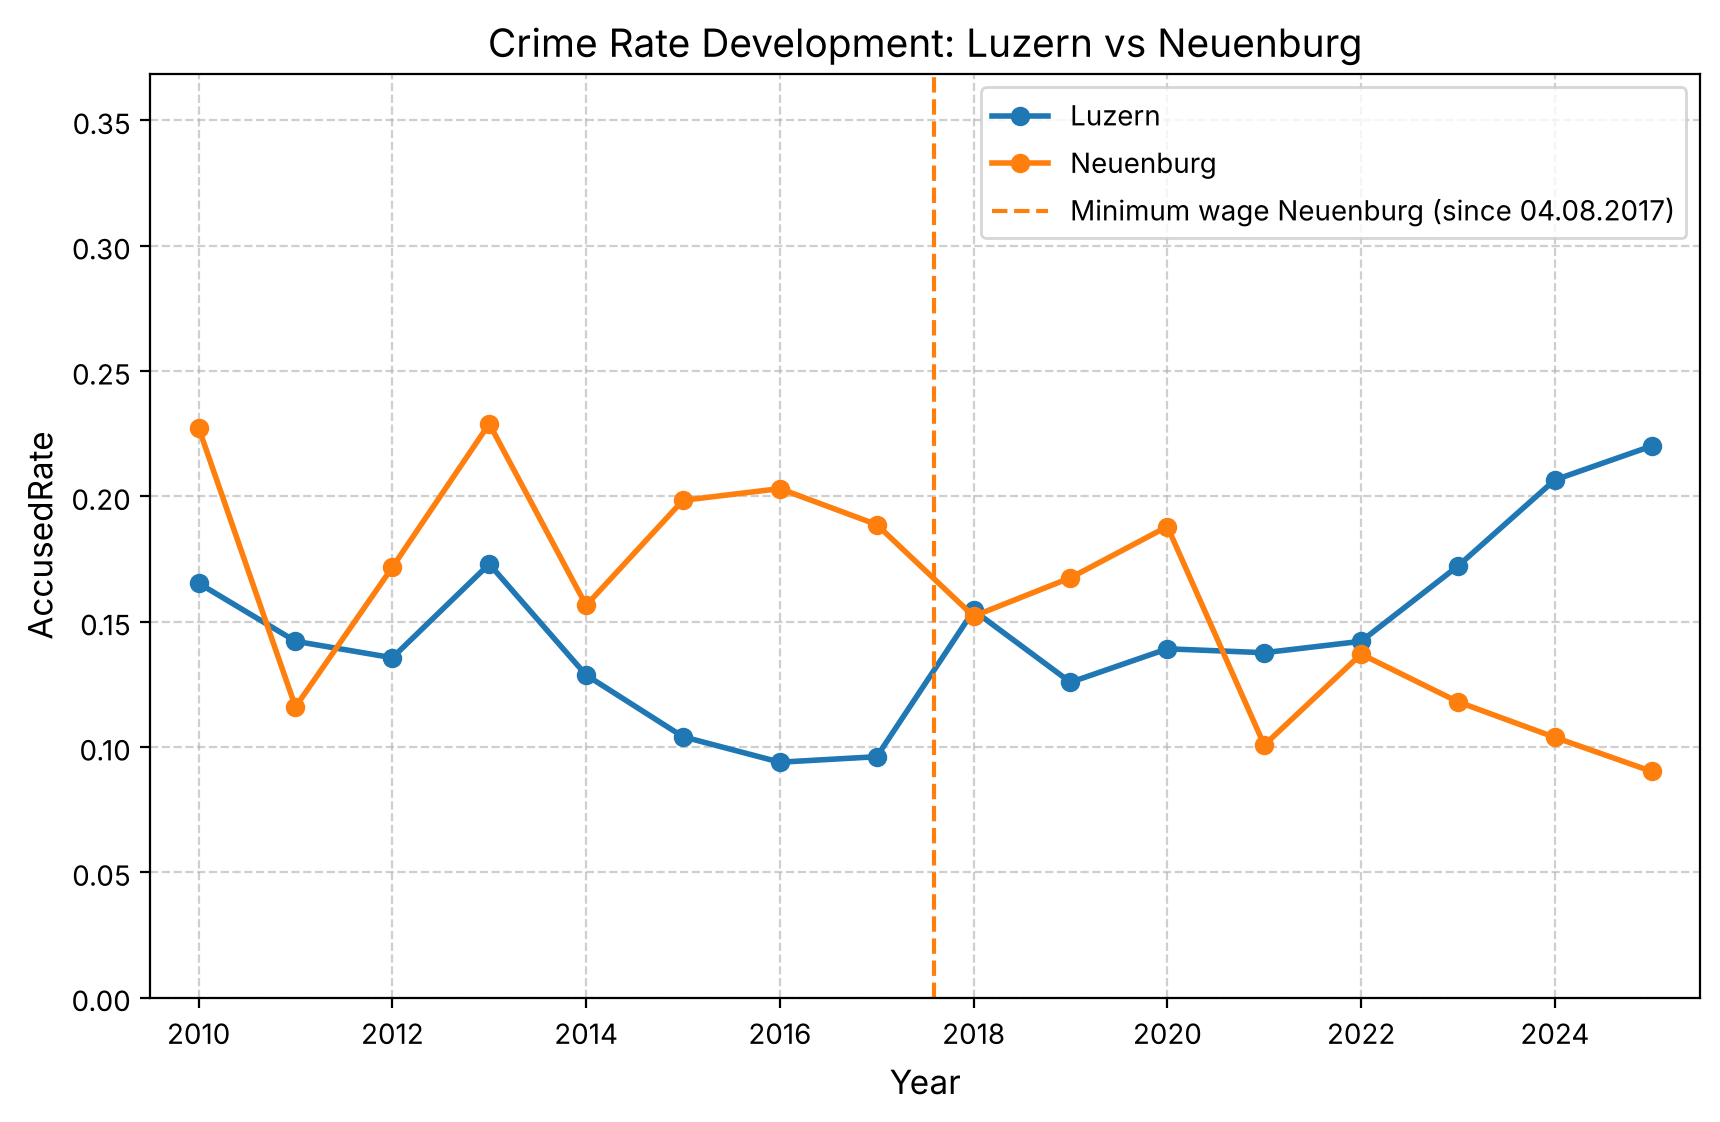

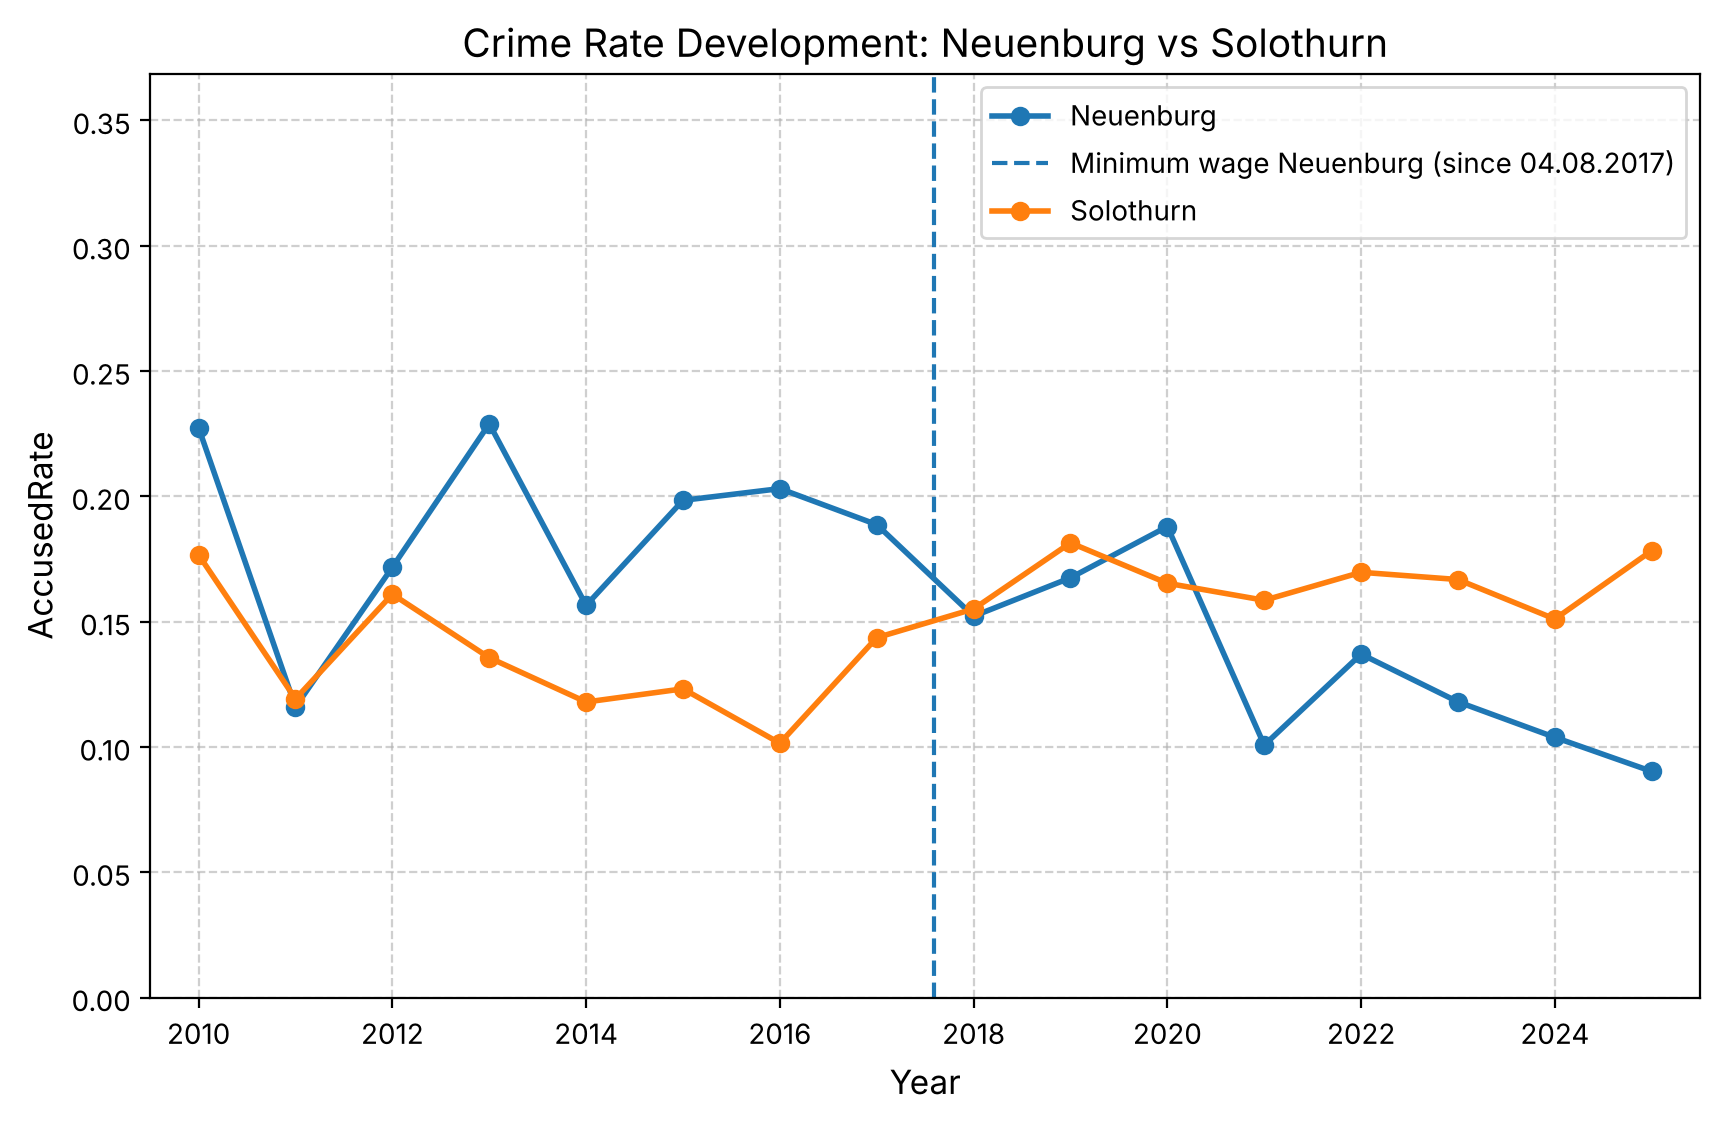

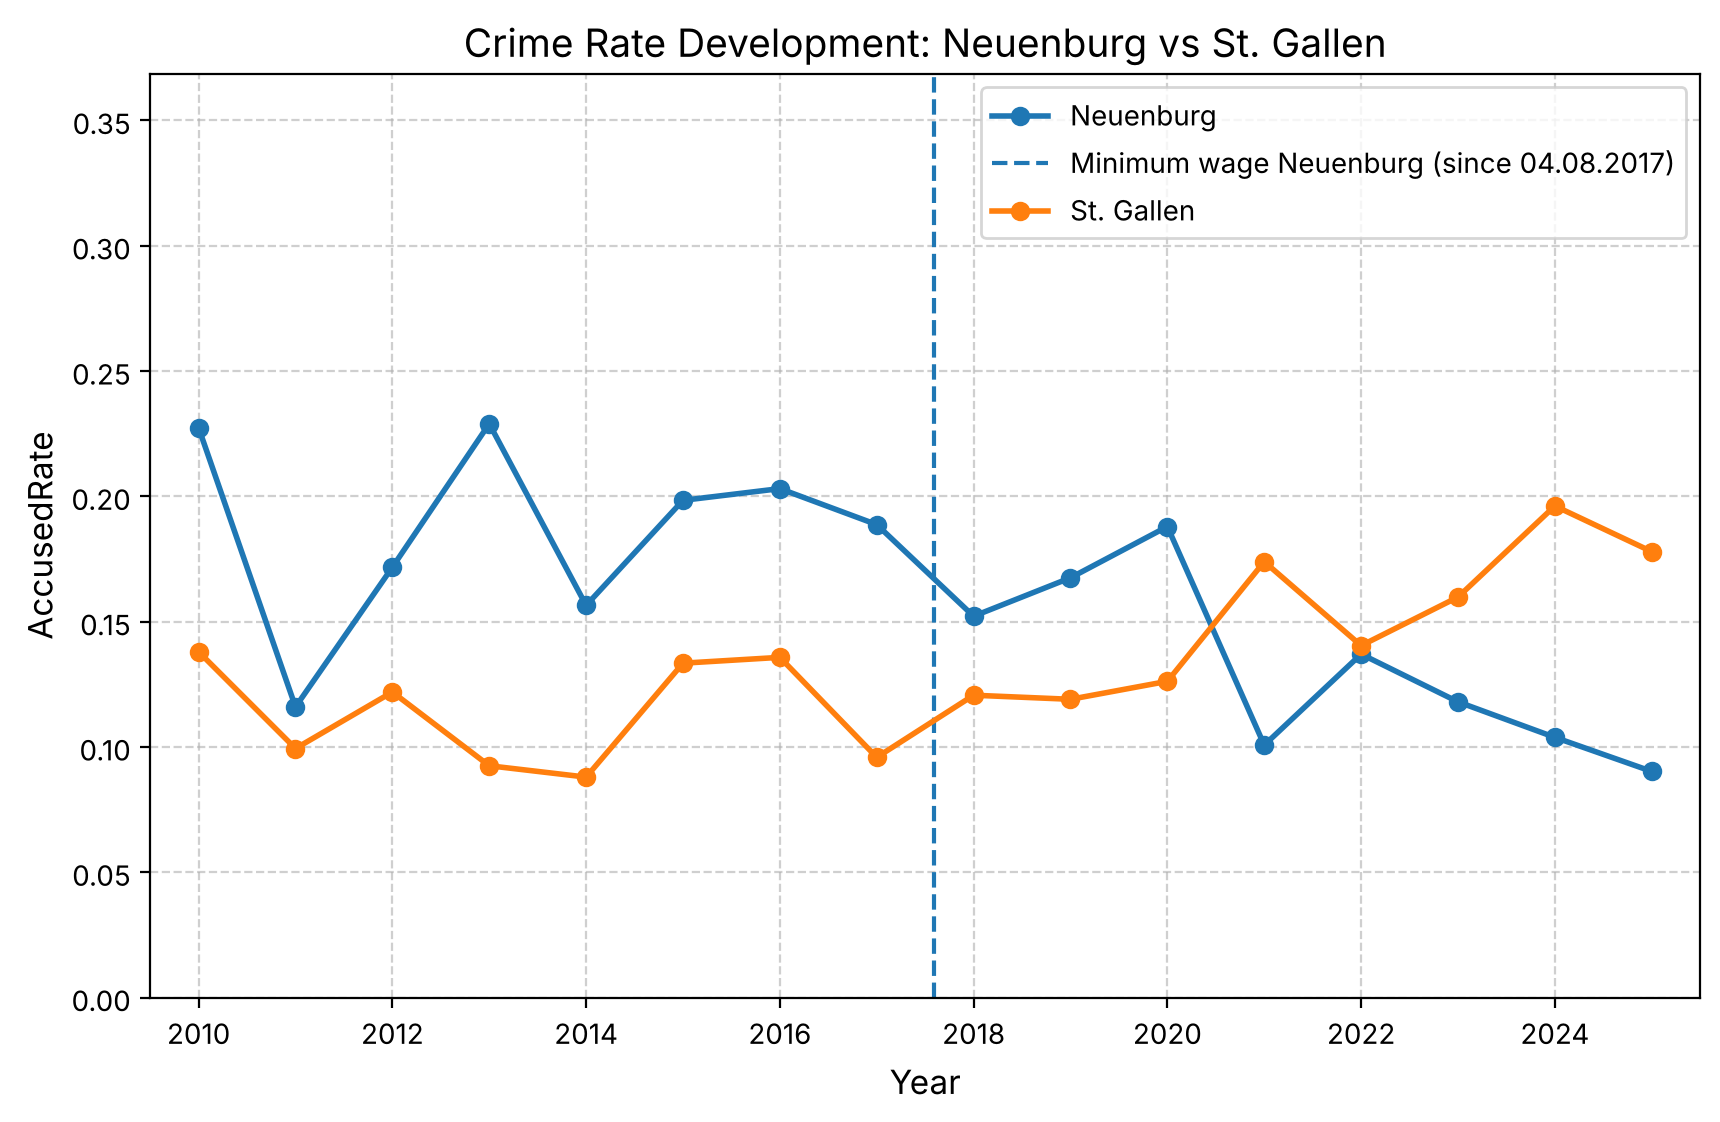

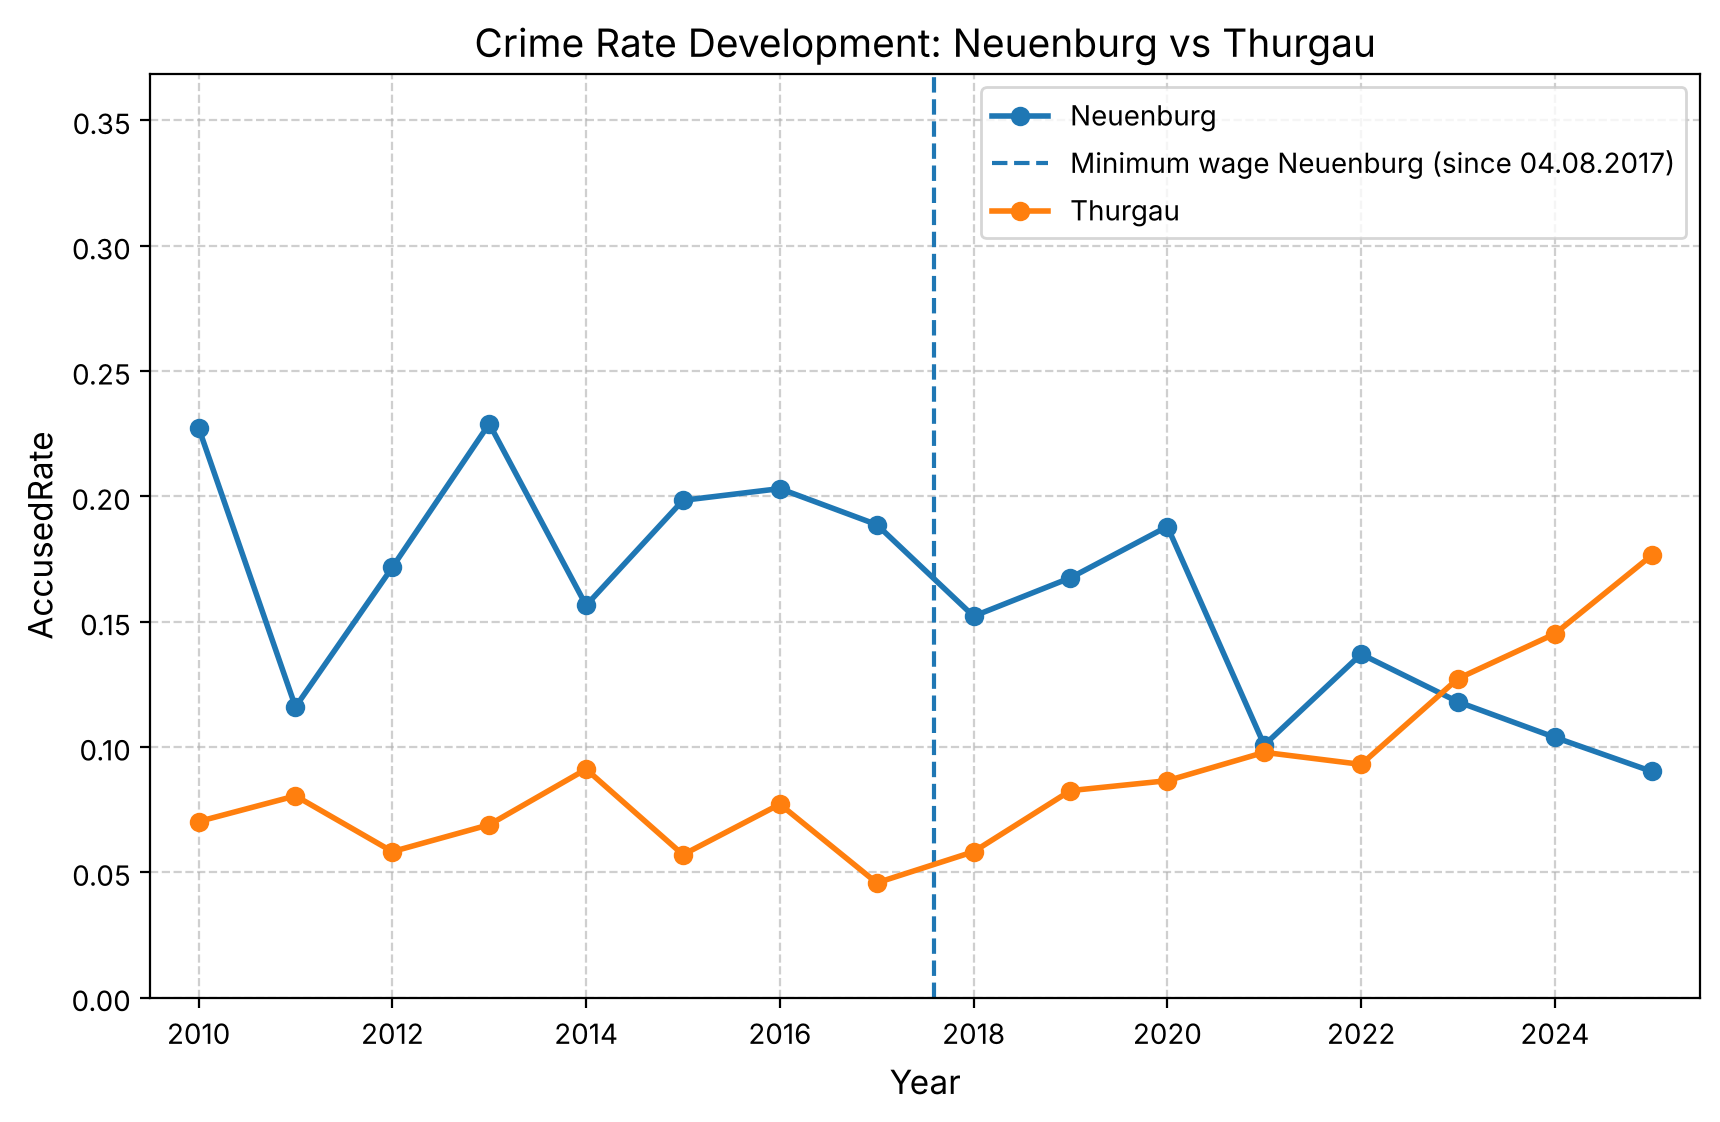

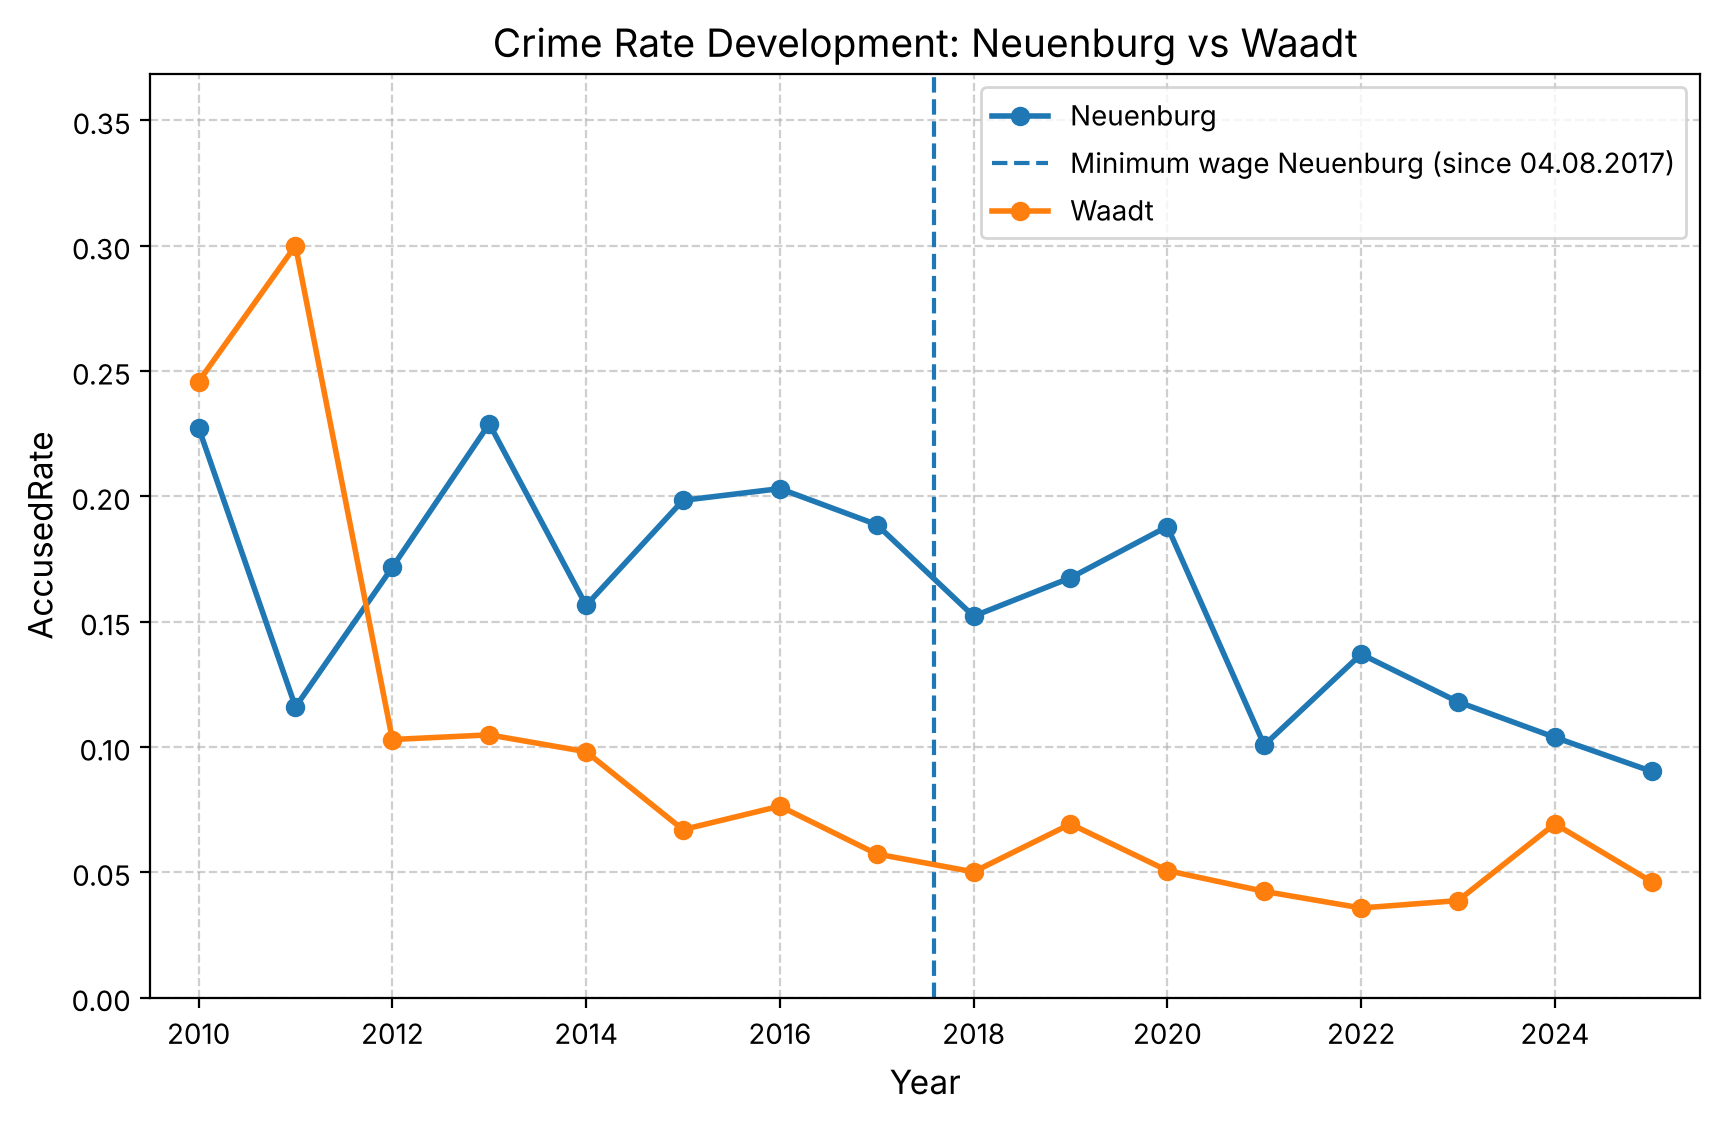

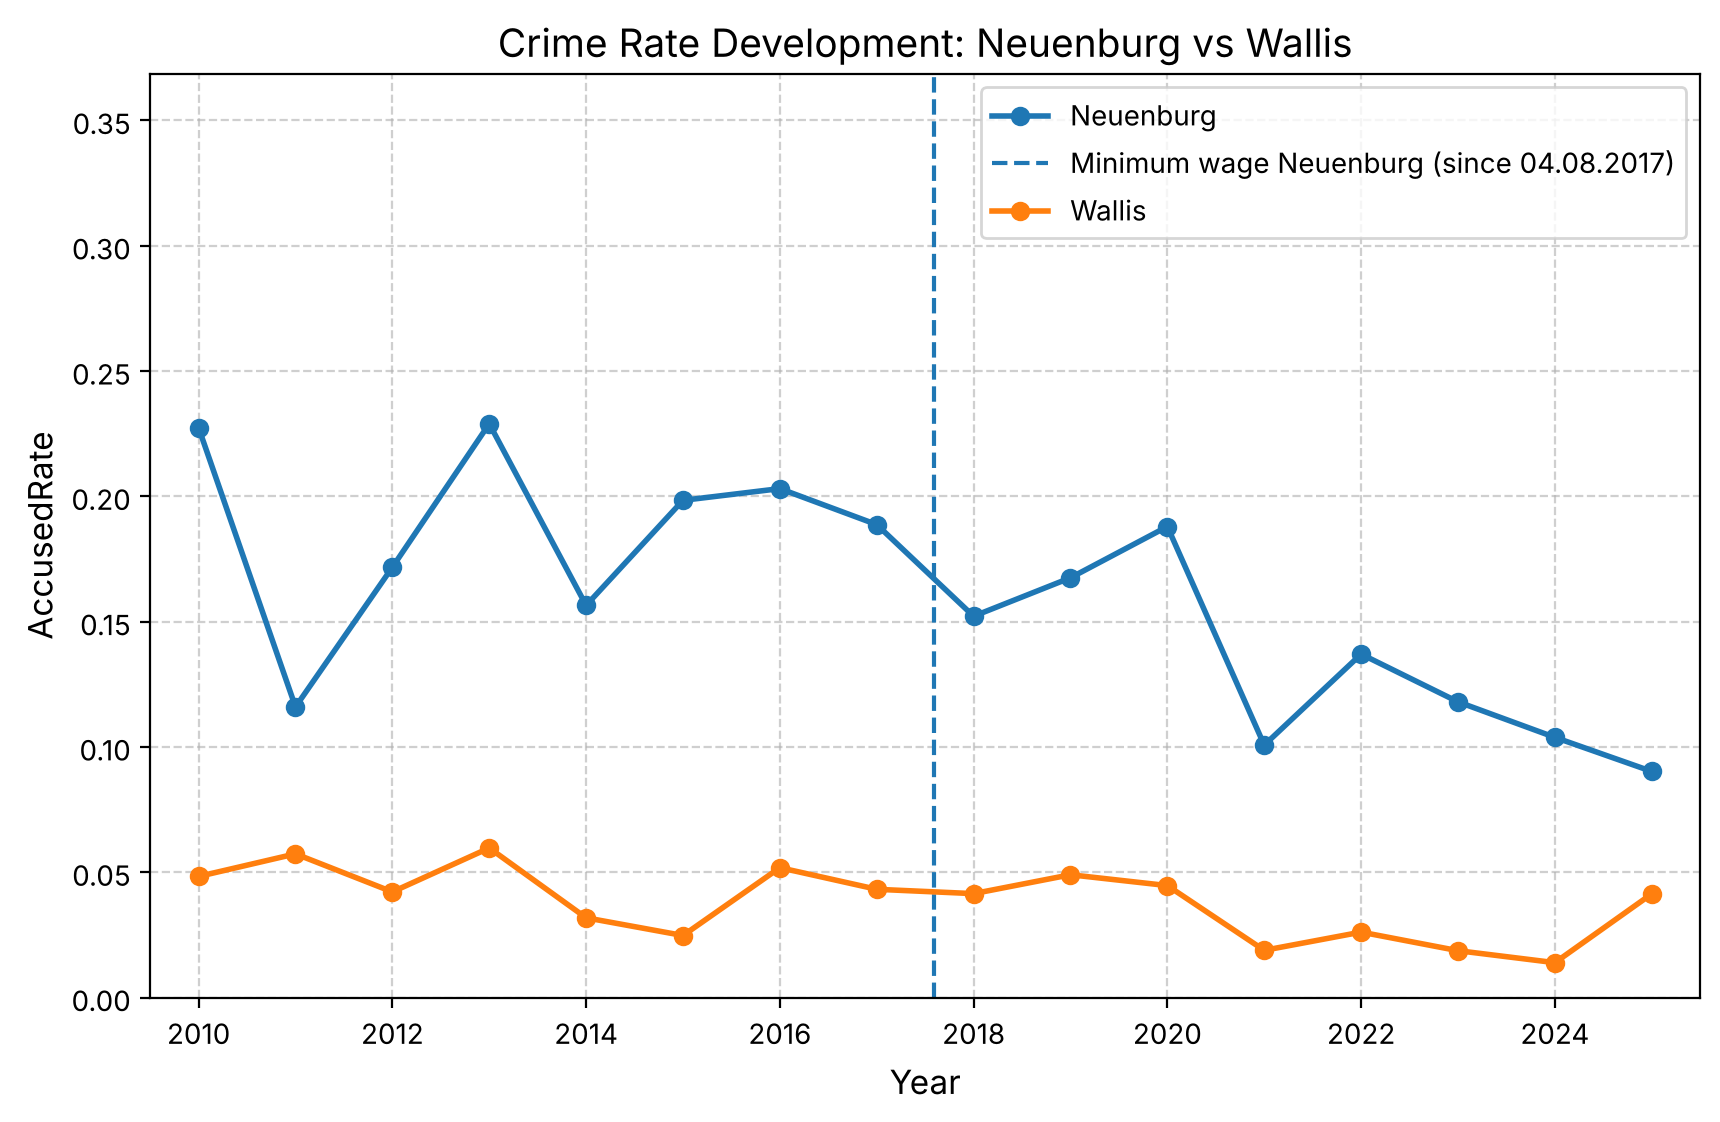

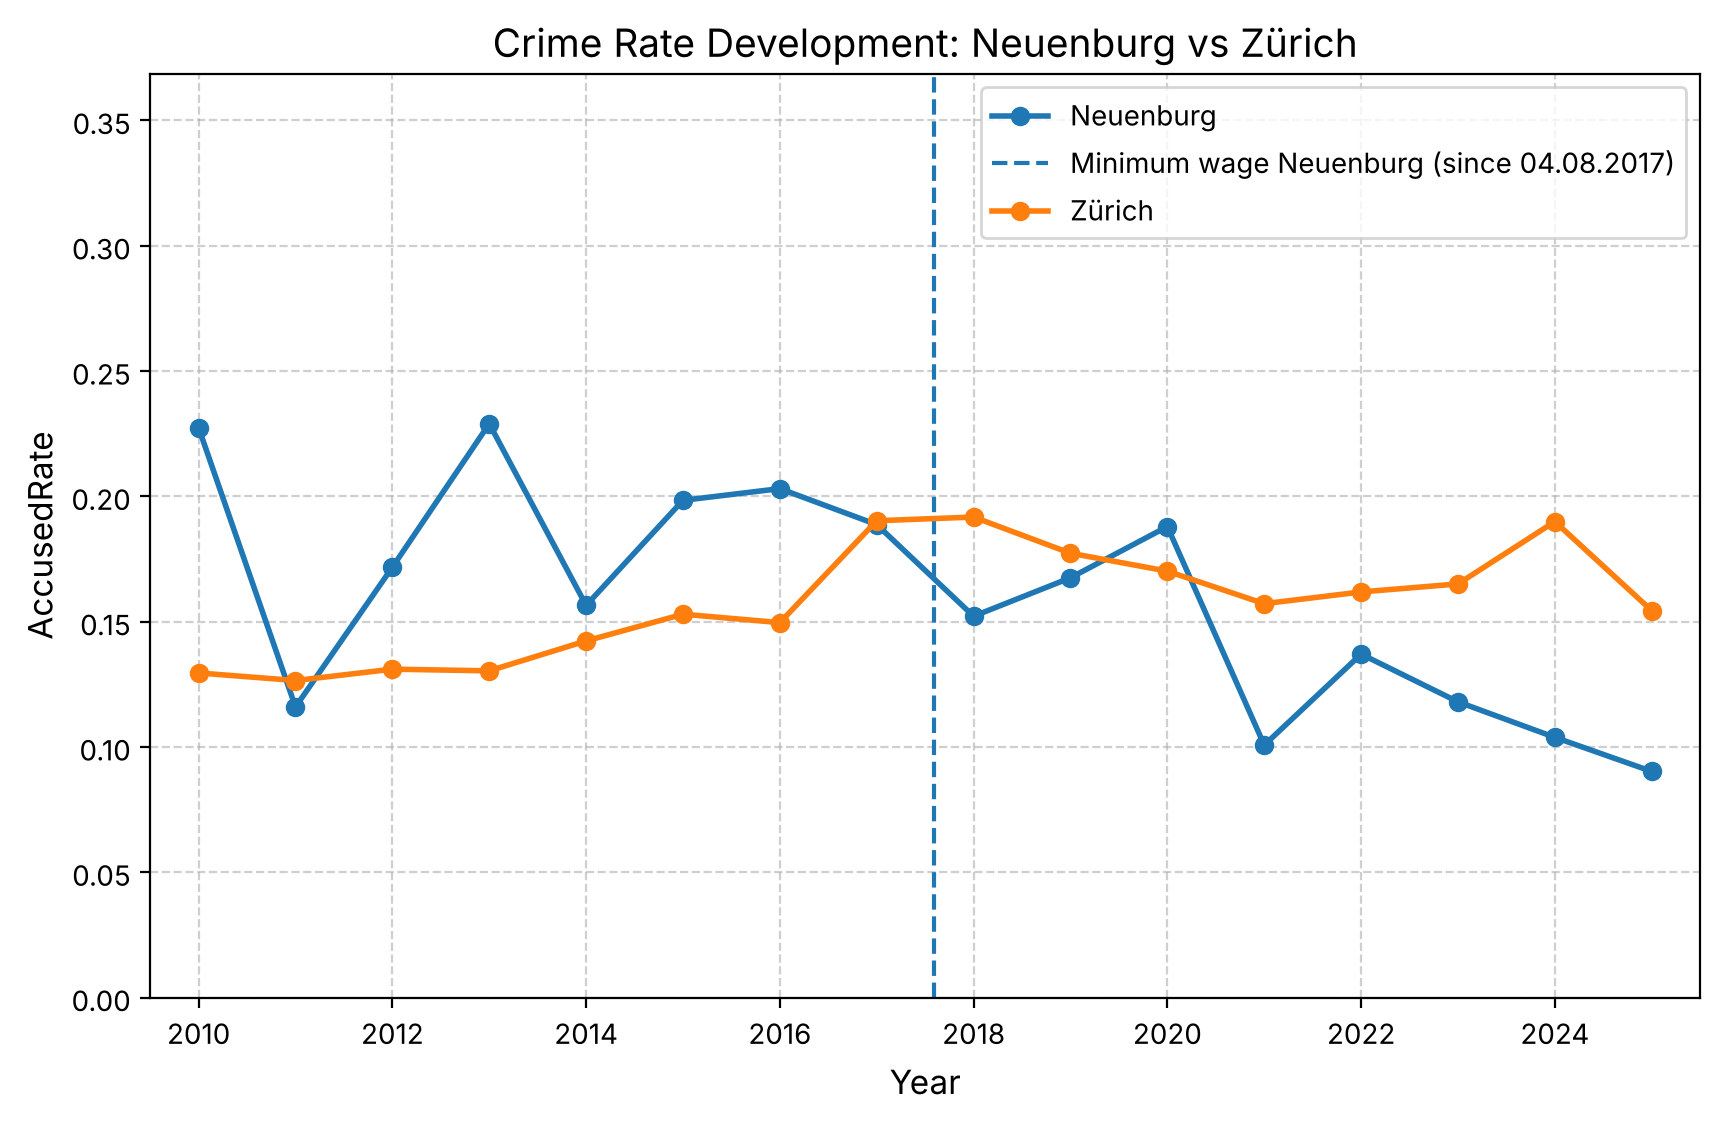

In [6]:
#exact date the minimum wage came into force
introduction_date = {
    "Neuenburg": "2017-08-04",
    "Genf": "2020-11-01",
    "Basel-Stadt": "2022-07-01",
}

#convert the date into a decimal year, e.g. 1 July 2022 -> 2022.5
#so the line sits between the yearly data points at the right position
def decimal_year(date_string):
    date = pd.Timestamp(date_string)
    days_in_year = 366 if date.is_leap_year else 365
    return date.year + (date.dayofyear - 1) / days_in_year

#same axes for every plot: from 0 to the highest rate of all cantons
y_max = data['AccusedRate'].max() * 1.05
x_min = data['Year'].min() - 0.5
x_max = data['Year'].max() + 0.5

for canton1, canton2 in combinations:
  
  # 1. Filter subset for the current pair of cantons
  subset = data[data['Canton'].isin([canton1, canton2])]

  # 2. Create a new canvas for each pair
  plt.figure(figsize=(10, 6))

  # 3. Plot both cantons onto the same graph
  for canton in [canton1, canton2]:
    canton_data = subset[subset['Canton'] == canton]
    line, = plt.plot(
        canton_data['Year'], 
        canton_data['AccusedRate'],
        marker='o', 
        linewidth=2, 
        label=canton
    )

    # 4. Vertical line in the year of introduction (same colour as the canton's line)
    if canton in introduction_date:
      plt.axvline(
          x=decimal_year(introduction_date[canton]),
          color=line.get_color(),
          linestyle='--',
          linewidth=1.5,
          label=f'Minimum wage {canton} (since {pd.Timestamp(introduction_date[canton]):%d.%m.%Y})'
      )

  # 5. Add titles, labels, and show the plot
  plt.title(f'Crime Rate Development: {canton1} vs {canton2}', fontsize=14)
  plt.xlabel('Year', fontsize=12)
  plt.ylabel('AccusedRate', fontsize=12)
  plt.ylim(0, y_max)
  plt.xlim(x_min, x_max)
  plt.legend(loc='upper right')
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.show()
